<div align="center">
  <img src="images.jpg" alt="Logo" width="220"/>
</div>

# Student & Project Information

- **Name:** Ahmed Mahmoud Khalifa
- **Track:** Data Science
- **Project Name:** Exploratory Data Analysis of The Netflix Catalog
- **Task:** Task 3
- **Repo:** [https://github.com/ahmedmahmoudkhalifa300/Synent-Technologies](https://github.com/ahmedmahmoudkhalifa300/Synent-Technologies)
- **GitHub:** [https://github.com/ahmedmahmoudkhalifa300](https://github.com/ahmedmahmoudkhalifa300)

---


# Exploratory Data Analysis of the Netflix Catalog
### Summary statistics, correlation analysis, trend identification and evidence-based insights

---

## 1. Project Overview

**Objective.** Identify important trends and patterns in the Netflix catalog using (1) summary statistics, (2) correlation analysis, (3) trend identification and (4) clear, evidence-based insights supported by graphs.

**Dataset.** `Dataset.csv` – a snapshot of titles available in the Netflix catalog with the columns `show_id`, `type`, `title`, `director`, `country`, `date_added`, `release_year`, `rating`, `duration` and `listed_in`. The file is located with a portable search strategy (see Section 3); no data are simulated or generated.

**Questions answered by this analysis**

1. What is the composition of the catalog (Movies vs TV Shows, ratings, countries, genres, directors)?
2. How has the number of titles **added** to Netflix (`date_added`) changed over time, and how has the Movie/TV mix changed?
3. How are catalog titles distributed by **release year** (`release_year`), and how old are titles when they are added?
4. How long are Movies (minutes) and how many seasons do TV Shows have – and do these change across periods?
5. Which meaningful numeric features are correlated, and how strongly?
6. How did the distribution and relative prevalence of content genres change across release years and decades?
7. Which content genres were most prevalent among older and newer releases?
8. Did the composition of Movies and TV Shows differ across release periods?

> **Important note on interpretation.** All findings in this notebook describe *associations and patterns in a catalog snapshot*. They do **not** prove causation, and they do not measure audience popularity, because the dataset contains no viewing, rating-score or engagement data.

## 2. Imports and Configuration

Only `pandas`, `numpy`, `matplotlib`, `seaborn` and the Python standard library are used. The cell below sets display options, a consistent plotting theme, the output folder for figures (`figures/`, relative to the notebook), the sample-size rules used throughout the analysis, and a few small helper functions.

In [3]:
%matplotlib inline

import os
import re
import math
import time
import calendar
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Display options -------------------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ---- Reproducible plotting theme ------------------------------------------
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({
    "figure.figsize": (11, 5.5),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
TYPE_ORDER = ["Movie", "TV Show"]
TYPE_COLORS = {"Movie": "#E50914", "TV Show": "#3A3A3A"}
BASE_COLOR = "#B20710"
SECOND_COLOR = "#5B5B5B"

# ---- Output folder (relative/portable path) --------------------------------
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RUN_START = time.time()          # used later to verify that figures were created in this run
FIGURES_CREATED = []             # registry of every saved figure
RESULTS = {}                     # computed metrics reused in the findings sections

# ---- Sample-size rules (stated once, used everywhere) ----------------------
MIN_N_TREND = 30        # min. observations per year/period for distribution statistics (durations, seasons, type mix)
MIN_TITLES_YEAR = 20    # min. titles per release year (or per type subgroup) for genre-share results
MIN_TITLES_PERIOD = 50  # earliest sparse decades are pooled until a release period holds at least this many titles

# Strings treated as "missing in disguise" (compared case-insensitively after stripping)
PLACEHOLDER_TOKENS = {"", "unknown", "n/a", "na", "null", "none", "nan", "not given",
                      "not available", "-", "--", "?"}
UNKNOWN_LABEL = "Unknown / Not Given"

# ---- Helper functions --------------------------------------------------------
def pct(part, whole):
    """Percentage with protection against division by zero."""
    return 100.0 * part / whole if whole else float("nan")

def save_fig(fig, filename):
    """Save a figure into figures/ (relative path), register it, and display it inline."""
    path = FIG_DIR / filename
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    if path.as_posix() not in FIGURES_CREATED:
        FIGURES_CREATED.append(path.as_posix())
    plt.show()
    return path

def interpret(observation, evidence, interpretation, limitation):
    """Render a structured, evidence-based interpretation directly below a chart."""
    display(Markdown(
        "#### Interpretation\n"
        f"- **Observation:** {observation}\n"
        f"- **Evidence:** {evidence}\n"
        f"- **Interpretation:** {interpretation}\n"
        f"- **Limitation:** {limitation}"
    ))

def is_placeholder(series):
    """True where a value is NaN, blank, or a common placeholder such as 'Unknown' / 'Not Given'."""
    s = series.astype("string").str.strip().str.lower()
    return (series.isna() | s.isin(PLACEHOLDER_TOKENS)).fillna(True).astype(bool)

def order_types(cols):
    """Known content types first (Movie, TV Show), any unexpected labels afterwards."""
    cols = list(cols)
    return [c for c in TYPE_ORDER if c in cols] + [c for c in cols if c not in TYPE_ORDER]

def strength(r):
    """Verbal label for the magnitude of a correlation coefficient."""
    if pd.isna(r):
        return "not computable"
    a = abs(r)
    if a < 0.10: return "negligible"
    if a < 0.30: return "weak"
    if a < 0.50: return "moderate"
    return "strong"

def annotate_barh(ax, values, total, fontsize=9):
    """Write 'count (share%)' at the end of each horizontal bar."""
    vmax = max(values) if len(values) else 0
    for patch, v in zip(ax.patches, values):
        ax.text(patch.get_width() + vmax * 0.01, patch.get_y() + patch.get_height() / 2,
                f"{int(v):,} ({pct(v, total):.1f}%)", va="center", fontsize=fontsize)
    ax.set_xlim(0, vmax * 1.22 if vmax else 1)

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__,
      "| matplotlib", plt.matplotlib.__version__)
print("Figures will be saved to:", FIG_DIR.as_posix() + "/")

pandas 3.0.5 | numpy 2.4.6 | seaborn 0.13.2 | matplotlib 3.11.2
Figures will be saved to: figures/


## 3. Load and Validate the Dataset

The file is located with a **portable search strategy**: an optional environment variable (`NETFLIX_DATASET_PATH`) is checked first, followed by `./Dataset.csv`, `../Dataset.csv`, `./data/Dataset.csv`, `../data/Dataset.csv` and `/home/ubuntu/upload/Dataset.csv`. The first existing file is used.

The CSV is read with `keep_default_na=False, na_values=[""]`: only truly empty cells become `NaN`, so that text placeholders such as `"N/A"`, `"null"` or `"Not Given"` remain visible and can be audited explicitly in Section 4 instead of being silently converted.

In [4]:
DATA_FILENAME = "Dataset.csv"

def locate_dataset(filename=DATA_FILENAME):
    """Return the first existing candidate path for the dataset, plus the list of searched paths."""
    candidates = []
    env_path = os.environ.get("NETFLIX_DATASET_PATH")
    if env_path:
        candidates.append(Path(env_path))
    candidates += [
        Path(".") / filename,
        Path("..") / filename,
        Path("data") / filename,
        Path("..") / "data" / filename,
        Path("/home/ubuntu/upload") / filename,
    ]
    for p in candidates:
        if p.is_file():
            return p, candidates
    raise FileNotFoundError(f"{filename} not found. Searched: {[c.as_posix() for c in candidates]}")

DATA_PATH, SEARCHED_PATHS = locate_dataset()

def read_csv_robust(path):
    """Read the CSV as UTF-8, falling back to latin-1 only if UTF-8 decoding fails."""
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(path, keep_default_na=False, na_values=[""], encoding=enc), enc
        except UnicodeDecodeError:
            continue
    raise ValueError("Unable to decode the file with the tried encodings.")

df_raw, ENCODING_USED = read_csv_robust(DATA_PATH)

# Fingerprint of the raw data, used at the end to prove df_raw was never mutated
RAW_FINGERPRINT = int(pd.util.hash_pandas_object(df_raw, index=True).sum())
RAW_SHAPE = df_raw.shape
RAW_DTYPES = df_raw.dtypes.astype(str).to_dict()

print("Searched paths      :", [p.as_posix() for p in SEARCHED_PATHS])
print("File path used      :", DATA_PATH.as_posix(), f"(resolved: {DATA_PATH.resolve().as_posix()})")
print("Encoding            :", ENCODING_USED)
print(f"Rows x Columns      : {df_raw.shape[0]:,} x {df_raw.shape[1]}")
print("Columns             :", list(df_raw.columns))
mem = df_raw.memory_usage(deep=True)
print(f"Memory usage (deep) : {mem.sum() / 1024**2:,.2f} MB")

Searched paths      : ['Dataset.csv', '../Dataset.csv', 'data/Dataset.csv', '../data/Dataset.csv', '/home/ubuntu/upload/Dataset.csv']
File path used      : ../Dataset.csv (resolved: D:/SYNENT/Dataset.csv)
Encoding            : utf-8
Rows x Columns      : 8,790 x 10
Columns             : ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']
Memory usage (deep) : 1.55 MB


In [5]:
print("Data types:")
display(df_raw.dtypes.astype(str).to_frame("dtype").T)
print("First five rows:")
display(df_raw.head())
print("Memory usage by column (KB, deep):")
display((mem / 1024).round(1).to_frame("KB").T)

Data types:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
dtype,str,str,str,str,str,str,int64,str,str,str


First five rows:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Memory usage by column (KB, deep):


,Index,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
KB,0.10,110.50,116.80,221.20,185.20,151.40,144.40,68.70,106.70,129.10,355.60


### 3.1 Data dictionary
A compact dictionary of every column: data type, non-null count and a short description.

In [6]:
DESCRIPTIONS = {
    "show_id": "Unique identifier of the catalog record",
    "type": "Content type: Movie or TV Show",
    "title": "Title of the movie or show",
    "director": "Director(s); may contain several names separated by commas",
    "country": "Country (or countries) of production",
    "date_added": "Date the title was added to Netflix (text in the raw file)",
    "release_year": "Year the title was originally released",
    "rating": "Audience/maturity rating (MPAA or TV Parental Guidelines)",
    "duration": "Runtime in minutes (Movies) or number of seasons (TV Shows)",
    "listed_in": "Netflix genres/categories, comma-separated (multi-label)",
}
data_dictionary = pd.DataFrame({
    "column": df_raw.columns,
    "dtype": [str(df_raw[c].dtype) for c in df_raw.columns],
    "non_null": [int(df_raw[c].notna().sum()) for c in df_raw.columns],
    "unique_values": [int(df_raw[c].nunique(dropna=False)) for c in df_raw.columns],
    "description": [DESCRIPTIONS.get(c, "(column not in the expected schema)") for c in df_raw.columns],
})
missing_expected = sorted(set(DESCRIPTIONS) - set(df_raw.columns))
print("Expected columns missing from file:", missing_expected if missing_expected else "none")
display(data_dictionary)

Expected columns missing from file: none


,column,dtype,non_null,unique_values,description
0,show_id,str,8790,8790,Unique identifier of the catalog record
1,type,str,8790,2,Content type: Movie or TV Show
2,title,str,8790,8787,Title of the movie or show
3,director,str,8790,4528,Director(s); may contain several names separat...
4,country,str,8790,86,Country (or countries) of production
5,date_added,str,8790,1713,Date the title was added to Netflix (text in t...
6,release_year,int64,8790,74,Year the title was originally released
7,rating,str,8790,14,Audience/maturity rating (MPAA or TV Parental ...
8,duration,str,8790,220,Runtime in minutes (Movies) or number of seaso...
9,listed_in,str,8790,513,"Netflix genres/categories, comma-separated (mu..."


## 4. Data-Quality Audit

All checks below are run on the **untouched raw data** (`df_raw`) *before* any cleaning. Every check is documented; unusual records are **reported, not removed**.

### 4.1 Missing values (true `NaN`)

In [7]:
N_RAW = len(df_raw)
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
})
display(missing.T)
print(f"Total missing cells: {int(missing['missing_count'].sum()):,} of {df_raw.size:,} "
      f"({pct(missing['missing_count'].sum(), df_raw.size):.2f}%)")

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
missing_count,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
missing_pct,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Total missing cells: 0 of 87,900 (0.00%)


### 4.2 Blank strings and placeholder values
Values such as `""`, `"Unknown"`, `"N/A"`, `"null"` or `"Not Given"` represent missing information even though they are not `NaN`. They are counted case-insensitively after stripping whitespace.

In [8]:
TEXT_COLS = [c for c in df_raw.columns
             if pd.api.types.is_object_dtype(df_raw[c]) or pd.api.types.is_string_dtype(df_raw[c])]

rows = []
for c in df_raw.columns:
    s = df_raw[c].dropna().astype(str)
    stripped = s.str.strip()
    lower = stripped.str.lower()
    blank = int((stripped == "").sum())
    ph_mask = lower.isin(PLACEHOLDER_TOKENS - {""})
    found = stripped[ph_mask].value_counts()
    rows.append({
        "column": c,
        "blank_strings": blank,
        "placeholder_count": int(ph_mask.sum()),
        "placeholder_pct": round(pct(ph_mask.sum(), N_RAW), 2),
        "placeholder_values_found": ", ".join(f"'{k}' ({v:,})" for k, v in found.items()) or "-",
        "leading/trailing_whitespace": int((s != stripped).sum()),
    })
placeholder_audit = pd.DataFrame(rows).set_index("column")
display(placeholder_audit)

effective_missing = (df_raw.isna().sum() + placeholder_audit["placeholder_count"] + placeholder_audit["blank_strings"])
display((effective_missing / N_RAW * 100).round(2).to_frame("effective_missing_pct (NaN + blank + placeholder)").T)

,blank_strings,placeholder_count,placeholder_pct,placeholder_values_found,leading/trailing_whitespace
column,,,,,
show_id,0,0,0.00,-,0
type,0,0,0.00,-,0
title,0,1,0.01,'Unknown' (1),1
director,0,2588,29.44,"'Not Given' (2,588)",0
country,0,287,3.27,'Not Given' (287),0
date_added,0,0,0.00,-,0
release_year,0,0,0.00,-,0
rating,0,0,0.00,-,0
duration,0,0,0.00,-,0


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
effective_missing_pct (NaN + blank + placeholder),0.00,0.00,0.01,29.44,3.27,0.00,0.00,0.00,0.00,0.00


### 4.3 Duplicates
Three levels are checked: (a) full-row duplicates, (b) duplicate `show_id`, (c) rows identical on every column **except** `show_id` (possible re-listings), and (d) repeated titles. Repeated titles are **not** treated as duplicates automatically – different works can share a name.

In [9]:
full_dup = int(df_raw.duplicated().sum())
id_dup = int(df_raw["show_id"].duplicated().sum()) if "show_id" in df_raw else None
content_cols = [c for c in df_raw.columns if c != "show_id"]
content_dup_mask = df_raw.duplicated(subset=content_cols, keep=False)
title_dup_mask = df_raw["title"].duplicated(keep=False)

dup_summary = pd.DataFrame({
    "check": ["Full-row duplicates", "Duplicate show_id",
              "Rows identical except show_id (all copies)", "Rows sharing a title with another row"],
    "count": [full_dup, id_dup, int(content_dup_mask.sum()), int(title_dup_mask.sum())],
})
display(dup_summary)
print("Rows that are identical except for show_id (kept; reported for transparency):")
display(df_raw[content_dup_mask].sort_values("title"))
RESULTS["full_dup"] = full_dup
RESULTS["id_dup"] = id_dup
RESULTS["content_dup_rows"] = int(content_dup_mask.sum())

,check,count
0,Full-row duplicates,0
1,Duplicate show_id,0
2,Rows identical except show_id (all copies),6
3,Rows sharing a title with another row,6


Rows that are identical except for show_id (kept; reported for transparency):


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
393,s3997,TV Show,9-Feb,Not Given,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
537,s5965,TV Show,9-Feb,Not Given,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"


### 4.4 Unique-value counts for every column

In [10]:
display(df_raw.nunique(dropna=False).to_frame("unique_values (incl. NaN)").T)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
unique_values (incl. NaN),8790,2,8787,4528,86,1713,74,14,220,513


### 4.5 Validity and range checks for `release_year`

In [11]:
ry_raw = pd.to_numeric(df_raw["release_year"], errors="coerce")
ry_non_numeric = int(ry_raw.isna().sum() - df_raw["release_year"].isna().sum())
ry_non_integer = int((ry_raw.dropna() % 1 != 0).sum())
ry_too_old = int((ry_raw < 1900).sum())
# Upper bound: no title should be released after the latest date_added in the file
_latest_added = pd.to_datetime(df_raw["date_added"].astype("string").str.strip(), format="%m/%d/%Y", errors="coerce").max()
ry_upper = _latest_added.year if pd.notna(_latest_added) else pd.Timestamp.today().year
ry_future = int((ry_raw > ry_upper).sum())

display(ry_raw.describe().to_frame("release_year").T)
display(pd.DataFrame({
    "check": ["Non-numeric values", "Non-integer values", "Year < 1900",
              f"Year > latest date_added year ({ry_upper})"],
    "count": [ry_non_numeric, ry_non_integer, ry_too_old, ry_future],
}))
print("Oldest 5 titles (plausible historic content, kept):")
display(df_raw.assign(_ry=ry_raw).nsmallest(5, "_ry")[["show_id", "type", "title", "release_year", "date_added"]])

,count,mean,std,min,25%,50%,75%,max
release_year,"8,790.00","2,014.18",8.83,"1,925.00","2,013.00","2,017.00","2,019.00","2,021.00"


,check,count
0,Non-numeric values,0
1,Non-integer values,0
2,Year < 1900,0
3,Year > latest date_added year (2021),0


Oldest 5 titles (plausible historic content, kept):


,show_id,type,title,release_year,date_added
421,s4251,TV Show,Pioneers: First Women Filmmakers*,1925,12/30/2018
5698,s7791,Movie,Prelude to War,1942,3/31/2017
6037,s8206,Movie,The Battle of Midway,1942,3/31/2017
6422,s8661,Movie,Undercover: How to Operate Behind Enemy Lines,1943,3/31/2017
6491,s8740,Movie,Why We Fight: The Battle of Russia,1943,3/31/2017


### 4.6 Parsing failures for `date_added`
The observed format is `month/day/year` (e.g. `9/25/2021`). Parsing is first attempted with this explicit format; any failures are reported (and, in Section 5, a flexible fallback parser is tried before a value is left as missing).

In [12]:
DATE_FORMAT = "%m/%d/%Y"
date_str_raw = df_raw["date_added"].astype("string").str.strip()
parsed_strict = pd.to_datetime(date_str_raw, format=DATE_FORMAT, errors="coerce")
date_present = date_str_raw.notna() & (date_str_raw != "")
date_fail_mask = parsed_strict.isna() & date_present

print(f"date_added values present          : {int(date_present.sum()):,}")
print(f"Parsed with format {DATE_FORMAT}     : {int(parsed_strict.notna().sum()):,}")
print(f"Parsing failures (non-empty values): {int(date_fail_mask.sum()):,}")
print(f"Date range                         : {parsed_strict.min().date()} to {parsed_strict.max().date()}")
if date_fail_mask.any():
    display(df_raw.loc[date_fail_mask, ["show_id", "title", "date_added"]].head(20))

date_added values present          : 8,790
Parsed with format %m/%d/%Y     : 8,790
Parsing failures (non-empty values): 0
Date range                         : 2008-01-01 to 2021-09-25


### 4.7 Suspicious or inconsistent values in `type`, `rating` and `duration`
Checks: unexpected `type` labels; ratings outside the standard MPAA/TV Parental Guidelines set or ratings that look like durations (a known issue in some Netflix files); durations that do not match `<number> min` / `<number> Season(s)`; unit/type mismatches (e.g. a Movie measured in seasons); singular/plural mismatches; and extreme but possibly valid movie lengths.

In [13]:
# --- type ---------------------------------------------------------------------
type_vc = df_raw["type"].value_counts(dropna=False)
unexpected_types = [t for t in type_vc.index if t not in TYPE_ORDER]
print("type value counts:"); display(type_vc.to_frame("count").T)
print("Unexpected type labels:", unexpected_types if unexpected_types else "none")

# --- rating -------------------------------------------------------------------
KNOWN_RATINGS = {"G", "PG", "PG-13", "R", "NC-17", "NR", "UR",
                 "TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "TV-PG", "TV-14", "TV-MA"}
rating_vc = df_raw["rating"].value_counts(dropna=False)
unexpected_ratings = [r for r in rating_vc.index if r not in KNOWN_RATINGS]
rating_looks_like_duration = int(df_raw["rating"].astype("string").str.contains(r"\d+\s*min", case=False, na=False).sum())
print("\nrating value counts:"); display(rating_vc.to_frame("count").T)
print("Ratings outside the standard set:", unexpected_ratings if unexpected_ratings else "none")
print("Ratings that look like durations ('xx min'):", rating_looks_like_duration)
print("Note: 'NR' (Not Rated) and 'UR' (Unrated) are semantically similar; they are kept as separate labels.")
print("\nRating x type (movie-style ratings on TV Shows and vice versa are possible and are not errors):")
display(pd.crosstab(df_raw["rating"], df_raw["type"], dropna=False).T)

# --- duration -----------------------------------------------------------------
DUR_PATTERN = r"^\s*(\d+)\s*(min|Seasons?)\s*$"
dur_ext = df_raw["duration"].astype("string").str.extract(DUR_PATTERN, flags=re.IGNORECASE)
dur_val = pd.to_numeric(dur_ext[0], errors="coerce")
dur_unit = dur_ext[1].str.lower()
dur_malformed = int((dur_ext[0].isna() & df_raw["duration"].notna()).sum())
unit_vs_type = pd.crosstab(df_raw["type"], dur_unit.fillna("UNPARSED"), dropna=False)
movie_in_seasons = int(((df_raw["type"] == "Movie") & dur_unit.str.startswith("season").fillna(False)).sum())
tv_in_minutes = int(((df_raw["type"] == "TV Show") & dur_unit.eq("min").fillna(False)).sum())
plural_mismatch = int((((dur_unit == "season") & (dur_val != 1)) | ((dur_unit == "seasons") & (dur_val == 1))).fillna(False).sum())
movie_min = dur_val.where((df_raw["type"] == "Movie") & (dur_unit == "min"))
short_movies = int((movie_min < 40).sum())   # <40 min: short-film territory
long_movies = int((movie_min > 180).sum())   # >3 hours
print("\nDuration unit by type:"); display(unit_vs_type)
display(pd.DataFrame({
    "check": ["Malformed duration strings", "Movies measured in seasons", "TV Shows measured in minutes",
              "Season singular/plural mismatch", "Movies shorter than 40 min (valid but unusual)",
              "Movies longer than 180 min (valid but unusual)"],
    "count": [dur_malformed, movie_in_seasons, tv_in_minutes, plural_mismatch, short_movies, long_movies],
}))
RESULTS.update(short_movies=short_movies, long_movies=long_movies)

type value counts:


type,Movie,TV Show
count,6126,2664


Unexpected type labels: none

rating value counts:


rating,TV-MA,TV-14,TV-PG,R,PG-13,TV-Y7,TV-Y,PG,TV-G,NR,G,TV-Y7-FV,NC-17,UR
count,3205,2157,861,799,490,333,306,287,220,79,41,6,3,3


Ratings outside the standard set: none
Ratings that look like durations ('xx min'): 0
Note: 'NR' (Not Rated) and 'UR' (Unrated) are semantically similar; they are kept as separate labels.

Rating x type (movie-style ratings on TV Shows and vice versa are possible and are not errors):


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR
type,,,,,,,,,,,,,,
Movie,41,3,75,287,490,797,1427,126,2062,540,131,139,5,3
TV Show,0,0,4,0,0,2,730,94,1143,321,175,194,1,0



Duration unit by type:


1,min,season,seasons
type,,,
Movie,6126,0,0
TV Show,0,1791,873


,check,count
0,Malformed duration strings,0
1,Movies measured in seasons,0
2,TV Shows measured in minutes,0
3,Season singular/plural mismatch,0
4,Movies shorter than 40 min (valid but unusual),169
5,Movies longer than 180 min (valid but unusual),47


### 4.8 Audit summary
The table below consolidates every quality check and the action taken. **No records are removed**; issues are either standardised in a separate analysis copy or flagged.

In [14]:
ph = placeholder_audit["placeholder_count"]
audit_summary = pd.DataFrame([
    ("Missing values (NaN)", f"{int(df_raw.isna().sum().sum()):,} missing cells", "Reported; handled explicitly per analysis"),
    ("Placeholder 'director'", f"{int(ph.get('director', 0)):,} ({pct(ph.get('director', 0), N_RAW):.1f}%)", "Treated as unknown; excluded from director rankings"),
    ("Placeholder 'country'", f"{int(ph.get('country', 0)):,} ({pct(ph.get('country', 0), N_RAW):.1f}%)", f"Mapped to '{UNKNOWN_LABEL}'; reported separately from rankings"),
    ("Other placeholders", f"{int(ph.drop(['director', 'country'], errors='ignore').sum()):,}", "Reported (see 4.2)"),
    ("Whitespace issues", f"{int(placeholder_audit['leading/trailing_whitespace'].sum()):,} values", "Stripped in analysis copy only"),
    ("Full-row duplicates", f"{full_dup:,}", "None to remove" if full_dup == 0 else "Reported (kept unless exact duplicates)"),
    ("Duplicate show_id", f"{id_dup:,}", "show_id is a valid unique key" if id_dup == 0 else "Reported"),
    ("Identical except show_id", f"{RESULTS['content_dup_rows']:,} rows", "Kept: different IDs, cannot prove they are erroneous"),
    ("release_year validity", f"{ry_non_numeric} non-numeric, {ry_too_old} < 1900, {ry_future} future", "No action needed" if ry_non_numeric + ry_too_old + ry_future == 0 else "Flagged"),
    ("date_added parsing", f"{int(date_fail_mask.sum()):,} failures with {DATE_FORMAT}", "Fallback parser in Section 5; NaT kept and reported"),
    ("type labels", f"{len(unexpected_types)} unexpected", "No action needed" if not unexpected_types else "Flagged"),
    ("rating labels", f"{len(unexpected_ratings)} non-standard, {rating_looks_like_duration} duration-like", "No action needed" if not unexpected_ratings and not rating_looks_like_duration else "Flagged"),
    ("duration format", f"{dur_malformed} malformed, {movie_in_seasons + tv_in_minutes} unit/type mismatches, {plural_mismatch} plural mismatches", "Parsed into separate Movie/TV features"),
    ("Extreme movie lengths", f"{short_movies} < 40 min, {long_movies} > 180 min", "Kept (plausible shorts/epics)"),
], columns=["check", "result", "action"])
display(audit_summary)

,check,result,action
0,Missing values (NaN),0 missing cells,Reported; handled explicitly per analysis
1,Placeholder 'director',"2,588 (29.4%)",Treated as unknown; excluded from director ran...
2,Placeholder 'country',287 (3.3%),Mapped to 'Unknown / Not Given'; reported sepa...
3,Other placeholders,1,Reported (see 4.2)
4,Whitespace issues,1 values,Stripped in analysis copy only
5,Full-row duplicates,0,None to remove
6,Duplicate show_id,0,show_id is a valid unique key
7,Identical except show_id,6 rows,"Kept: different IDs, cannot prove they are err..."
8,release_year validity,"0 non-numeric, 0 < 1900, 0 future",No action needed
9,date_added parsing,0 failures with %m/%d/%Y,Fallback parser in Section 5; NaT kept and rep...


## 5. Cleaning and Feature Engineering

`df_raw` is preserved unchanged. All transformations are applied to a **separate deep copy** named `df`. Only justified, documented transformations are applied:

| Step | Transformation | Justification |
|---|---|---|
| 1 | Strip leading/trailing whitespace in text fields | Prevents `"Drama"` vs `" Drama"` being counted separately |
| 2 | `release_year` → nullable integer (`Int64`) | Defensive numeric typing; malformed values become `<NA>` and are reported |
| 3 | `date_added` → `datetime64` (explicit format, then flexible fallback, then `NaT`) | Enables time-based analysis; failures reported |
| 4 | `added_year`, `added_month`, `added_month_name` | Year/month of addition to Netflix |
| 5 | `duration_value`, `duration_unit` | Numeric part and unit of `duration` |
| 6 | `movie_duration_minutes` (Movies only), `tv_seasons` (TV Shows only) | Keeps minutes and seasons as **different measurements** |
| 7 | `release_decade`, `release_period`, `years_to_add`, flags | Supporting features for trend analysis |
| 8 | Long-format tables for `country`, `listed_in`, `director` | Multi-value fields counted per item |

In [15]:
df = df_raw.copy(deep=True)
n_before = len(df)

# 1) Strip whitespace on text columns (NaN preserved)
for c in TEXT_COLS:
    df[c] = df[c].astype("string").str.strip()
    df.loc[(df[c] == "").fillna(False).astype(bool), c] = pd.NA      # empty-after-strip becomes missing

# 2) release_year as nullable integer
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce").astype("Int64")

# 3) date_added -> datetime: explicit format first, flexible parser only for leftovers
date_str = df["date_added"].astype("string")
dt = pd.to_datetime(date_str, format=DATE_FORMAT, errors="coerce")
leftover = dt.isna() & date_str.notna()
if leftover.any():
    dt.loc[leftover] = pd.to_datetime(date_str[leftover], format="mixed", errors="coerce")
date_parse_failures = int((dt.isna() & date_str.notna()).sum())
df["date_added"] = dt
print(f"date_added: {int(leftover.sum())} values needed the fallback parser; "
      f"{date_parse_failures} remain unparseable (kept as NaT); {int(df['date_added'].isna().sum())} total NaT.")

# 4) Year / month of addition
df["added_year"] = df["date_added"].dt.year.astype("Int64")
df["added_month"] = df["date_added"].dt.month.astype("Int64")
MONTH_ABBR = list(calendar.month_abbr)[1:]   # locale-independent month names
df["added_month_name"] = pd.Categorical(
    df["added_month"].map(lambda m: calendar.month_abbr[int(m)] if pd.notna(m) else None),
    categories=MONTH_ABBR, ordered=True)

# 5) Duration: numeric value + normalised unit
d_ext = df["duration"].astype("string").str.extract(DUR_PATTERN, flags=re.IGNORECASE)
df["duration_value"] = pd.to_numeric(d_ext[0], errors="coerce").astype("Int64")
df["duration_unit"] = d_ext[1].str.lower().map({"min": "minutes", "season": "seasons", "seasons": "seasons"})

# 6) Population-specific duration features (never combined)
is_movie = df["type"].eq("Movie").fillna(False).astype(bool)
is_tv = df["type"].eq("TV Show").fillna(False).astype(bool)
df["movie_duration_minutes"] = df["duration_value"].where(is_movie & df["duration_unit"].eq("minutes").fillna(False))
df["tv_seasons"] = df["duration_value"].where(is_tv & df["duration_unit"].eq("seasons").fillna(False))

# 7) Supporting time features and flags
df["release_decade"] = (df["release_year"] // 10 * 10).astype("Int64")
df["years_to_add"] = (df["added_year"] - df["release_year"]).astype("Int64")   # catalog age at addition
df["added_before_release"] = (df["years_to_add"] < 0).fillna(False).astype(bool)
df["director_known"] = ~is_placeholder(df["director"])
df["country_known"] = ~is_placeholder(df["country"])

# Release periods: sparse early decades are pooled until they reach MIN_TITLES_PERIOD titles
def build_release_periods(decades, min_n):
    counts = decades.dropna().astype(int).value_counts().sort_index()
    decs, mapping, pool, cum, i = list(counts.index), {}, [], 0, 0
    while i < len(decs) and cum < min_n:
        pool.append(decs[i]); cum += int(counts[decs[i]]); i += 1
    label = (f"Pre-{decs[i]}" if i < len(decs) else f"{pool[0]}-{pool[-1] + 9}") if len(pool) > 1 else f"{pool[0]}s"
    for d in pool:
        mapping[d] = label
    for d in decs[i:]:
        mapping[d] = f"{d}s"
    order = list(dict.fromkeys(mapping[d] for d in decs))
    return mapping, order, counts

PERIOD_MAP, PERIOD_ORDER, DECADE_COUNTS = build_release_periods(df["release_decade"], MIN_TITLES_PERIOD)
df["release_period"] = pd.Categorical(
    df["release_decade"].map(lambda d: PERIOD_MAP.get(int(d)) if pd.notna(d) else None),
    categories=PERIOD_ORDER, ordered=True)

n_after = len(df)
print(f"Records before transformations: {n_before:,} | after: {n_after:,} | rows removed: {n_before - n_after}")
print(f"Titles added BEFORE their release year (kept, flagged): {int(df['added_before_release'].sum())}")
print("Release-period pooling:", {k: v for k, v in PERIOD_MAP.items()})
assert n_before == n_after, "Row count changed unexpectedly"

date_added: 0 values needed the fallback parser; 0 remain unparseable (kept as NaT); 0 total NaT.
Records before transformations: 8,790 | after: 8,790 | rows removed: 0
Titles added BEFORE their release year (kept, flagged): 14
Release-period pooling: {1920: 'Pre-1970', 1940: 'Pre-1970', 1950: 'Pre-1970', 1960: 'Pre-1970', 1970: '1970s', 1980: '1980s', 1990: '1990s', 2000: '2000s', 2010: '2010s', 2020: '2020s'}


### 5.1 Long-format (exploded) tables for multi-value fields
`country`, `listed_in` and `director` may contain several comma-separated values. Each is split into one row per (title, value) pair, whitespace is trimmed, and missing/placeholder values are mapped to a single explicit label (`Unknown / Not Given`) so that no title is silently lost. Duplicate (title, value) pairs are removed so a title is never counted twice for the same value.

In [16]:
KEEP = ["show_id", "type", "title", "release_year", "release_decade", "release_period", "added_year"]

def explode_multi(frame, col, new_col):
    out = frame[KEEP + [col]].copy()
    out[new_col] = out[col].astype("string").fillna("").str.split(",")
    out = out.explode(new_col)
    out[new_col] = out[new_col].astype("string").str.strip()
    out.loc[is_placeholder(out[new_col]), new_col] = UNKNOWN_LABEL
    out = out.drop(columns=[col]).drop_duplicates(subset=["show_id", new_col]).reset_index(drop=True)
    return out

country_long = explode_multi(df, "country", "country_item")
genre_long = explode_multi(df, "listed_in", "genre")
director_long = explode_multi(df, "director", "director_name")

def coverage(long_df, col):
    known = long_df[long_df[col] != UNKNOWN_LABEL]
    return len(long_df), known["show_id"].nunique(), long_df.loc[long_df[col] == UNKNOWN_LABEL, "show_id"].nunique()

rec = []
for name, ldf, col in [("country_long", country_long, "country_item"),
                       ("genre_long", genre_long, "genre"),
                       ("director_long", director_long, "director_name")]:
    rows_, known_titles, unknown_titles = coverage(ldf, col)
    rec.append({"table": name, "rows": rows_, "titles_with_known_value": known_titles,
                "titles_unknown": unknown_titles, "all_titles_represented": ldf["show_id"].nunique() == len(df)})
records_table = pd.DataFrame([{"table": "df_raw", "rows": len(df_raw)}, {"table": "df (analysis copy)", "rows": len(df)}] + rec)
display(records_table)

multi_country_titles = int(df["country"].astype("string").str.contains(",", na=False).sum())
multi_genre_titles = int(df["listed_in"].astype("string").str.contains(",", na=False).sum())
print(f"Titles listing more than one country : {multi_country_titles:,}")
print(f"Titles listing more than one genre   : {multi_genre_titles:,} ({pct(multi_genre_titles, len(df)):.1f}%)")
RESULTS.update(multi_country_titles=multi_country_titles, multi_genre_titles=multi_genre_titles)

,table,rows,titles_with_known_value,titles_unknown,all_titles_represented
0,df_raw,8790,NaN,NaN,NaN
1,df (analysis copy),8790,NaN,NaN,NaN
2,country_long,8790,"8,503.00",287.00,True
3,genre_long,19294,"8,790.00",0.00,True
4,director_long,9609,"6,202.00","2,588.00",True


Titles listing more than one country : 0
Titles listing more than one genre   : 6,778 (77.1%)


### 5.2 Derived features

In [17]:
DERIVED = {
    "date_added": "Datetime version of the raw date text",
    "added_year": "Calendar year the title was added to Netflix",
    "added_month": "Month number (1-12) the title was added",
    "added_month_name": "Ordered month abbreviation (Jan-Dec)",
    "duration_value": "Numeric part of 'duration' (minutes OR seasons - unit-dependent)",
    "duration_unit": "Normalised unit: 'minutes' or 'seasons'",
    "movie_duration_minutes": "Runtime in minutes - Movies only (NA for TV Shows)",
    "tv_seasons": "Number of seasons - TV Shows only (NA for Movies)",
    "release_decade": "Decade of release (e.g. 2010)",
    "release_period": f"Release decade with sparse early decades pooled (>= {MIN_TITLES_PERIOD} titles)",
    "years_to_add": "added_year - release_year (age of the title when added)",
    "added_before_release": "Flag: added_year earlier than release_year",
    "director_known": "Flag: director is not missing/placeholder",
    "country_known": "Flag: country is not missing/placeholder",
}
display(pd.DataFrame({
    "feature": list(DERIVED),
    "dtype": [str(df[c].dtype) for c in DERIVED],
    "non_null": [int(df[c].notna().sum()) for c in DERIVED],
    "description": list(DERIVED.values()),
}))
display(df.head(3))

,feature,dtype,non_null,description
0,date_added,datetime64[us],8790,Datetime version of the raw date text
1,added_year,Int64,8790,Calendar year the title was added to Netflix
2,added_month,Int64,8790,Month number (1-12) the title was added
3,added_month_name,category,8790,Ordered month abbreviation (Jan-Dec)
4,duration_value,Int64,8790,Numeric part of 'duration' (minutes OR seasons...
5,duration_unit,str,8790,Normalised unit: 'minutes' or 'seasons'
6,movie_duration_minutes,Int64,6126,Runtime in minutes - Movies only (NA for TV Sh...
7,tv_seasons,Int64,2664,Number of seasons - TV Shows only (NA for Movies)
8,release_decade,Int64,8790,Decade of release (e.g. 2010)
9,release_period,category,8790,Release decade with sparse early decades poole...


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,added_year,added_month,added_month_name,duration_value,duration_unit,movie_duration_minutes,tv_seasons,release_decade,years_to_add,added_before_release,director_known,country_known,release_period
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,Sep,90,minutes,90,<NA>,2020,1,False,True,True,2020s
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,Sep,1,seasons,<NA>,1,2020,0,False,True,True,2020s
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,Sep,1,seasons,<NA>,1,2020,0,False,True,True,2020s


## 6. Summary Statistics
Tables are given here; the corresponding visual summaries follow in Section 7.

### 6.1 Overall size, type mix and unique counts

In [18]:
N = len(df)
type_counts = df["type"].value_counts(dropna=False)
type_table = pd.DataFrame({"count": type_counts, "pct": (type_counts / N * 100).round(2)})
print(f"Overall number of titles (records): {N:,}")
display(type_table)

known_genres = genre_long.loc[genre_long["genre"] != UNKNOWN_LABEL, "genre"]
unique_counts = pd.Series({
    "titles (distinct names)": df["title"].nunique(),
    "directors (individual, known)": director_long.loc[director_long["director_name"] != UNKNOWN_LABEL, "director_name"].nunique(),
    "countries (individual, known)": country_long.loc[country_long["country_item"] != UNKNOWN_LABEL, "country_item"].nunique(),
    "ratings": df["rating"].nunique(),
    "genres/categories (individual)": known_genres.nunique(),
}, name="unique_count")
display(unique_counts.to_frame().T)
RESULTS.update(N=N, n_movie=int(type_counts.get("Movie", 0)), n_tv=int(type_counts.get("TV Show", 0)),
               n_genres=int(known_genres.nunique()))

Overall number of titles (records): 8,790


,count,pct
type,,
Movie,6126,69.69
TV Show,2664,30.31


,titles (distinct names),"directors (individual, known)","countries (individual, known)",ratings,genres/categories (individual)
unique_count,8786,4991,85,14,42


### 6.2 `release_year`, movie duration (Movies only) and seasons (TV Shows only)
Movie minutes and TV seasons are summarised **separately** – they are different units measured on different populations.

In [19]:
def describe_plus(s, name):
    s = s.dropna().astype(float)
    d = s.describe()
    d["median"] = s.median(); d["skew"] = s.skew()
    return d.rename(name)

num_summary = pd.concat([
    describe_plus(df["release_year"], "release_year (all titles)"),
    describe_plus(df["movie_duration_minutes"], "movie_duration_minutes (Movies)"),
    describe_plus(df["tv_seasons"], "tv_seasons (TV Shows)"),
], axis=1).T
display(num_summary)
print(f"Movies without a parsable duration: {int((is_movie & df['movie_duration_minutes'].isna()).sum())} | "
      f"TV Shows without a parsable season count: {int((is_tv & df['tv_seasons'].isna()).sum())}")

,count,mean,std,min,25%,50%,75%,max,median,skew
release_year (all titles),"8,790.00","2,014.18",8.83,"1,925.00","2,013.00","2,017.00","2,019.00","2,021.00","2,017.00",-3.45
movie_duration_minutes (Movies),"6,126.00",99.58,28.28,3.00,87.00,98.00,114.00,312.00,98.00,0.20
tv_seasons (TV Shows),"2,664.00",1.75,1.55,1.00,1.00,1.00,2.00,17.00,1.00,3.39


Movies without a parsable duration: 0 | TV Shows without a parsable season count: 0


### 6.3 Ratings, top countries, top genres and top directors
Percentages for countries and genres are **shares of titles** (a title may carry several genres, so genre shares do not sum to 100%). Missing/placeholder directors and countries (`Not Given`, etc.) are **excluded from the rankings** but their counts are reported.

In [20]:
rating_table = df["rating"].value_counts(dropna=False).to_frame("count")
rating_table["pct"] = (rating_table["count"] / N * 100).round(2)

def top_table(long_df, col, k=10):
    known = long_df[long_df[col] != UNKNOWN_LABEL]
    t = known[col].value_counts().head(k).to_frame("titles")
    t["pct_of_all_titles"] = (t["titles"] / N * 100).round(2)
    return t

top_countries = top_table(country_long, "country_item")
top_genres = top_table(genre_long, "genre")
top_directors = top_table(director_long, "director_name")
n_unknown_country = int(country_long.loc[country_long["country_item"] == UNKNOWN_LABEL, "show_id"].nunique())
n_unknown_director = int(director_long.loc[director_long["director_name"] == UNKNOWN_LABEL, "show_id"].nunique())

print("Most common ratings:"); display(rating_table.T)
print(f"Top 10 countries (excluded: {n_unknown_country:,} titles with unknown country):"); display(top_countries.T)
print("Top 10 genres/categories:"); display(top_genres.T)
print(f"Top 10 directors (individual names after splitting co-directors; "
      f"{n_unknown_director:,} titles ({pct(n_unknown_director, N):.1f}%) with missing/'Not Given' director excluded):")
display(top_directors)
RESULTS.update(n_unknown_country=n_unknown_country, n_unknown_director=n_unknown_director)

Most common ratings:


rating,TV-MA,TV-14,TV-PG,R,PG-13,TV-Y7,TV-Y,PG,TV-G,NR,G,TV-Y7-FV,NC-17,UR
count,3205,2157,861,799,490,333,306,287,220,79,41,6,3,3
pct,36.46,24.54,9.80,9.09,5.57,3.79,3.48,3.27,2.50,0.90,0.47,0.07,0.03,0.03


Top 10 countries (excluded: 287 titles with unknown country):


country_item,United States,India,United Kingdom,Pakistan,Canada,Japan,South Korea,France,Spain,Mexico
titles,3240,1057,638,421,271,259,214,213,182,138
pct_of_all_titles,36.86,12.03,7.26,4.79,3.08,2.95,2.43,2.42,2.07,1.57


Top 10 genres/categories:


genre,International Movies,Dramas,Comedies,International TV Shows,Documentaries,Action & Adventure,TV Dramas,Independent Movies,Children & Family Movies,Romantic Movies
titles,2752,2426,1674,1349,869,859,762,756,641,616
pct_of_all_titles,31.31,27.60,19.04,15.35,9.89,9.77,8.67,8.60,7.29,7.01


Top 10 directors (individual names after splitting co-directors; 2,588 titles (29.4%) with missing/'Not Given' director excluded):


,titles,pct_of_all_titles
director_name,,
Rajiv Chilaka,23,0.26
Jan Suter,21,0.24
Alastair Fothergill,19,0.22
Raúl Campos,19,0.22
Suhas Kadav,16,0.18
Marcus Raboy,16,0.18
Jay Karas,15,0.17
Cathy Garcia-Molina,13,0.15
Youssef Chahine,12,0.14


## 7. Required Visualizations
Each chart is displayed inline, saved to `figures/`, and followed immediately by a structured interpretation (**Observation – Evidence – Interpretation – Limitation**). All numbers in the interpretations are computed from the data in the same cell.

### Figure 1 – Movies vs TV Shows

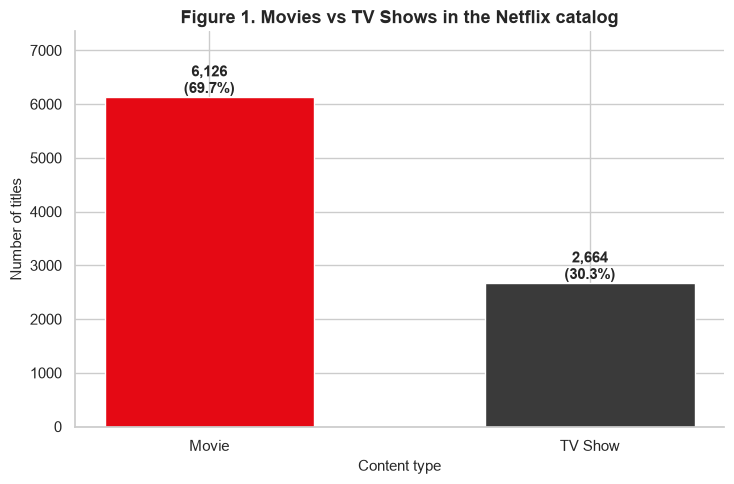

#### Interpretation
- **Observation:** Movies form the majority of catalog records.
- **Evidence:** Movies: 6,126 (69.7%); TV Shows: 2,664 (30.3%); about 2.30 Movies per TV Show (N = 8,790).
- **Interpretation:** By title count, the catalog snapshot is weighted toward feature films.
- **Limitation:** A title count treats a single film and a multi-season series as one unit each; it does not reflect runtime, number of episodes or viewing hours, and the snapshot reflects a single point in time.

In [21]:
tc = df["type"].value_counts(dropna=False)
tc = tc.reindex(order_types(tc.index))
fig, ax = plt.subplots(figsize=(7.5, 5))
bars = ax.bar(tc.index.astype(str), tc.values, color=[TYPE_COLORS.get(t, "#999999") for t in tc.index], width=0.55)
for b, n in zip(bars, tc.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n:,}\n({pct(n, N):.1f}%)",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylim(0, tc.max() * 1.2)
ax.set(title="Figure 1. Movies vs TV Shows in the Netflix catalog", xlabel="Content type", ylabel="Number of titles")
save_fig(fig, "01_type_distribution.png")

n_movie, n_tv = RESULTS["n_movie"], RESULTS["n_tv"]
interpret(
    f"{'Movies' if n_movie > n_tv else 'TV Shows'} form the majority of catalog records.",
    f"Movies: {n_movie:,} ({pct(n_movie, N):.1f}%); TV Shows: {n_tv:,} ({pct(n_tv, N):.1f}%); "
    f"about {n_movie / n_tv:.2f} Movies per TV Show (N = {N:,}).",
    "By title count, the catalog snapshot is weighted toward feature films.",
    "A title count treats a single film and a multi-season series as one unit each; it does not reflect runtime, "
    "number of episodes or viewing hours, and the snapshot reflects a single point in time.")

### Figure 2 – Titles added to Netflix by year (`added_year`), by type
Stacked bars are used instead of lines because some early years contain very few titles. The final year may be **incomplete**; its coverage is computed below.

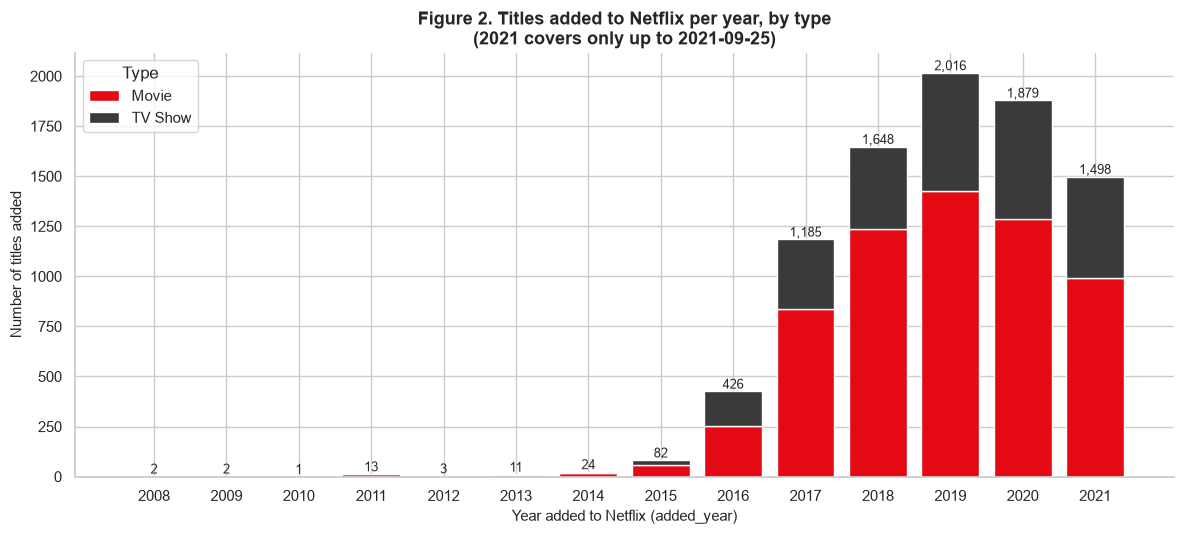

#### Interpretation
- **Observation:** Additions were sparse before 2015, rose steeply afterwards and peaked in 2019.
- **Evidence:** Date range 2008-01-01 to 2021-09-25. Only 56 titles were added before 2015 (first year with ≥30 additions: 2015, n = 82). Peak: 2019 with 2,016 titles. Titles added from 2016 onward: 8,652 (98.4%). Following years: 2020: 1,879, 2021: 1,498. Titles without a date: 0.
- **Interpretation:** Catalog additions recorded in this snapshot are concentrated in the late 2010s. The decline after the peak should be read with care: 2021 is incomplete in this file.
- **Limitation:** This is a snapshot of titles *currently* listed; titles that were added and later removed are not present, which can make earlier years look smaller than they actually were.

In [22]:
added = df.dropna(subset=["added_year"])
n_no_date = int(df["added_year"].isna().sum())
added_ct = pd.crosstab(added["added_year"].astype(int), added["type"])
added_ct = added_ct[order_types(added_ct.columns)]
added_tot = added_ct.sum(axis=1)
LAST_DATE = df["date_added"].max()
FIRST_DATE = df["date_added"].min()
last_year_partial = bool(LAST_DATE < pd.Timestamp(year=LAST_DATE.year, month=12, day=31))

fig, ax = plt.subplots(figsize=(12, 5.5))
x = added_ct.index.astype(str)
bottom = np.zeros(len(added_ct))
for t in added_ct.columns:
    ax.bar(x, added_ct[t].values, bottom=bottom, color=TYPE_COLORS.get(t, "#999999"), label=t)
    bottom += added_ct[t].values
for xi, tot in zip(x, bottom):
    ax.text(xi, tot, f"{int(tot):,}", ha="center", va="bottom", fontsize=9)
ttl = "Figure 2. Titles added to Netflix per year, by type"
if last_year_partial:
    ttl += f"\n({LAST_DATE.year} covers only up to {LAST_DATE.date()})"
ax.set(title=ttl, xlabel="Year added to Netflix (added_year)", ylabel="Number of titles added")
ax.legend(title="Type")
save_fig(fig, "02_titles_added_by_year_type.png")

peak_year = int(added_tot.idxmax()); peak_n = int(added_tot.max())
eligible_add_years = added_tot[added_tot >= MIN_N_TREND].index
first_elig = int(eligible_add_years.min())
pre_first = int(added_tot[added_tot.index < first_elig].sum())
since_2016 = int(added_tot[added_tot.index >= 2016].sum())
RESULTS.update(peak_add_year=peak_year, peak_add_n=peak_n, first_elig_add_year=first_elig,
               pre_first_add=pre_first, last_date=LAST_DATE, first_date=FIRST_DATE,
               last_year_partial=last_year_partial, add_tot=added_tot)
interpret(
    f"Additions were sparse before {first_elig}, rose steeply afterwards and peaked in {peak_year}.",
    f"Date range {FIRST_DATE.date()} to {LAST_DATE.date()}. Only {pre_first:,} titles were added before {first_elig} "
    f"(first year with ≥{MIN_N_TREND} additions: {first_elig}, n = {int(added_tot[first_elig]):,}). "
    f"Peak: {peak_year} with {peak_n:,} titles. Titles added from 2016 onward: {since_2016:,} ({pct(since_2016, N):.1f}%). "
    f"Following years: " + ", ".join(f"{y}: {int(n):,}" for y, n in added_tot[added_tot.index > peak_year].items()) +
    f". Titles without a date: {n_no_date}.",
    "Catalog additions recorded in this snapshot are concentrated in the late 2010s. The decline after the peak "
    f"should be read with care: {LAST_DATE.year} is {'incomplete' if last_year_partial else 'complete'} in this file.",
    "This is a snapshot of titles *currently* listed; titles that were added and later removed are not present, which "
    "can make earlier years look smaller than they actually were.")

### Figure 3 – Titles by release year (`release_year`), by type
To focus on the main distribution, the chart starts at the **1st percentile** of `release_year`; the number of older titles omitted *from the chart only* is reported (they remain in all calculations).

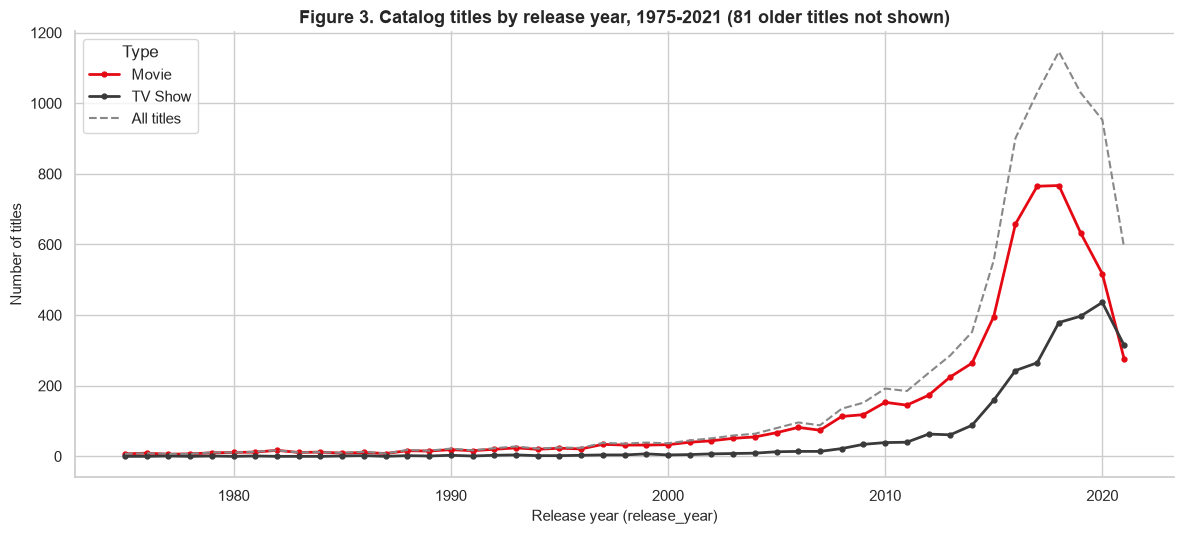

#### Interpretation
- **Observation:** The catalog is dominated by recent releases; counts rise sharply from the 2000s and fall in the most recent years.
- **Evidence:** Peak release year: 2018 (1,146 titles). Peak by type: Movie 2018, TV Show 2020. 84.8% of titles were released in 2010 or later; median release year = 2017 (Movies 2016, TV Shows 2018). Oldest title: 1925; chart filter omits 81 titles released before 1975.
- **Interpretation:** The catalog snapshot is concentrated on contemporary content. The drop in the latest release years is consistent with newer titles having had less time to be added before the snapshot was taken.
- **Limitation:** release_year is the original release date, not the date of addition; survivorship of older titles in the catalog and the snapshot cut-off both shape this distribution. For TV Shows, release_year may refer to a recent season.

In [23]:
ry = df["release_year"].dropna().astype(int)
RELEASE_CHART_START = int(np.floor(ry.quantile(0.01)))
excluded_from_chart = int((ry < RELEASE_CHART_START).sum())
rel_ct = pd.crosstab(df["release_year"].dropna().astype(int), df.loc[df["release_year"].notna(), "type"])
rel_ct = rel_ct[order_types(rel_ct.columns)]
rel_plot = rel_ct.loc[rel_ct.index >= RELEASE_CHART_START]

fig, ax = plt.subplots(figsize=(12, 5.5))
for t in rel_plot.columns:
    ax.plot(rel_plot.index, rel_plot[t], marker="o", markersize=3.5, lw=2, color=TYPE_COLORS.get(t, "#999999"), label=t)
ax.plot(rel_plot.index, rel_plot.sum(axis=1), ls="--", lw=1.5, color="#888888", label="All titles")
ax.set(title=f"Figure 3. Catalog titles by release year, {RELEASE_CHART_START}-{ry.max()} "
             f"({excluded_from_chart} older titles not shown)",
       xlabel="Release year (release_year)", ylabel="Number of titles")
ax.legend(title="Type")
save_fig(fig, "03_titles_released_by_year_type.png")

rel_tot = rel_ct.sum(axis=1)
peak_rel = int(rel_tot.idxmax())
share_2010 = pct((ry >= 2010).sum(), len(ry))
med_rel_type = df.groupby("type", observed=True)["release_year"].median()
peak_by_type = {t: int(rel_ct[t].idxmax()) for t in rel_ct.columns}
RESULTS.update(peak_rel_year=peak_rel, share_rel_2010=share_2010, median_release=float(ry.median()),
               min_release=int(ry.min()), med_rel_type=med_rel_type)
interpret(
    "The catalog is dominated by recent releases; counts rise sharply from the 2000s and fall in the most recent years.",
    f"Peak release year: {peak_rel} ({int(rel_tot[peak_rel]):,} titles). Peak by type: "
    + ", ".join(f"{t} {y}" for t, y in peak_by_type.items()) +
    f". {share_2010:.1f}% of titles were released in 2010 or later; median release year = {ry.median():.0f} "
    f"(Movies {med_rel_type.get('Movie', np.nan):.0f}, TV Shows {med_rel_type.get('TV Show', np.nan):.0f}). "
    f"Oldest title: {ry.min()}; chart filter omits {excluded_from_chart} titles released before {RELEASE_CHART_START}.",
    "The catalog snapshot is concentrated on contemporary content. The drop in the latest release years is consistent "
    "with newer titles having had less time to be added before the snapshot was taken.",
    "release_year is the original release date, not the date of addition; survivorship of older titles in the catalog and "
    "the snapshot cut-off both shape this distribution. For TV Shows, release_year may refer to a recent season.")

### Figure 4 – Top 10 countries (exploded `country` table)

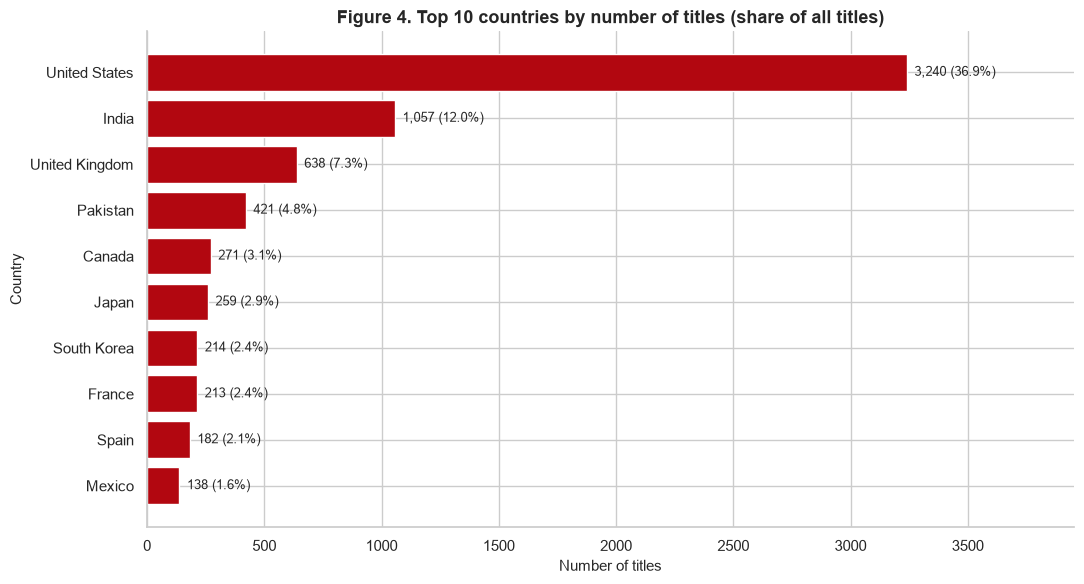

#### Interpretation
- **Observation:** United States is by far the most frequent production country, followed by India.
- **Evidence:** United States: 3,240 titles (36.9%); India: 1,057 (12.0%); 3rd United Kingdom: 638. The top 10 countries cover 6,633 titles (75.5%). 287 titles (3.3%) have an unknown country and are not ranked.
- **Interpretation:** The catalog snapshot is geographically concentrated, with a strong presence of US and Indian productions.
- **Limitation:** Only 0 records list more than one country, so co-productions appear to be reduced to a single country in this file; the catalog may also differ by region.

In [24]:
known_c = country_long[country_long["country_item"] != UNKNOWN_LABEL]
c_counts = known_c["country_item"].value_counts()
top10_c = c_counts.head(10)[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top10_c.index, top10_c.values, color=BASE_COLOR)
annotate_barh(ax, top10_c.values, N)
ax.set(title="Figure 4. Top 10 countries by number of titles (share of all titles)",
       xlabel="Number of titles", ylabel="Country")
save_fig(fig, "04_top10_countries.png")

top10_titles = known_c.loc[known_c["country_item"].isin(c_counts.head(10).index), "show_id"].nunique()
c1, c2 = c_counts.index[0], c_counts.index[1]
RESULTS.update(top_country=c1, top_country_n=int(c_counts.iloc[0]), second_country=c2,
               second_country_n=int(c_counts.iloc[1]), top10_country_share=pct(top10_titles, N))
interpret(
    f"{c1} is by far the most frequent production country, followed by {c2}.",
    f"{c1}: {int(c_counts.iloc[0]):,} titles ({pct(c_counts.iloc[0], N):.1f}%); {c2}: {int(c_counts.iloc[1]):,} "
    f"({pct(c_counts.iloc[1], N):.1f}%); 3rd {c_counts.index[2]}: {int(c_counts.iloc[2]):,}. "
    f"The top 10 countries cover {top10_titles:,} titles ({pct(top10_titles, N):.1f}%). "
    f"{RESULTS['n_unknown_country']:,} titles ({pct(RESULTS['n_unknown_country'], N):.1f}%) have an unknown country and are not ranked.",
    "The catalog snapshot is geographically concentrated, with a strong presence of US and Indian productions.",
    f"Only {RESULTS['multi_country_titles']:,} records list more than one country, so co-productions appear to be reduced to "
    "a single country in this file; the catalog may also differ by region.")

### Figure 5 – Top 10 genres/categories (exploded `listed_in` table)

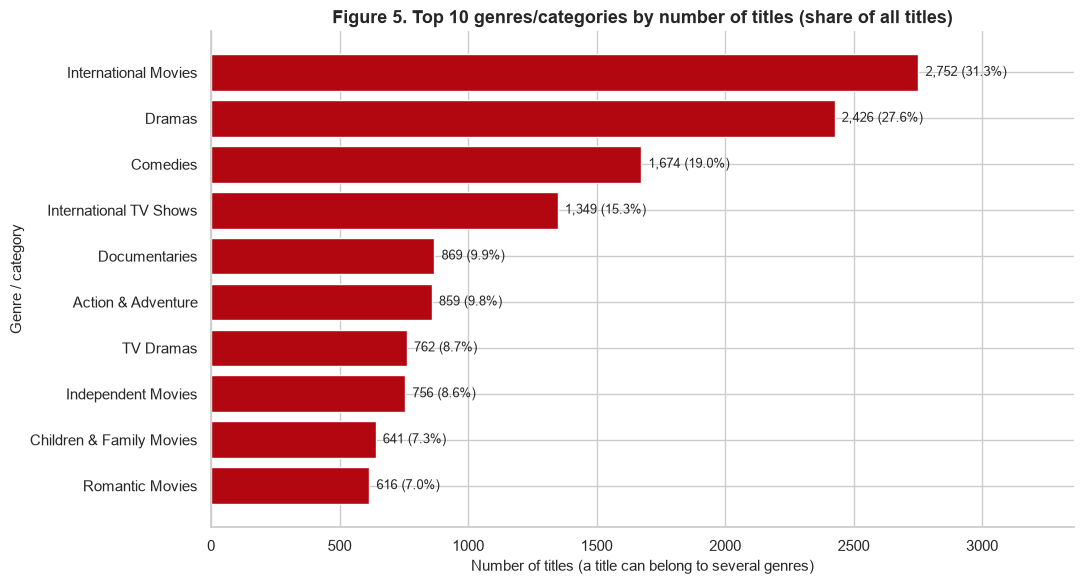

#### Interpretation
- **Observation:** 'International Movies', 'Dramas' and 'Comedies' are the most frequent categories.
- **Evidence:** International Movies: 2,752 (31.3% of titles); Dramas: 2,426 (27.6% of titles); Comedies: 1,674 (19.0% of titles); International TV Shows: 1,349 (15.3% of titles); Documentaries: 869 (9.9% of titles). Titles carry on average 2.19 categories; 42 distinct categories exist.
- **Interpretation:** International content and dramas/comedies make up a large part of the catalog by title count.
- **Limitation:** Netflix categories are multi-label and partly type-specific (e.g. 'Dramas' vs 'TV Dramas'), and 'International' is defined relative to the US; shares therefore overlap and do not sum to 100%.

In [25]:
g_counts = known_genres.value_counts()
top10_g = g_counts.head(10)[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top10_g.index, top10_g.values, color=BASE_COLOR)
annotate_barh(ax, top10_g.values, N)
ax.set(title="Figure 5. Top 10 genres/categories by number of titles (share of all titles)",
       xlabel="Number of titles (a title can belong to several genres)", ylabel="Genre / category")
save_fig(fig, "05_top10_genres.png")

tags_per_title = genre_long[genre_long["genre"] != UNKNOWN_LABEL].groupby("show_id").size()
RESULTS.update(top_genre=g_counts.index[0], top_genre_n=int(g_counts.iloc[0]),
               genre2=g_counts.index[1], genre2_n=int(g_counts.iloc[1]),
               genre3=g_counts.index[2], genre3_n=int(g_counts.iloc[2]), tags_per_title=float(tags_per_title.mean()))
interpret(
    f"'{g_counts.index[0]}', '{g_counts.index[1]}' and '{g_counts.index[2]}' are the most frequent categories.",
    "; ".join(f"{g}: {int(n):,} ({pct(n, N):.1f}% of titles)" for g, n in g_counts.head(5).items()) +
    f". Titles carry on average {tags_per_title.mean():.2f} categories; {RESULTS['n_genres']} distinct categories exist.",
    "International content and dramas/comedies make up a large part of the catalog by title count.",
    "Netflix categories are multi-label and partly type-specific (e.g. 'Dramas' vs 'TV Dramas'), and 'International' "
    "is defined relative to the US; shares therefore overlap and do not sum to 100%.")

### Figure 6 – Rating distribution (horizontal bar chart)

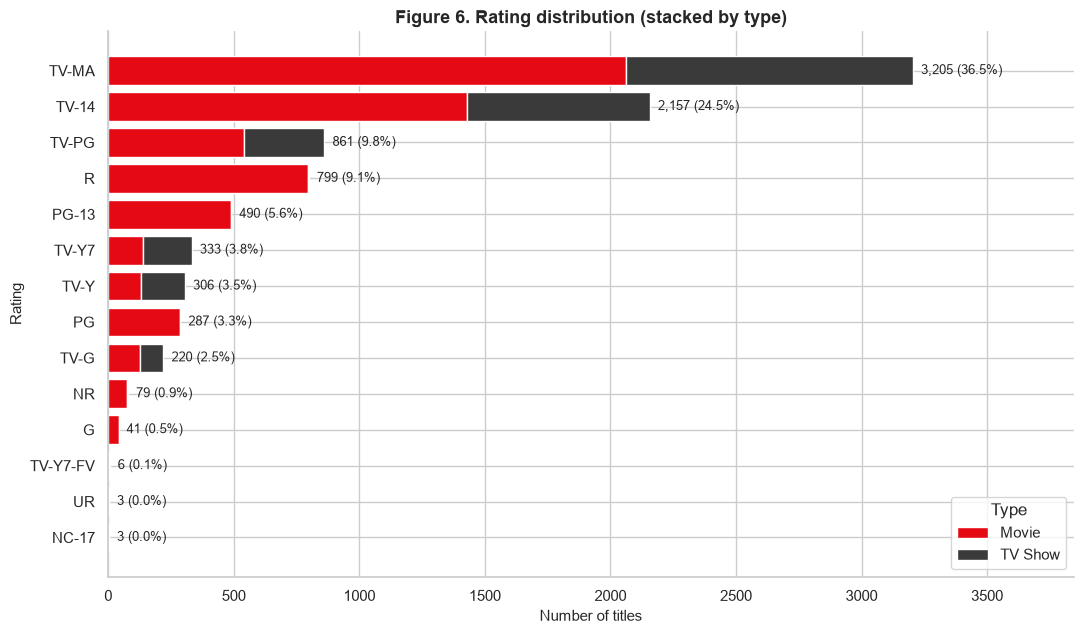

#### Interpretation
- **Observation:** TV-MA is the most common rating, and mature/teen TV ratings dominate the catalog.
- **Evidence:** TV-MA: 3,205 (36.5%); TV-14: 2,157 (24.5%); TV-PG: 861 (9.8%). Top 3 = 70.8%. Mature ratings (TV-MA, R, NC-17): 4,007 (45.6%); children/general ratings (TV-Y, TV-Y7, TV-Y7-FV, TV-G, G): 906 (10.3%).
- **Interpretation:** By title count the catalog leans toward content aimed at adult and teen audiences.
- **Limitation:** Ratings mix two systems (MPAA film ratings and US TV Parental Guidelines) that are not perfectly comparable, and ratings may vary by country.

In [26]:
r_ct = pd.crosstab(df["rating"].fillna("Missing"), df["type"])
r_ct = r_ct[order_types(r_ct.columns)]
r_ct = r_ct.loc[r_ct.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(11, 6.5))
left = np.zeros(len(r_ct))
for t in r_ct.columns:
    ax.barh(r_ct.index, r_ct[t].values, left=left, color=TYPE_COLORS.get(t, "#999999"), label=t)
    left += r_ct[t].values
for yi, tot in zip(r_ct.index, left):
    ax.text(tot + left.max() * 0.01, yi, f"{int(tot):,} ({pct(tot, N):.1f}%)", va="center", fontsize=9)
ax.set_xlim(0, left.max() * 1.2)
ax.set(title="Figure 6. Rating distribution (stacked by type)", xlabel="Number of titles", ylabel="Rating")
ax.legend(title="Type", loc="lower right")
save_fig(fig, "06_rating_distribution.png")

r_tot = df["rating"].value_counts()
MATURE = {"TV-MA", "R", "NC-17"}
YOUTH = {"TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G"}
mature_n = int(df["rating"].isin(MATURE).sum()); youth_n = int(df["rating"].isin(YOUTH).sum())
top3_share = pct(r_tot.head(3).sum(), N)
RESULTS.update(top_rating=r_tot.index[0], top_rating_n=int(r_tot.iloc[0]), mature_share=pct(mature_n, N),
               youth_share=pct(youth_n, N), rating2=r_tot.index[1], rating2_n=int(r_tot.iloc[1]))
interpret(
    f"{r_tot.index[0]} is the most common rating, and mature/teen TV ratings dominate the catalog.",
    f"{r_tot.index[0]}: {int(r_tot.iloc[0]):,} ({pct(r_tot.iloc[0], N):.1f}%); {r_tot.index[1]}: {int(r_tot.iloc[1]):,} "
    f"({pct(r_tot.iloc[1], N):.1f}%); {r_tot.index[2]}: {int(r_tot.iloc[2]):,} ({pct(r_tot.iloc[2], N):.1f}%). Top 3 = {top3_share:.1f}%. "
    f"Mature ratings (TV-MA, R, NC-17): {mature_n:,} ({pct(mature_n, N):.1f}%); children/general ratings "
    f"(TV-Y, TV-Y7, TV-Y7-FV, TV-G, G): {youth_n:,} ({pct(youth_n, N):.1f}%).",
    "By title count the catalog leans toward content aimed at adult and teen audiences.",
    "Ratings mix two systems (MPAA film ratings and US TV Parental Guidelines) that are not perfectly comparable, and "
    "ratings may vary by country.")

### Figure 7 – Movie duration distribution (Movies only)

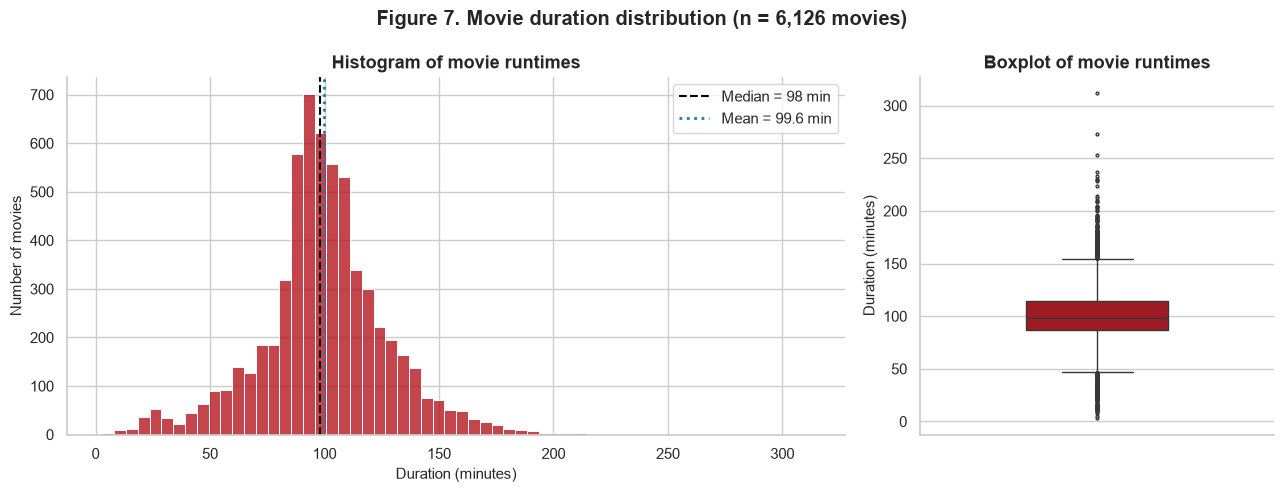

#### Interpretation
- **Observation:** Movie runtimes cluster tightly around feature length, with a long tail of short films and long epics.
- **Evidence:** n = 6,126; median 98 min, mean 99.6 min, SD 28.3; IQR 87–114 min; 64.2% fall between 80 and 120 min; range 3–312 min; 169 under 40 min and 47 over 180 min.
- **Interpretation:** Most films follow a conventional feature length; extreme values are plausible (shorts, specials, epics) and were kept.
- **Limitation:** Duration is only one attribute; the distribution reflects the current catalog, not all films ever produced.

In [27]:
mins = df.loc[is_movie, "movie_duration_minutes"].dropna().astype(float)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2.2, 1]})
sns.histplot(mins, bins=60, color=BASE_COLOR, ax=axes[0])
axes[0].axvline(mins.median(), color="black", ls="--", lw=1.5, label=f"Median = {mins.median():.0f} min")
axes[0].axvline(mins.mean(), color="#1f77b4", ls=":", lw=2, label=f"Mean = {mins.mean():.1f} min")
axes[0].set(title="Histogram of movie runtimes", xlabel="Duration (minutes)", ylabel="Number of movies")
axes[0].legend()
sns.boxplot(y=mins, color=BASE_COLOR, ax=axes[1], width=0.4, flierprops={"markersize": 2})
axes[1].set(title="Boxplot of movie runtimes", ylabel="Duration (minutes)")
fig.suptitle(f"Figure 7. Movie duration distribution (n = {len(mins):,} movies)", fontweight="bold")
save_fig(fig, "07_movie_duration_distribution.png")

q1, q3 = mins.quantile([0.25, 0.75])
share_80_120 = pct(mins.between(80, 120).sum(), len(mins))
RESULTS.update(movie_median=float(mins.median()), movie_mean=float(mins.mean()), movie_q1=float(q1),
               movie_q3=float(q3), movie_n=len(mins), share_80_120=share_80_120)
interpret(
    "Movie runtimes cluster tightly around feature length, with a long tail of short films and long epics.",
    f"n = {len(mins):,}; median {mins.median():.0f} min, mean {mins.mean():.1f} min, SD {mins.std():.1f}; IQR {q1:.0f}–{q3:.0f} min; "
    f"{share_80_120:.1f}% fall between 80 and 120 min; range {mins.min():.0f}–{mins.max():.0f} min; "
    f"{RESULTS['short_movies']} under 40 min and {RESULTS['long_movies']} over 180 min.",
    "Most films follow a conventional feature length; extreme values are plausible (shorts, specials, epics) and were kept.",
    "Duration is only one attribute; the distribution reflects the current catalog, not all films ever produced.")

### Figure 8 – TV-show seasons distribution (TV Shows only)

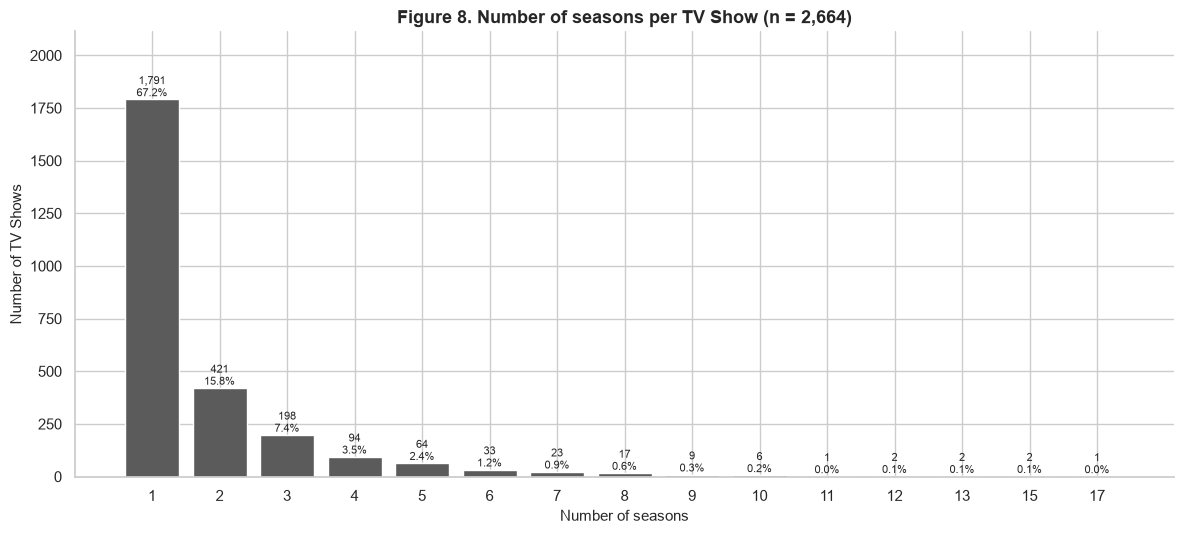

#### Interpretation
- **Observation:** Most TV Shows in the catalog have a single season; the distribution is strongly right-skewed.
- **Evidence:** 1 season: 1,791 (67.2%); ≤2 seasons: 2,212 (83.0%); ≥5 seasons: 160 (6.0%); mean 1.75, median 1, max 17.
- **Interpretation:** The TV catalog is dominated by short series (limited series, new shows or shows with few seasons available).
- **Limitation:** Season counts are right-censored: recent shows may still gain seasons, and the file records only the seasons available at snapshot time, not episodes or runtime.

In [28]:
seasons = df.loc[is_tv, "tv_seasons"].dropna().astype(int)
s_counts = seasons.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 5.5))
bars = ax.bar(s_counts.index.astype(str), s_counts.values, color=SECOND_COLOR)
for b, n in zip(bars, s_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n:,}\n{pct(n, len(seasons)):.1f}%",
            ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, s_counts.max() * 1.18)
ax.set(title=f"Figure 8. Number of seasons per TV Show (n = {len(seasons):,})",
       xlabel="Number of seasons", ylabel="Number of TV Shows")
save_fig(fig, "08_tv_seasons_distribution.png")

one = int((seasons == 1).sum()); le2 = int((seasons <= 2).sum()); ge5 = int((seasons >= 5).sum())
RESULTS.update(tv_one_share=pct(one, len(seasons)), tv_le2_share=pct(le2, len(seasons)), tv_n=len(seasons),
               tv_max=int(seasons.max()), tv_mean=float(seasons.mean()))
interpret(
    "Most TV Shows in the catalog have a single season; the distribution is strongly right-skewed.",
    f"1 season: {one:,} ({pct(one, len(seasons)):.1f}%); ≤2 seasons: {le2:,} ({pct(le2, len(seasons)):.1f}%); "
    f"≥5 seasons: {ge5:,} ({pct(ge5, len(seasons)):.1f}%); mean {seasons.mean():.2f}, median {seasons.median():.0f}, max {seasons.max()}.",
    "The TV catalog is dominated by short series (limited series, new shows or shows with few seasons available).",
    "Season counts are right-censored: recent shows may still gain seasons, and the file records only the seasons "
    "available at snapshot time, not episodes or runtime.")

### Figure 9 – Monthly seasonality of titles added
Seasonality is analysed only if `date_added` is sufficiently complete (≥ 90% parsed). Because the last year may be partial, a second panel restricts the data to **complete calendar years** that each contain at least `MIN_N_TREND` additions.

date_added completeness: 100.00%


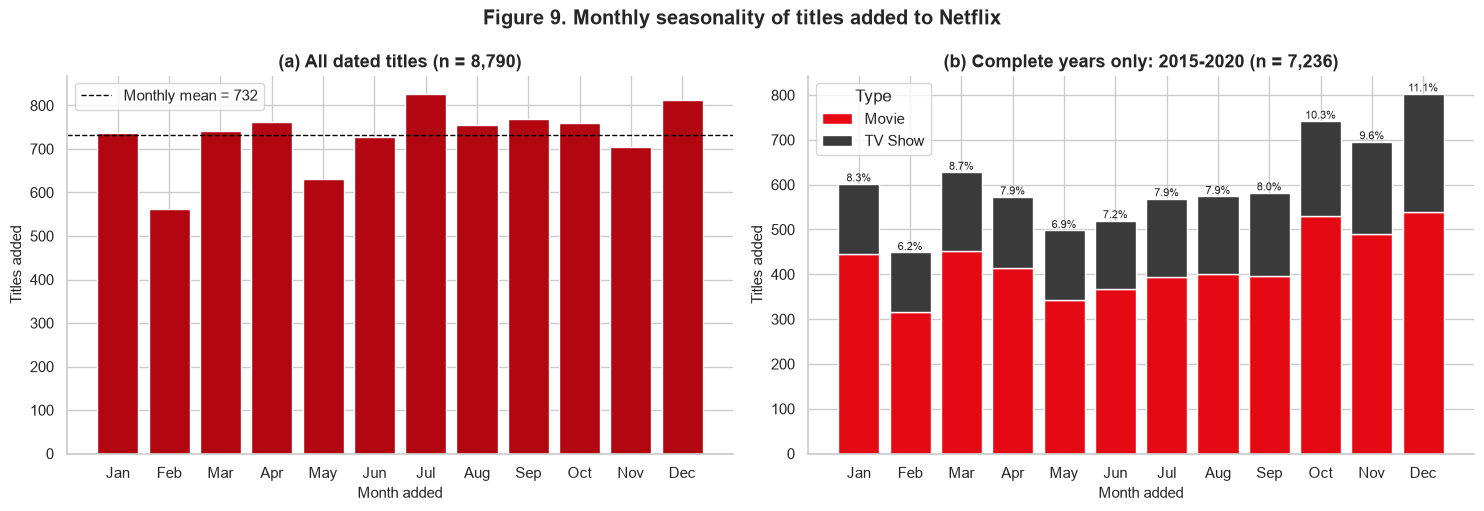

#### Interpretation
- **Observation:** Additions are spread fairly evenly across months; Dec is the highest and Feb the lowest month in complete years.
- **Evidence:** Complete years 2015-2020: Dec = 803 (11.1%), Feb = 449 (6.2%); an even split would be 8.3% per month; coefficient of variation = 0.17. Adjusted for month length, the busiest month per day is Dec and the quietest is Feb.
- **Interpretation:** There is only mild month-to-month variation; no strong seasonal concentration of additions is evident.
- **Limitation:** Part of February's low count is mechanical (fewer days). Month totals pool different years and catalog strategies.

In [29]:
date_completeness = pct(df["date_added"].notna().sum(), N)
print(f"date_added completeness: {date_completeness:.2f}%")
if date_completeness >= 90:
    complete_years = [int(y) for y, n in added_tot.items()
                      if n >= MIN_N_TREND and not (last_year_partial and y == LAST_DATE.year)]
    m_all = df.groupby("added_month_name", observed=False).size().reindex(MONTH_ABBR, fill_value=0)
    sub = df[df["added_year"].isin(complete_years)]
    m_ct = pd.crosstab(sub["added_month_name"], sub["type"]).reindex(MONTH_ABBR, fill_value=0)
    m_ct = m_ct[order_types(m_ct.columns)]
    m_tot = m_ct.sum(axis=1)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=False)
    axes[0].bar(MONTH_ABBR, m_all.values, color=BASE_COLOR)
    axes[0].axhline(m_all.mean(), color="black", ls="--", lw=1, label=f"Monthly mean = {m_all.mean():.0f}")
    axes[0].set(title=f"(a) All dated titles (n = {int(m_all.sum()):,})", xlabel="Month added", ylabel="Titles added")
    axes[0].legend()
    bottom = np.zeros(12)
    for t in m_ct.columns:
        axes[1].bar(MONTH_ABBR, m_ct[t].values, bottom=bottom, color=TYPE_COLORS.get(t, "#999"), label=t)
        bottom += m_ct[t].values
    for i, tot in enumerate(bottom):
        axes[1].text(i, tot, f"{pct(tot, bottom.sum()):.1f}%", ha="center", va="bottom", fontsize=8)
    axes[1].set(title=f"(b) Complete years only: {complete_years[0]}-{complete_years[-1]} (n = {int(m_tot.sum()):,})",
                xlabel="Month added", ylabel="Titles added")
    axes[1].legend(title="Type")
    fig.suptitle("Figure 9. Monthly seasonality of titles added to Netflix", fontweight="bold")
    save_fig(fig, "09_monthly_seasonality.png")

    cv = m_tot.std() / m_tot.mean()
    per_day = m_tot / pd.Series([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], index=MONTH_ABBR)
    RESULTS.update(month_max=m_tot.idxmax(), month_min=m_tot.idxmin(), month_cv=float(cv),
                   month_max_share=pct(m_tot.max(), m_tot.sum()), month_min_share=pct(m_tot.min(), m_tot.sum()))
    interpret(
        f"Additions are spread fairly evenly across months; {m_tot.idxmax()} is the highest and {m_tot.idxmin()} the lowest month "
        f"in complete years.",
        f"Complete years {complete_years[0]}-{complete_years[-1]}: {m_tot.idxmax()} = {int(m_tot.max()):,} "
        f"({pct(m_tot.max(), m_tot.sum()):.1f}%), {m_tot.idxmin()} = {int(m_tot.min()):,} ({pct(m_tot.min(), m_tot.sum()):.1f}%); "
        f"an even split would be 8.3% per month; coefficient of variation = {cv:.2f}. Adjusted for month length, the "
        f"busiest month per day is {per_day.idxmax()} and the quietest is {per_day.idxmin()}.",
        "There is only mild month-to-month variation; no strong seasonal concentration of additions is evident.",
        "Part of February's low count is mechanical (fewer days). Month totals pool different years and catalog strategies.")
else:
    print("date_added is not sufficiently complete for a reliable seasonality analysis; Figure 9 skipped.")

## 8. Correlation Analysis

**Design choices**

- **No arbitrary encoding.** Nominal variables (`type`, `rating`, `country`, `listed_in`, `director`) are *not* converted to integers for correlation; such codes have no numeric meaning.
- **Meaningful numeric features only:** `release_year`, `added_year`, `movie_duration_minutes`, `tv_seasons`.
- **Separate populations.** `movie_duration_minutes` exists only for Movies and `tv_seasons` only for TV Shows, so they are never correlated with each other. Two matrices are computed: **Movies** (`release_year`, `added_year`, `movie_duration_minutes`) and **TV Shows** (`release_year`, `added_year`, `tv_seasons`). `release_year` vs `added_year` is also computed for the whole catalog.
- **Missing values:** listwise deletion within each matrix (rows with any missing value in that matrix's features are excluded and counted).
- **Methods:** **Pearson** (linear association) is the primary method; **Spearman** (rank-based) is reported alongside because durations and season counts are skewed and the year variables are discrete and bounded.
- **Magnitude labels:** |r| < 0.10 negligible, 0.10–0.29 weak, 0.30–0.49 moderate, ≥ 0.50 strong. With thousands of rows almost any non-zero coefficient is "statistically significant", so the focus is on **effect size**.

In [30]:
def corr_block(frame, cols, label):
    sub = frame[cols].astype("Float64").astype(float)
    complete = sub.dropna()
    info = {"population": label, "rows_in_population": len(sub), "rows_used": len(complete),
            "rows_excluded_missing": len(sub) - len(complete), "features": ", ".join(cols)}
    return complete, complete.corr(method="pearson"), complete.corr(method="spearman"), info

mov_cols = ["release_year", "added_year", "movie_duration_minutes"]
tv_cols = ["release_year", "added_year", "tv_seasons"]
mov_cc, mov_p, mov_s, mov_info = corr_block(df[is_movie], mov_cols, "Movies")
tv_cc, tv_p, tv_s, tv_info = corr_block(df[is_tv], tv_cols, "TV Shows")
all_cc, all_p, all_s, all_info = corr_block(df, ["release_year", "added_year"], "All titles")
display(pd.DataFrame([mov_info, tv_info, all_info]))

for name, p, s in [("Movies", mov_p, mov_s), ("TV Shows", tv_p, tv_s)]:
    print(f"{name} – Pearson:"); display(p.round(3))
    print(f"{name} – Spearman:"); display(s.round(3))

pairs = []
for name, p, s, cols in [("Movies", mov_p, mov_s, mov_cols), ("TV Shows", tv_p, tv_s, tv_cols),
                         ("All titles", all_p, all_s, ["release_year", "added_year"])]:
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            r, rho = p.iloc[i, j], s.iloc[i, j]
            pairs.append({"population": name, "pair": f"{cols[i]} vs {cols[j]}", "pearson_r": round(r, 3),
                          "spearman_rho": round(rho, 3), "strength (Pearson)": strength(r), "strength (Spearman)": strength(rho)})
corr_pairs = pd.DataFrame(pairs)
display(corr_pairs)

,population,rows_in_population,rows_used,rows_excluded_missing,features
0,Movies,6126,6126,0,"release_year, added_year, movie_duration_minutes"
1,TV Shows,2664,2664,0,"release_year, added_year, tv_seasons"
2,All titles,8790,8790,0,"release_year, added_year"


Movies – Pearson:


,release_year,added_year,movie_duration_minutes
release_year,1.00,0.04,-0.21
added_year,0.04,1.00,0.12
movie_duration_minutes,-0.21,0.12,1.00


Movies – Spearman:


,release_year,added_year,movie_duration_minutes
release_year,1.00,0.23,-0.19
added_year,0.23,1.00,0.13
movie_duration_minutes,-0.19,0.13,1.00


TV Shows – Pearson:


,release_year,added_year,tv_seasons
release_year,1.00,0.39,-0.08
added_year,0.39,1.00,0.04
tv_seasons,-0.08,0.04,1.00


TV Shows – Spearman:


,release_year,added_year,tv_seasons
release_year,1.00,0.68,0.03
added_year,0.68,1.00,0.10
tv_seasons,0.03,0.10,1.00


,population,pair,pearson_r,spearman_rho,strength (Pearson),strength (Spearman)
0,Movies,release_year vs added_year,0.04,0.23,negligible,weak
1,Movies,release_year vs movie_duration_minutes,-0.21,-0.19,weak,weak
2,Movies,added_year vs movie_duration_minutes,0.12,0.13,weak,weak
3,TV Shows,release_year vs added_year,0.39,0.68,moderate,strong
4,TV Shows,release_year vs tv_seasons,-0.08,0.03,negligible,negligible
5,TV Shows,added_year vs tv_seasons,0.04,0.10,negligible,weak
6,All titles,release_year vs added_year,0.11,0.37,weak,moderate


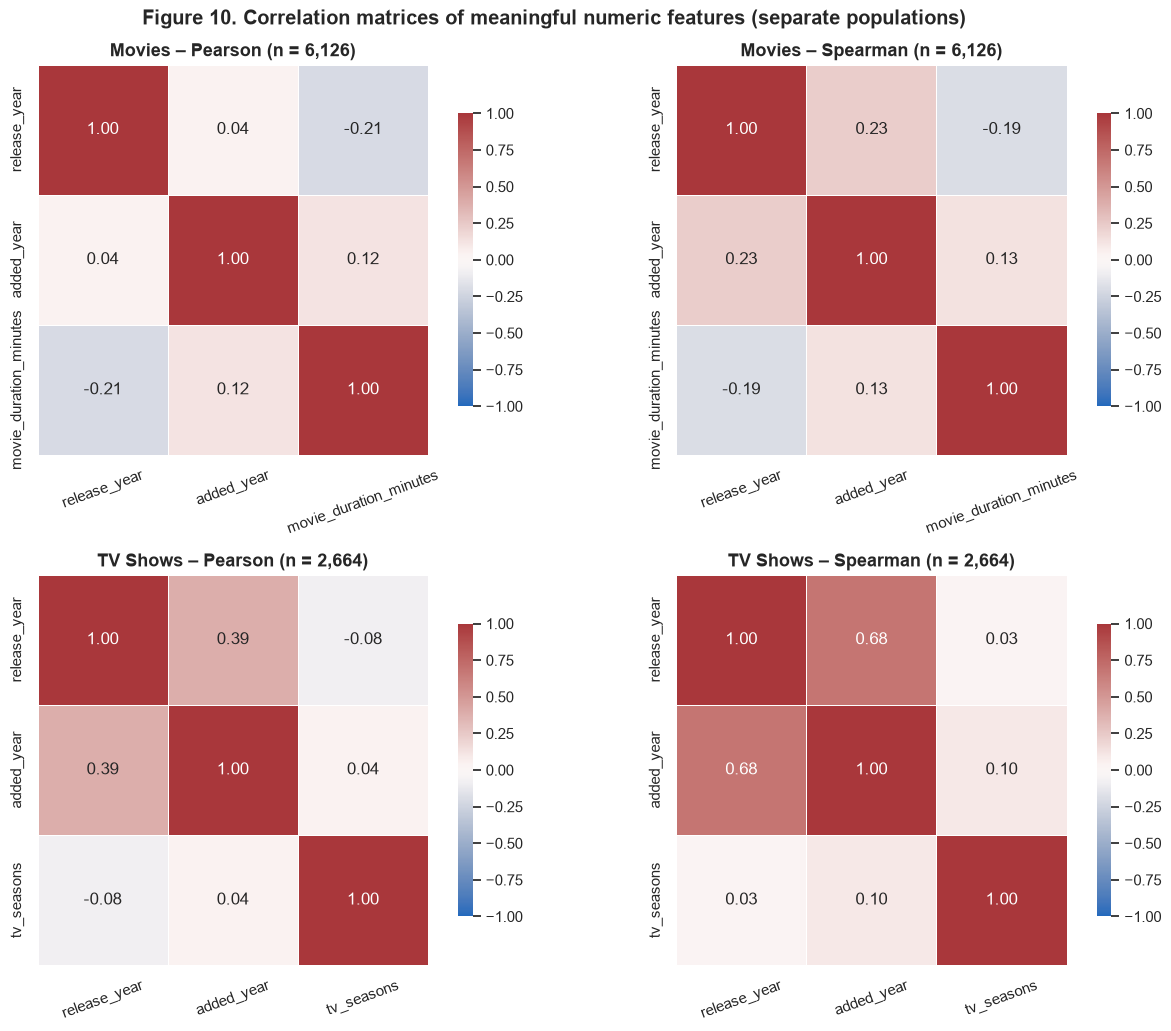

#### Interpretation
- **Observation:** Most correlations are weak or negligible. The clearest relationships are a weak negative association between release year and movie runtime, and a positive association between release year and added year (stronger for TV Shows).
- **Evidence:** Movies: release_year vs runtime r = -0.206 (weak), Spearman ρ = -0.191; added_year vs runtime r = 0.124 (weak). TV Shows: release_year vs seasons r = -0.082 (negligible), ρ = 0.030; release_year vs added_year r = 0.388, ρ = 0.682 (strong). All titles: release_year vs added_year r = 0.112, ρ = 0.373.
- **Interpretation:** Newer movies in the catalog tend to be slightly shorter, but release year explains only a small share of runtime variation (r² ≈ 0.043). The release/added association is partly structural: a title cannot normally be added before it is released, and for TV Shows release_year may reflect the most recent season. The Spearman–Pearson gap for release vs added year indicates a monotonic but non-linear relationship driven by a few very old titles.
- **Limitation:** Correlation does not imply causation. Coefficients summarise linear/monotonic association only, are sensitive to outliers and to the snapshot design, and nominal variables were deliberately excluded.

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
for ax, mat, ttl in [(axes[0, 0], mov_p, f"Movies – Pearson (n = {len(mov_cc):,})"),
                     (axes[0, 1], mov_s, f"Movies – Spearman (n = {len(mov_cc):,})"),
                     (axes[1, 0], tv_p, f"TV Shows – Pearson (n = {len(tv_cc):,})"),
                     (axes[1, 1], tv_s, f"TV Shows – Spearman (n = {len(tv_cc):,})")]:
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0, square=True,
                linewidths=0.5, cbar_kws={"shrink": 0.75}, ax=ax)
    ax.set_title(ttl)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Figure 10. Correlation matrices of meaningful numeric features (separate populations)", fontweight="bold")
save_fig(fig, "10_correlation_heatmaps.png")

r_md = mov_p.loc["release_year", "movie_duration_minutes"]; rho_md = mov_s.loc["release_year", "movie_duration_minutes"]
r_ma = mov_p.loc["added_year", "movie_duration_minutes"]
r_ts = tv_p.loc["release_year", "tv_seasons"]; rho_ts = tv_s.loc["release_year", "tv_seasons"]
r_ra = all_p.loc["release_year", "added_year"]; rho_ra = all_s.loc["release_year", "added_year"]
r_ra_tv = tv_p.loc["release_year", "added_year"]; rho_ra_tv = tv_s.loc["release_year", "added_year"]
RESULTS.update(r_movie_dur_release=r_md, rho_movie_dur_release=rho_md, r_tv_seasons_release=r_ts,
               r_release_added=r_ra, rho_release_added=rho_ra)
interpret(
    "Most correlations are weak or negligible. The clearest relationships are a weak negative association between "
    "release year and movie runtime, and a positive association between release year and added year (stronger for TV Shows).",
    f"Movies: release_year vs runtime r = {r_md:.3f} ({strength(r_md)}), Spearman ρ = {rho_md:.3f}; added_year vs runtime "
    f"r = {r_ma:.3f} ({strength(r_ma)}). TV Shows: release_year vs seasons r = {r_ts:.3f} ({strength(r_ts)}), ρ = {rho_ts:.3f}; "
    f"release_year vs added_year r = {r_ra_tv:.3f}, ρ = {rho_ra_tv:.3f} ({strength(rho_ra_tv)}). "
    f"All titles: release_year vs added_year r = {r_ra:.3f}, ρ = {rho_ra:.3f}.",
    "Newer movies in the catalog tend to be slightly shorter, but release year explains only a small share of runtime "
    f"variation (r² ≈ {r_md**2:.3f}). The release/added association is partly structural: a title cannot normally be added "
    "before it is released, and for TV Shows release_year may reflect the most recent season. The Spearman–Pearson gap "
    "for release vs added year indicates a monotonic but non-linear relationship driven by a few very old titles.",
    "Correlation does not imply causation. Coefficients summarise linear/monotonic association only, are sensitive to "
    "outliers and to the snapshot design, and nominal variables were deliberately excluded.")

### 8.1 Closer look: movie runtime vs release year
A hexbin plot avoids over-plotting thousands of points; the line shows the median runtime for release years with at least `MIN_N_TREND` movies.

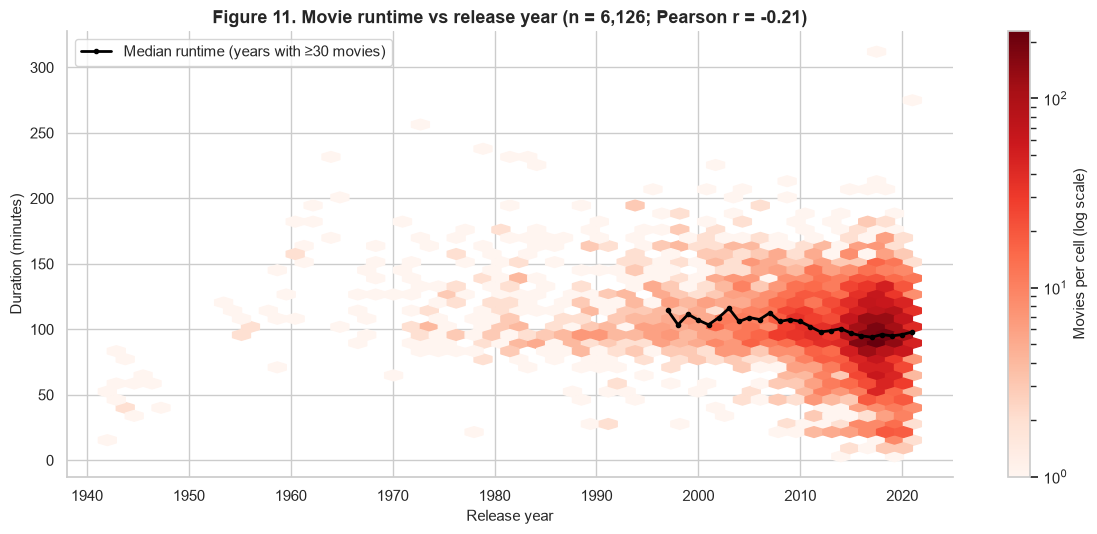

#### Interpretation
- **Observation:** Runtimes are widely dispersed in every release year; the median line drifts slightly downward in recent years.
- **Evidence:** Median runtime in the earliest eligible year (1997): 114 min; in the latest (2021): 98 min; 25 years met the ≥30 rule. Pearson r = -0.206.
- **Interpretation:** The weak negative correlation reflects a modest shift in the catalog's mix rather than a strong rule linking era and length.
- **Limitation:** Older films in the catalog are a selected subset (classics, curated titles) and may not be representative of their era.

In [32]:
mv = df.loc[is_movie, ["release_year", "movie_duration_minutes"]].dropna().astype(float)
med_by_year = mv.groupby("release_year")["movie_duration_minutes"].agg(["median", "count"])
med_by_year = med_by_year[med_by_year["count"] >= MIN_N_TREND]
fig, ax = plt.subplots(figsize=(12, 5.5))
hb = ax.hexbin(mv["release_year"], mv["movie_duration_minutes"], gridsize=45, cmap="Reds", mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="Movies per cell (log scale)")
ax.plot(med_by_year.index, med_by_year["median"], color="black", lw=2, marker="o", markersize=3,
        label=f"Median runtime (years with ≥{MIN_N_TREND} movies)")
ax.set(title=f"Figure 11. Movie runtime vs release year (n = {len(mv):,}; Pearson r = {r_md:.2f})",
       xlabel="Release year", ylabel="Duration (minutes)")
ax.legend(loc="upper left")
save_fig(fig, "11_movie_runtime_vs_release_year.png")
interpret(
    "Runtimes are widely dispersed in every release year; the median line drifts slightly downward in recent years.",
    f"Median runtime in the earliest eligible year ({int(med_by_year.index.min())}): {med_by_year['median'].iloc[0]:.0f} min; "
    f"in the latest ({int(med_by_year.index.max())}): {med_by_year['median'].iloc[-1]:.0f} min; "
    f"{len(med_by_year)} years met the ≥{MIN_N_TREND} rule. Pearson r = {r_md:.3f}.",
    "The weak negative correlation reflects a modest shift in the catalog's mix rather than a strong rule linking era and length.",
    "Older films in the catalog are a selected subset (classics, curated titles) and may not be representative of their era.")

## 9. Trend Identification

Two different time variables are used and **must not be confused**:

| Variable | Meaning | Question it answers |
|---|---|---|
| `release_year` | Year the title was originally released | *What era does the content come from?* |
| `added_year` | Year the title was added to Netflix | *When did the title enter the catalog?* |

Sample-size rule: year- or period-level distribution statistics are shown only where a group contains at least **`MIN_N_TREND` = 30** observations. Bars are preferred to lines whenever small groups exist.

### 9.1 How has the number of titles added changed over time?

type,Movie,TV Show,Total,YoY change,YoY change %,Cumulative,Cumulative % of catalog
added_year,,,,,,,
2008,1,1,2,NaN,NaN,2,0.00
2009,2,0,2,0.00,0.00,4,0.00
2010,1,0,1,-1.00,-50.00,5,0.10
2011,13,0,13,12.00,"1,200.00",18,0.20
2012,3,0,3,-10.00,-76.90,21,0.20
2013,6,5,11,8.00,266.70,32,0.40
2014,19,5,24,13.00,118.20,56,0.60
2015,56,26,82,58.00,241.70,138,1.60
2016,251,175,426,344.00,419.50,564,6.40


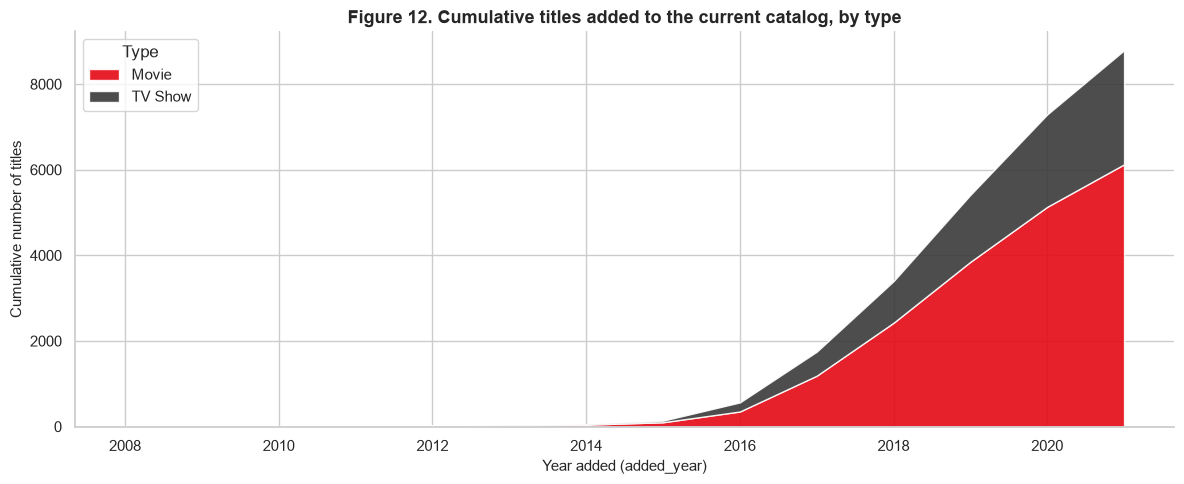

#### Interpretation
- **Observation:** The cumulative curve is flat until the mid-2010s and then steep: most of the current catalog was added within a few years.
- **Evidence:** 50% of dated titles had been added by the end of 2019; additions in 2019 (2,016) were 24.6× those in 2015 (82).
- **Interpretation:** Catalog additions (among titles still listed) accelerated strongly in the second half of the 2010s.
- **Limitation:** Removed titles are absent from the snapshot, which compresses earlier years; the last year may be partial.

In [33]:
add_trend = added_ct.copy()
add_trend["Total"] = add_trend.sum(axis=1)
add_trend["YoY change"] = add_trend["Total"].diff()
add_trend["YoY change %"] = (add_trend["Total"].pct_change() * 100).round(1)
add_trend["Cumulative"] = add_trend["Total"].cumsum()
add_trend["Cumulative % of catalog"] = (add_trend["Cumulative"] / add_trend["Total"].sum() * 100).round(1)
display(add_trend)

fig, ax = plt.subplots(figsize=(12, 5))
cum = added_ct.cumsum()
ax.stackplot(cum.index, *[cum[t].values for t in cum.columns], labels=cum.columns,
             colors=[TYPE_COLORS.get(t, "#999") for t in cum.columns], alpha=0.9)
ax.set(title="Figure 12. Cumulative titles added to the current catalog, by type",
       xlabel="Year added (added_year)", ylabel="Cumulative number of titles")
ax.legend(loc="upper left", title="Type")
save_fig(fig, "12_cumulative_titles_added.png")

yrs_half = int(add_trend.index[add_trend["Cumulative % of catalog"] >= 50][0])
RESULTS["half_catalog_year"] = yrs_half
interpret(
    "The cumulative curve is flat until the mid-2010s and then steep: most of the current catalog was added within a few years.",
    f"50% of dated titles had been added by the end of {yrs_half}; additions in {peak_year} ({peak_n:,}) were "
    f"{peak_n / max(int(added_tot.get(first_elig, 1)), 1):.1f}× those in {first_elig} ({int(added_tot.get(first_elig, 0)):,}).",
    "Catalog additions (among titles still listed) accelerated strongly in the second half of the 2010s.",
    "Removed titles are absent from the snapshot, which compresses earlier years; the last year may be partial.")

### 9.2 How has the mix of Movies vs TV Shows changed over time (by `added_year`)?
Only years with at least `MIN_N_TREND` additions are shown, to avoid unstable percentages.

type,Movie,TV Show,Movie %,TV Show %
added_year,,,,
2015,56,26,68.30,31.70
2016,251,175,58.90,41.10
2017,836,349,70.50,29.50
2018,1237,411,75.10,24.90
2019,1424,592,70.60,29.40
2020,1284,595,68.30,31.70
2021,993,505,66.30,33.70


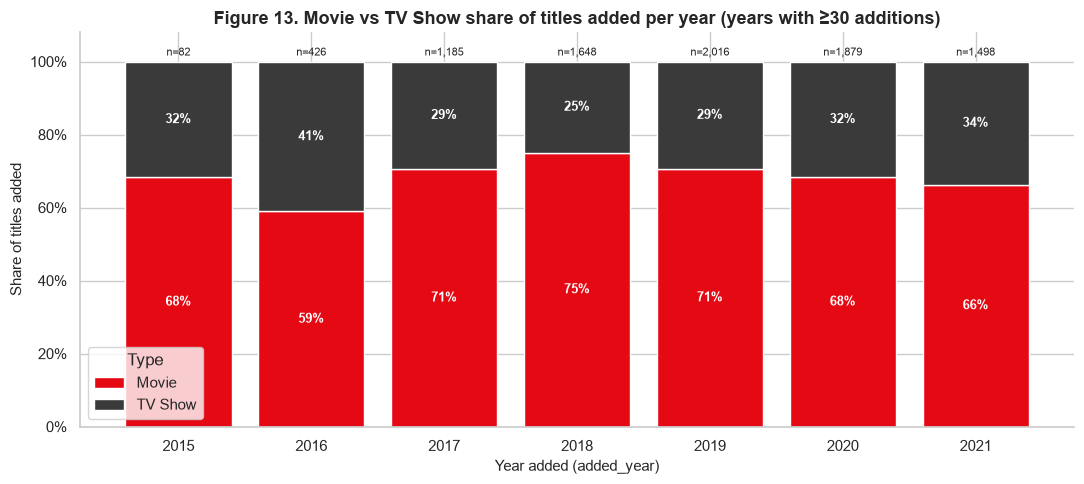

#### Interpretation
- **Observation:** Movies account for the majority of additions in every eligible year, but the TV Show share varies and is highest in the latest years.
- **Evidence:** TV Show share: 2015 31.7% (n = 82), lowest 24.9% in 2018, 2021 33.7% (n = 1,498).
- **Interpretation:** Among titles still in the catalog, those added recently include a relatively larger proportion of series than those added in 2017–2018.
- **Limitation:** Early eligible years have small n; a changing share does not reveal why the mix changed, and removals may differ by type.

In [34]:
mix = added_ct.loc[added_tot >= MIN_N_TREND]
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
display(pd.concat([mix, mix_pct.add_suffix(" %").round(1)], axis=1))

fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(mix_pct))
for t in mix_pct.columns:
    ax.bar(mix_pct.index.astype(str), mix_pct[t].values, bottom=bottom, color=TYPE_COLORS.get(t, "#999"), label=t)
    for i, (v, b) in enumerate(zip(mix_pct[t].values, bottom)):
        ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    bottom += mix_pct[t].values
for i, n in enumerate(mix.sum(axis=1)):
    ax.text(i, 101, f"n={n:,}", ha="center", va="bottom", fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 108)
ax.set(title=f"Figure 13. Movie vs TV Show share of titles added per year (years with ≥{MIN_N_TREND} additions)",
       xlabel="Year added (added_year)", ylabel="Share of titles added")
ax.legend(title="Type", loc="lower left")
save_fig(fig, "13_type_mix_by_added_year.png")

tv_first, tv_last = mix_pct["TV Show"].iloc[0], mix_pct["TV Show"].iloc[-1]
y_first, y_last = int(mix_pct.index[0]), int(mix_pct.index[-1])
RESULTS.update(tv_share_first=tv_first, tv_share_last=tv_last, mix_y_first=y_first, mix_y_last=y_last,
               tv_share_min_year=int(mix_pct["TV Show"].idxmin()), tv_share_min=float(mix_pct["TV Show"].min()))
interpret(
    "Movies account for the majority of additions in every eligible year, but the TV Show share varies and is highest in the latest years.",
    f"TV Show share: {y_first} {tv_first:.1f}% (n = {int(mix.sum(axis=1).iloc[0])}), lowest {mix_pct['TV Show'].min():.1f}% in "
    f"{int(mix_pct['TV Show'].idxmin())}, {y_last} {tv_last:.1f}% (n = {int(mix.sum(axis=1).iloc[-1]):,}).",
    "Among titles still in the catalog, those added recently include a relatively larger proportion of series than those added in 2017–2018.",
    "Early eligible years have small n; a changing share does not reveal why the mix changed, and removals may differ by type.")

### 9.3 How have the release years of catalog titles changed over time?
For each `added_year` with at least `MIN_N_TREND` titles: the distribution of `release_year`, the median "age at addition" (`years_to_add`) and the share of titles added within one year of release.

,titles,median_release_year,median_years_to_add,share_within_1yr,share_older_than_10yr
added_year,,,,,
2015,82,"2,015.00",0.00,81.70,2.40
2016,426,"2,015.00",1.00,65.70,7.50
2017,1185,"2,016.00",1.00,59.70,7.30
2018,1648,"2,017.00",1.00,54.90,10.80
2019,2016,"2,018.00",1.00,51.60,15.80
2020,1879,"2,019.00",1.00,55.50,14.50
2021,1498,"2,020.00",1.00,50.80,20.00


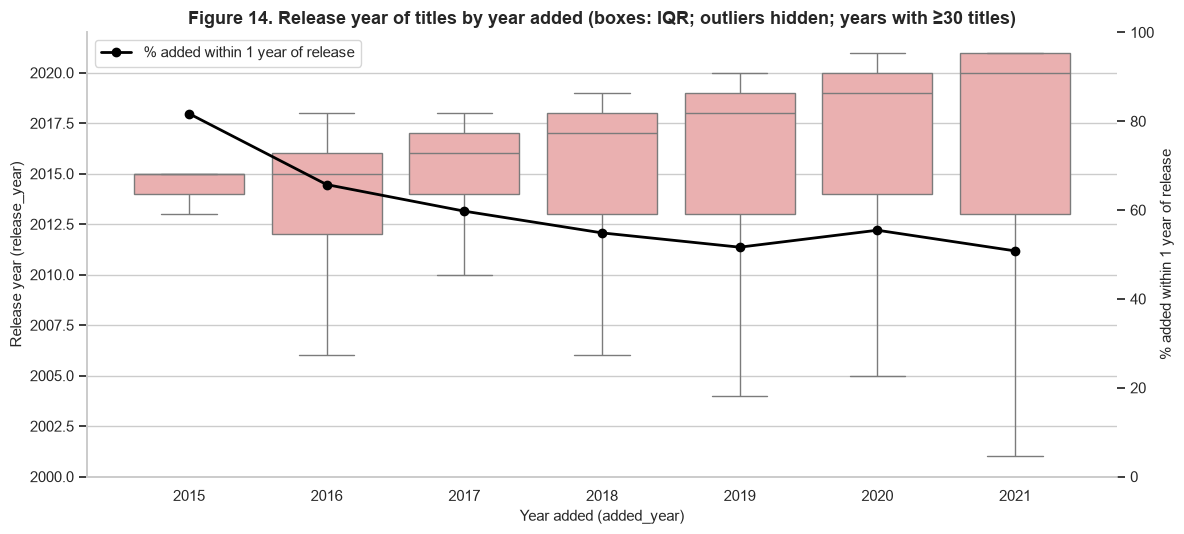

#### Interpretation
- **Observation:** In every eligible addition year most titles were recent releases, and the median release year moves forward roughly in step with the addition year.
- **Evidence:** Overall median years_to_add = 1. Share added within one year of release: 2015 81.7% → 2021 50.8%. Median release year: 2015 → 2015, 2021 → 2020. 14 titles have added_year < release_year (flagged, kept).
- **Interpretation:** Titles entering the catalog are, on the whole, recent content; older back-catalog titles form a minority in each year.
- **Limitation:** years_to_add is computed from years only (±1 year precision). Negative values may reflect re-releases, later seasons or data-entry differences.

In [35]:
elig = df[df["added_year"].isin(added_tot[added_tot >= MIN_N_TREND].index)].copy()
age_tbl = elig.groupby("added_year").agg(
    titles=("show_id", "size"),
    median_release_year=("release_year", "median"),
    median_years_to_add=("years_to_add", "median"),
    share_within_1yr=("years_to_add", lambda s: pct((s.dropna() <= 1).sum(), s.notna().sum())),
    share_older_than_10yr=("years_to_add", lambda s: pct((s.dropna() > 10).sum(), s.notna().sum())),
)
display(age_tbl.round(1))

fig, ax = plt.subplots(figsize=(12, 5.5))
plot_df = elig[["added_year", "release_year"]].dropna().astype(int)
sns.boxplot(data=plot_df, x="added_year", y="release_year", color="#F4A6A6", showfliers=False, ax=ax)
ax2 = ax.twinx()
ax2.plot(range(len(age_tbl)), age_tbl["share_within_1yr"].values, color="black", marker="o", lw=2,
         label="% added within 1 year of release")
ax2.set_ylabel("% added within 1 year of release"); ax2.set_ylim(0, 100); ax2.grid(False)
ax2.legend(loc="upper left")
ax.set(title=f"Figure 14. Release year of titles by year added (boxes: IQR; outliers hidden; years with ≥{MIN_N_TREND} titles)",
       xlabel="Year added (added_year)", ylabel="Release year (release_year)")
save_fig(fig, "14_release_year_by_added_year.png")

RESULTS.update(median_lag_overall=float(df["years_to_add"].median()),
               share_within_1yr_first=float(age_tbl["share_within_1yr"].iloc[0]),
               share_within_1yr_last=float(age_tbl["share_within_1yr"].iloc[-1]),
               age_y_first=int(age_tbl.index[0]), age_y_last=int(age_tbl.index[-1]),
               n_added_before_release=int(df["added_before_release"].sum()))
interpret(
    "In every eligible addition year most titles were recent releases, and the median release year moves forward roughly in step with the addition year.",
    f"Overall median years_to_add = {df['years_to_add'].median():.0f}. Share added within one year of release: "
    f"{age_tbl.index[0]} {age_tbl['share_within_1yr'].iloc[0]:.1f}% → {age_tbl.index[-1]} {age_tbl['share_within_1yr'].iloc[-1]:.1f}%. "
    f"Median release year: {age_tbl.index[0]} → {age_tbl['median_release_year'].iloc[0]:.0f}, "
    f"{age_tbl.index[-1]} → {age_tbl['median_release_year'].iloc[-1]:.0f}. "
    f"{int(df['added_before_release'].sum())} titles have added_year < release_year (flagged, kept).",
    "Titles entering the catalog are, on the whole, recent content; older back-catalog titles form a minority in each year.",
    "years_to_add is computed from years only (±1 year precision). Negative values may reflect re-releases, later seasons or data-entry differences.")

### 9.4 Which ratings, countries and genres dominate the catalog?

,rating,country (known),genre/category
rank,,,
1,TV-MA (36.5%),United States (36.9%),International Movies (31.3%)
2,TV-14 (24.5%),India (12.0%),Dramas (27.6%)
3,TV-PG (9.8%),United Kingdom (7.3%),Comedies (19.0%)
4,R (9.1%),Pakistan (4.8%),International TV Shows (15.3%)
5,PG-13 (5.6%),Canada (3.1%),Documentaries (9.9%)


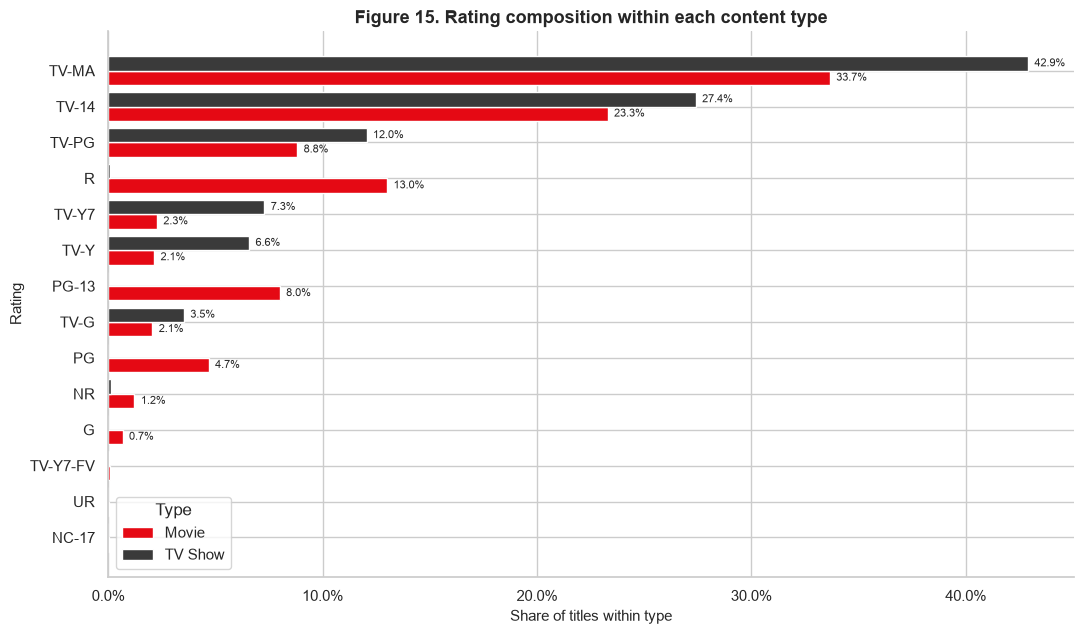

#### Interpretation
- **Observation:** TV-MA is the leading rating within both Movies and TV Shows; MPAA ratings (R, PG-13, PG) appear almost only among Movies, while children's TV ratings are relatively more common among TV Shows.
- **Evidence:** TV-MA share: Movies 33.7%, TV Shows 42.9%. Children's ratings (TV-Y + TV-Y7): Movies 4.4%, TV Shows 13.9%. Dominant country: United States; dominant category: International Movies.
- **Interpretation:** The catalog composition by rating differs by type, partly because two rating systems apply to films and to television.
- **Limitation:** Shares are within-type and descriptive; they do not indicate audience size or demand.

In [36]:
def top_share(series_counts, k=5):
    return [f"{i} ({pct(v, N):.1f}%)" for i, v in series_counts.head(k).items()]
dominance = pd.DataFrame({
    "rank": range(1, 6),
    "rating": top_share(df["rating"].value_counts()),
    "country (known)": top_share(c_counts),
    "genre/category": top_share(g_counts),
})
display(dominance.set_index("rank"))

r_type_pct = pd.crosstab(df["rating"], df["type"], normalize="columns") * 100
r_type_pct = r_type_pct[order_types(r_type_pct.columns)]
r_type_pct = r_type_pct.loc[r_type_pct.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(11, 6.5))
yy = np.arange(len(r_type_pct)); h = 0.4
for k, t in enumerate(r_type_pct.columns):
    ax.barh(yy + (k - 0.5) * h, r_type_pct[t].values, height=h, color=TYPE_COLORS.get(t, "#999"), label=t)
    for yv, v in zip(yy + (k - 0.5) * h, r_type_pct[t].values):
        if v >= 0.5:
            ax.text(v + 0.3, yv, f"{v:.1f}%", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(r_type_pct.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title="Figure 15. Rating composition within each content type", xlabel="Share of titles within type", ylabel="Rating")
ax.legend(title="Type")
save_fig(fig, "15_rating_share_by_type.png")

tvma_m = r_type_pct.loc["TV-MA", "Movie"] if "TV-MA" in r_type_pct.index else np.nan
tvma_t = r_type_pct.loc["TV-MA", "TV Show"] if "TV-MA" in r_type_pct.index else np.nan
interpret(
    "TV-MA is the leading rating within both Movies and TV Shows; MPAA ratings (R, PG-13, PG) appear almost only among Movies, while children's TV ratings are relatively more common among TV Shows.",
    f"TV-MA share: Movies {tvma_m:.1f}%, TV Shows {tvma_t:.1f}%. "
    f"Children's ratings (TV-Y + TV-Y7): Movies {r_type_pct.loc[['TV-Y','TV-Y7'], 'Movie'].sum():.1f}%, "
    f"TV Shows {r_type_pct.loc[['TV-Y','TV-Y7'], 'TV Show'].sum():.1f}%. Dominant country: {c1}; dominant category: {g_counts.index[0]}.",
    "The catalog composition by rating differs by type, partly because two rating systems apply to films and to television.",
    "Shares are within-type and descriptive; they do not indicate audience size or demand.")

### 9.5 Are Movies longer in particular release or addition periods?
Rule: a period is analysed only if it contains at least **`MIN_N_TREND` = 30 movies**. Release decades use the pooled `release_period` (sparse early decades combined).

Movie runtime by release period:


,movies,median,mean,q1,q3,meets_rule
release_period,,,,,,
Pre-1970,47,111.00,111.50,74.50,149.00,True
1970s,66,113.50,119.20,96.20,135.80,True
1980s,122,105.50,116.20,93.00,134.00,True
1990s,241,108.00,113.80,94.00,130.00,True
2000s,677,108.00,112.10,95.00,128.00,True
2010s,4179,97.00,96.90,85.00,111.00,True
2020s,794,97.00,93.60,83.00,111.00,True


Movie runtime by year added:


,movies,median,mean,q1,q3,meets_rule
added_year,,,,,,
2008,1,81.00,81.00,81.00,81.00,False
2009,2,66.50,66.50,47.80,85.20,False
2010,1,84.00,84.00,84.00,84.00,False
2011,13,94.00,93.50,93.00,95.00,False
2012,3,76.00,62.00,51.00,80.00,False
2013,6,77.50,83.50,72.80,95.00,False
2014,19,78.00,77.00,71.00,93.50,False
2015,56,82.00,83.60,72.00,92.00,True
2016,251,88.00,83.60,71.00,97.50,True


Groups excluded from the chart (< MIN_N_TREND movies): ['2008', '2009', '2010', '2011', '2012', '2013', '2014']


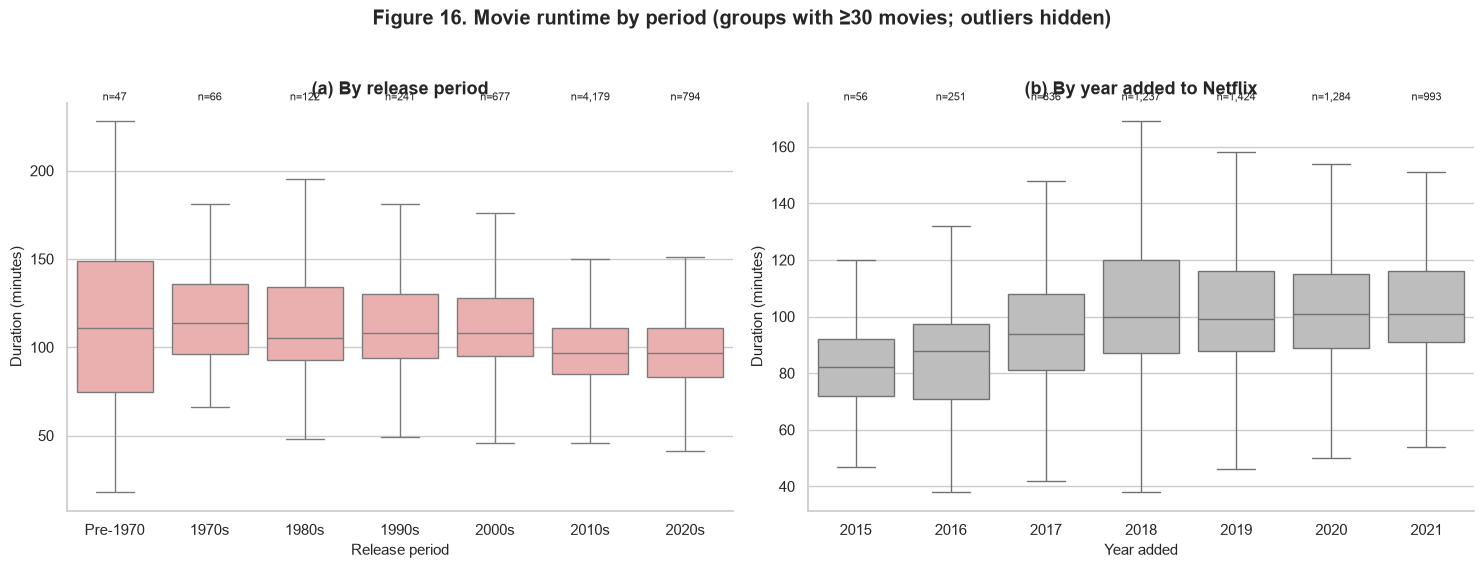

#### Interpretation
- **Observation:** Older release periods have longer median runtimes than the most recent ones; by year added, differences are smaller.
- **Evidence:** Median runtime by release period: Pre-1970 111 min (n=47), 1970s 114 min (n=66), 1980s 106 min (n=122), 1990s 108 min (n=241), 2000s 108 min (n=677), 2010s 97 min (n=4179), 2020s 97 min (n=794). By year added, medians range from 82 to 101 min.
- **Interpretation:** Movies released in the 2010s period are shorter on median (97 min) than those from 1970s (114 min) – a catalog-composition difference, consistent with the weak negative correlation in Section 8.
- **Limitation:** Older films in the catalog are a selected subset; recent periods include more specials, stand-up and children's titles, which are often short.

In [37]:
mov = df.loc[is_movie & df["movie_duration_minutes"].notna()].copy()
mov["minutes"] = mov["movie_duration_minutes"].astype(float)

def dur_stats(frame, by):
    t = frame.groupby(by, observed=True)["minutes"].agg(
        movies="count", median="median", mean="mean",
        q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
    t["meets_rule"] = t["movies"] >= MIN_N_TREND
    return t

dur_rel = dur_stats(mov, "release_period")
dur_add = dur_stats(mov.dropna(subset=["added_year"]).assign(added_year=lambda d: d["added_year"].astype(int)), "added_year")
print("Movie runtime by release period:"); display(dur_rel.round(1))
print("Movie runtime by year added:"); display(dur_add.round(1))
excluded_periods = list(dur_rel.index[~dur_rel["meets_rule"]].astype(str)) + list(dur_add.index[~dur_add["meets_rule"]].astype(str))
print("Groups excluded from the chart (< MIN_N_TREND movies):", excluded_periods if excluded_periods else "none")

rel_ok = [str(p) for p in dur_rel.index[dur_rel["meets_rule"]]]
add_ok = [int(y) for y in dur_add.index[dur_add["meets_rule"]]]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
d1 = mov[mov["release_period"].astype(str).isin(rel_ok)].assign(release_period=lambda d: d["release_period"].astype(str))
sns.boxplot(data=d1, x="release_period", y="minutes", order=rel_ok, color="#F4A6A6", showfliers=False, ax=axes[0])
for i, p in enumerate(rel_ok):
    axes[0].text(i, axes[0].get_ylim()[1], f"n={int(dur_rel.loc[p, 'movies']):,}", ha="center", va="bottom", fontsize=8)
axes[0].set(title="(a) By release period", xlabel="Release period", ylabel="Duration (minutes)")
d2 = mov[mov["added_year"].isin(add_ok)].assign(added_year=lambda d: d["added_year"].astype(int))
sns.boxplot(data=d2, x="added_year", y="minutes", order=add_ok, color="#BDBDBD", showfliers=False, ax=axes[1])
for i, y in enumerate(add_ok):
    axes[1].text(i, axes[1].get_ylim()[1], f"n={int(dur_add.loc[y, 'movies']):,}", ha="center", va="bottom", fontsize=8)
axes[1].set(title="(b) By year added to Netflix", xlabel="Year added", ylabel="Duration (minutes)")
fig.suptitle(f"Figure 16. Movie runtime by period (groups with ≥{MIN_N_TREND} movies; outliers hidden)", fontweight="bold", y=1.03)
save_fig(fig, "16_movie_runtime_by_period.png")

ok_rel = dur_rel[dur_rel["meets_rule"]]
longest_p = ok_rel["median"].idxmax(); shortest_p = ok_rel["median"].idxmin()
RESULTS.update(dur_longest_period=str(longest_p), dur_longest_median=float(ok_rel.loc[longest_p, "median"]),
               dur_shortest_period=str(shortest_p), dur_shortest_median=float(ok_rel.loc[shortest_p, "median"]))
ok_add = dur_add[dur_add["meets_rule"]]
interpret(
    f"Older release periods have longer median runtimes than the most recent ones; by year added, differences are smaller.",
    f"Median runtime by release period: " + ", ".join(f"{p} {r['median']:.0f} min (n={int(r['movies'])})" for p, r in ok_rel.iterrows()) +
    f". By year added, medians range from {ok_add['median'].min():.0f} to {ok_add['median'].max():.0f} min.",
    f"Movies released in the {shortest_p} period are shorter on median ({ok_rel.loc[shortest_p, 'median']:.0f} min) than those from "
    f"{longest_p} ({ok_rel.loc[longest_p, 'median']:.0f} min) – a catalog-composition difference, consistent with the weak negative correlation in Section 8.",
    "Older films in the catalog are a selected subset; recent periods include more specials, stand-up and children's titles, which are often short.")

### 9.6 Do TV Shows show changes in the distribution of seasons over time?
Seasons are grouped as 1, 2 and 3+; only addition years with at least `MIN_N_TREND` TV Shows are shown. Interpretation is cautious because season counts are **right-censored** (recent shows have had less time to accumulate seasons).

,1 season,2 seasons,3+ seasons,1 season %,2 seasons %,3+ seasons %,mean seasons
added_year,,,,,,,
2016,139,17,19,79.40,9.70,10.90,1.49
2017,253,41,55,72.50,11.70,15.80,1.68
2018,291,61,59,70.80,14.80,14.40,1.68
2019,414,103,75,69.90,17.40,12.70,1.57
2020,383,97,115,64.40,16.30,19.30,1.85
2021,294,98,113,58.20,19.40,22.40,1.96


Excluded addition years (< MIN_N_TREND TV Shows): [2008, 2013, 2014, 2015]
Seasons by release period (TV Shows):


,shows,mean,share_one,meets_rule
release_period,,,,
Pre-1970,5,3.00,60.00,False
1970s,4,4.00,50.00,False
1980s,7,2.29,71.43,False
1990s,33,3.03,54.55,True
2000s,130,1.96,70.77,True
2010s,1734,1.72,67.88,True
2020s,751,1.71,65.78,True


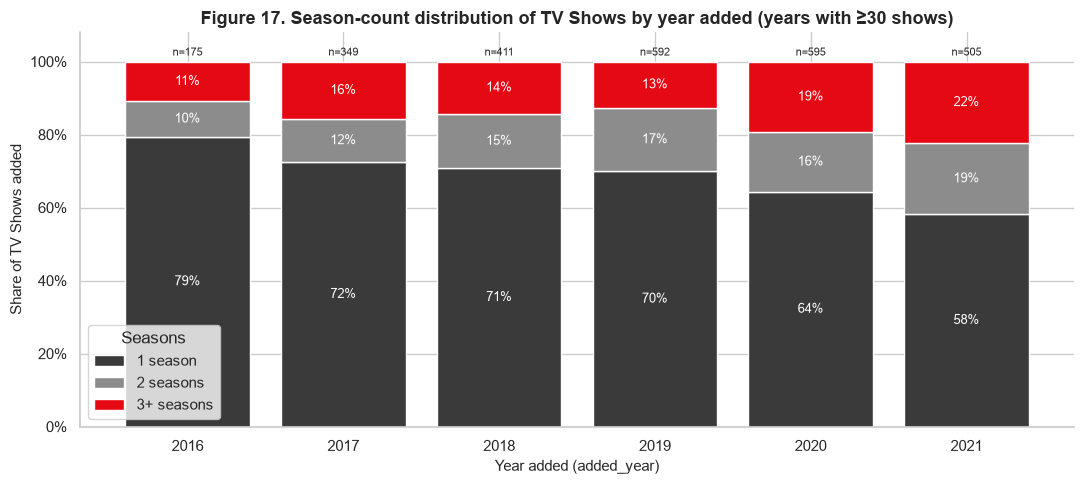

#### Interpretation
- **Observation:** Single-season shows are the majority among TV Shows added in every eligible year.
- **Evidence:** 1-season share ranges from 58.2% (2021) to 79.4% (2016); mean seasons ranges from 1.49 to 1.96. By release period, the 1-season share is 1990s: 55% (n=33), 2000s: 71% (n=130), 2010s: 68% (n=1734), 2020s: 66% (n=751).
- **Interpretation:** The TV catalog is consistently dominated by short series, with no strong monotonic change in the season mix across addition years.
- **Limitation:** Season counts are right-censored and represent the seasons available at snapshot time; changes may reflect the age of shows rather than any shift in how series are made.

In [38]:
tvdf = df.loc[is_tv & df["tv_seasons"].notna() & df["added_year"].notna()].copy()
tvdf["season_group"] = pd.cut(tvdf["tv_seasons"].astype(int), bins=[0, 1, 2, np.inf], labels=["1 season", "2 seasons", "3+ seasons"])
tv_n = tvdf.groupby("added_year").size()
tv_ok_years = tv_n[tv_n >= MIN_N_TREND].index
sg = pd.crosstab(tvdf["added_year"], tvdf["season_group"]).loc[tv_ok_years]
sg_pct = sg.div(sg.sum(axis=1), axis=0) * 100
mean_seasons = tvdf.groupby("added_year")["tv_seasons"].mean().loc[tv_ok_years]
tbl = pd.concat([sg, sg_pct.add_suffix(" %").round(1), mean_seasons.rename("mean seasons").round(2)], axis=1)
display(tbl)
print("Excluded addition years (< MIN_N_TREND TV Shows):", [int(y) for y in tv_n.index if y not in tv_ok_years])

tv_rel = df.loc[is_tv & df["tv_seasons"].notna()].groupby("release_period", observed=True)["tv_seasons"].agg(
    shows="count", mean="mean", share_one=lambda s: pct((s == 1).sum(), len(s)))
tv_rel["meets_rule"] = tv_rel["shows"] >= MIN_N_TREND
print("Seasons by release period (TV Shows):"); display(tv_rel.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(sg_pct))
cols_ = ["#3A3A3A", "#8C8C8C", "#E50914"]
for c, colr in zip(sg_pct.columns, cols_):
    ax.bar(sg_pct.index.astype(int).astype(str), sg_pct[c].values, bottom=bottom, color=colr, label=c)
    for i, (v, b) in enumerate(zip(sg_pct[c].values, bottom)):
        if v >= 4:
            ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    bottom += sg_pct[c].values
for i, n in enumerate(sg.sum(axis=1)):
    ax.text(i, 101, f"n={n:,}", ha="center", va="bottom", fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 108)
ax.set(title=f"Figure 17. Season-count distribution of TV Shows by year added (years with ≥{MIN_N_TREND} shows)",
       xlabel="Year added (added_year)", ylabel="Share of TV Shows added")
ax.legend(title="Seasons", loc="lower left")
save_fig(fig, "17_tv_seasons_by_added_year.png")

interpret(
    "Single-season shows are the majority among TV Shows added in every eligible year.",
    f"1-season share ranges from {sg_pct['1 season'].min():.1f}% ({int(sg_pct['1 season'].idxmin())}) to "
    f"{sg_pct['1 season'].max():.1f}% ({int(sg_pct['1 season'].idxmax())}); mean seasons ranges from "
    f"{mean_seasons.min():.2f} to {mean_seasons.max():.2f}. By release period, the 1-season share is "
    + ", ".join(f"{p}: {r['share_one']:.0f}% (n={int(r['shows'])})" for p, r in tv_rel[tv_rel['meets_rule']].iterrows()) + ".",
    "The TV catalog is consistently dominated by short series, with no strong monotonic change in the season mix across addition years.",
    "Season counts are right-censored and represent the seasons available at snapshot time; changes may reflect the age of shows rather than any shift in how series are made.")

## 9.1 Relationship Between Release Year and Popular Content Types

> **Definition and limitation.** The dataset contains **no** viewer counts, rating scores, watch time or engagement metrics. Therefore "popular content types" are defined here as **the genres/categories with the highest number of titles** in the catalog (*catalog prevalence*). Genre frequency is a **proxy for prevalence in the catalog, not a measure of audience popularity**.

**Time variable.** This section uses `release_year` (when a title was originally released), **not** `added_year` (when Netflix added it). The question is therefore *"what is the genre composition of catalog titles from each release era?"*, not *"what did Netflix add each year?"*.

**Method**

- The exploded `genre_long` table is used, so each category in `listed_in` is counted separately (the full comma-separated string is never treated as one category).
- **Raw counts** show volume; **percentages** show composition and stop large periods (e.g. the 2010s) from appearing dominant merely because they contain more titles. Two percentages are used:
  - *Title share* = % of titles in a period carrying the genre (multi-label, so shares can sum to more than 100%).
  - *Tag share* = % of all genre tags in a period (sums to 100%; used for the 100% stacked chart).
- **Sample-size rules:** yearly results only for release years with **≥ `MIN_TITLES_YEAR` = 20 titles**; release decades with sparse data are pooled into a single early period of **≥ `MIN_TITLES_PERIOD` = 50 titles**; Movie/TV subgroups are reported only where the subgroup has ≥ 20 titles.

In [39]:
G = genre_long[genre_long["genre"] != UNKNOWN_LABEL].dropna(subset=["release_year"]).copy()
G["release_year"] = G["release_year"].astype(int)
titles_year = df.dropna(subset=["release_year"]).groupby(df["release_year"].dropna().astype(int)).size()
eligible_years = titles_year[titles_year >= MIN_TITLES_YEAR].index
print(f"Threshold: ≥{MIN_TITLES_YEAR} titles per release year -> {len(eligible_years)} of {len(titles_year)} release years retained "
      f"({int(titles_year[eligible_years].sum()):,} titles = {pct(titles_year[eligible_years].sum(), N):.1f}% of catalog). "
      f"Earliest retained year: {int(eligible_years.min())}.")

gy_counts = G.groupby(["release_year", "genre"])["show_id"].nunique().unstack(fill_value=0)
gy_share = gy_counts.div(titles_year.reindex(gy_counts.index), axis=0) * 100

TOP10_GENRES = list(g_counts.head(10).index)
TOP5_GENRES = TOP10_GENRES[:5]

# Yearly table: total titles, leading genre, its count and share (eligible years only)
yearly = pd.DataFrame({
    "total_titles": titles_year.loc[eligible_years],
    "leading_genre": gy_counts.loc[eligible_years].idxmax(axis=1),
    "leading_count": gy_counts.loc[eligible_years].max(axis=1),
})
yearly["leading_share_%"] = (yearly["leading_count"] / yearly["total_titles"] * 100).round(1)
print("Leading genre per release year (years with ≥20 titles):")
display(yearly)

print("Title share (%) of the overall top-10 genres per eligible release year (last 15 eligible years shown):")
display(gy_share.loc[eligible_years, TOP10_GENRES].round(1).tail(15))

Threshold: ≥20 titles per release year -> 31 of 74 release years retained (8,522 titles = 97.0% of catalog). Earliest retained year: 1990.
Leading genre per release year (years with ≥20 titles):


,total_titles,leading_genre,leading_count,leading_share_%
release_year,,,,
1990,22,Dramas,10,45.50
1992,23,Action & Adventure,6,26.10
1993,28,Dramas,15,53.60
1994,22,Dramas,9,40.90
1995,25,Dramas,10,40.00
1996,24,Comedies,12,50.00
1997,38,Comedies,14,36.80
1998,36,Comedies,16,44.40
1999,39,Comedies,13,33.30


Title share (%) of the overall top-10 genres per eligible release year (last 15 eligible years shown):


genre,International Movies,Dramas,Comedies,International TV Shows,Documentaries,Action & Adventure,TV Dramas,Independent Movies,Children & Family Movies,Romantic Movies
release_year,,,,,,,,,,
2007,36.40,36.40,34.10,4.50,4.50,17.00,3.40,6.80,10.20,11.40
2008,34.80,36.30,31.90,8.10,3.70,17.80,3.00,7.40,9.60,9.60
2009,32.90,27.00,27.60,13.80,2.00,13.80,7.20,7.90,9.90,10.50
2010,39.10,34.40,27.10,11.50,4.20,15.10,6.80,7.30,9.40,14.10
2011,29.70,32.40,27.60,12.40,3.80,14.10,4.90,6.50,14.10,12.40
2012,33.90,28.00,25.80,14.80,4.70,12.30,7.20,10.60,8.90,8.10
2013,42.30,29.00,22.70,13.60,10.50,10.10,5.90,11.20,11.90,5.60
2014,36.10,29.50,22.40,13.40,8.80,8.00,6.20,9.90,8.20,8.80
2015,37.80,32.30,16.90,16.80,12.10,9.50,9.00,11.70,4.10,7.20


### 9.1.1 Movies and TV Shows separately by release year
Each type is evaluated separately; a release year is shown for a type only if that type has ≥ 20 titles in that year.

In [40]:
def yearly_leading_by_type(t):
    sub_titles = df[df["type"].eq(t).fillna(False)].dropna(subset=["release_year"])
    ty = sub_titles.groupby(sub_titles["release_year"].astype(int)).size()
    ok = ty[ty >= MIN_TITLES_YEAR].index
    c = G[G["type"] == t].groupby(["release_year", "genre"])["show_id"].nunique().unstack(fill_value=0).reindex(ok, fill_value=0)
    out = pd.DataFrame({"titles": ty.loc[ok], "leading_genre": c.idxmax(axis=1), "count": c.max(axis=1)})
    out["share_%"] = (out["count"] / out["titles"] * 100).round(1)
    return out

yl_movie = yearly_leading_by_type("Movie")
yl_tv = yearly_leading_by_type("TV Show")
print(f"Movies: {len(yl_movie)} release years with ≥{MIN_TITLES_YEAR} movies (from {yl_movie.index.min()}); "
      f"TV Shows: {len(yl_tv)} release years with ≥{MIN_TITLES_YEAR} shows (from {yl_tv.index.min()}).")
display(pd.concat({"Movies": yl_movie, "TV Shows": yl_tv}, axis=1).tail(20))
print("Frequency of each leading genre across eligible years:")
display(pd.concat({"Movies": yl_movie["leading_genre"].value_counts(), "TV Shows": yl_tv["leading_genre"].value_counts()}, axis=1).fillna(0).astype(int))

Movies: 30 release years with ≥20 movies (from 1992); TV Shows: 14 release years with ≥20 shows (from 2008).


Movies                                     TV Shows                                       
             titles         leading_genre count share_%   titles           leading_genre  count share_%
release_year                                                                                           
2002             44                Dramas    21   47.70      NaN                    <NA>    NaN     NaN
2003             51              Comedies    21   41.20      NaN                    <NA>    NaN     NaN
2004             55  International Movies    29   52.70      NaN                    <NA>    NaN     NaN
2005             67  International Movies    29   43.30      NaN                    <NA>    NaN     NaN
2006             82  International Movies    41   50.00      NaN                    <NA>    NaN     NaN
2007             74                Dramas    32   43.20      NaN                    <NA>    NaN     NaN
2008            113                Dramas    49   43.40    22.00  International TV Shows  11.00   50.00
2009            118  International Movies    50   42.40    34.00  International TV Shows  21.00   61.80
2010            153  International Movies    75   49.00    39.00  International TV Shows  22.00   56.40
2011            145                Dramas    60   41.40    40.00  International TV Shows  23.00   57.50
2012            173  International Movies    80   46.20    63.00  International TV Shows  35.00   55.60
2013            225  International Movies   121   53.80    61.00  International TV Shows  39.00   63.90
2014            264  International Movies   127   48.10    88.00  International TV Shows  47.00   53.40
2015            396  International Movies   210   53.00   159.00  International TV Shows  93.00   58.50
2016            658  International Movies   305   46.40   243.00  International TV Shows 133.00   54.70
2017            765  International Movies   328   42.90   265.00  International TV Shows 136.00   51.30
2018            767  International Movies   340   44.30   379.00  International TV Shows 190.00   50.10
2019            633  International Movies   282   44.50   397.00  International TV Shows 201.00   50.60
2020            517  International Movies   239   46.20   436.00  International TV Shows 214.00   49.10
2021            277  International Movies   141   50.90   315.00  International TV Shows 149.00   47.30

Frequency of each leading genre across eligible years:


,Movies,TV Shows
leading_genre,,
International Movies,15,0
Dramas,7,0
Comedies,7,0
Action & Adventure,1,0
International TV Shows,0,14


### 9.1.2 Decade-level results
Raw decades are shown first (with a sample-size flag), followed by the **pooled release periods** used in the charts.

In [41]:
# Raw decades: top genre, count, share (flagged when below MIN_TITLES_PERIOD)
G["release_decade"] = (G["release_year"] // 10 * 10)
titles_dec = df.dropna(subset=["release_decade"]).groupby(df["release_decade"].dropna().astype(int)).size()
gd_counts = G.groupby(["release_decade", "genre"])["show_id"].nunique().unstack(fill_value=0)
decade_table = pd.DataFrame({
    "titles": titles_dec,
    "top_genre": gd_counts.idxmax(axis=1),
    "top_genre_count": gd_counts.max(axis=1),
})
decade_table["top_genre_share_%"] = (decade_table["top_genre_count"] / decade_table["titles"] * 100).round(1)
decade_table["sample_ok (≥50)"] = decade_table["titles"] >= MIN_TITLES_PERIOD
decade_table.index = [f"{d}s" for d in decade_table.index]
print("Top genre for every release decade:")
display(decade_table)

# Pooled release periods
titles_per = df.groupby("release_period", observed=True).size()
gp_counts = G.groupby(["release_period", "genre"], observed=True)["show_id"].nunique().unstack(fill_value=0).reindex(PERIOD_ORDER)
gp_share = gp_counts.div(titles_per.reindex(PERIOD_ORDER), axis=0) * 100          # title share
gp_tag_share = gp_counts.div(gp_counts.sum(axis=1), axis=0) * 100                 # tag share (sums to 100)

period_table = pd.DataFrame({
    "titles": titles_per.reindex(PERIOD_ORDER),
    "top_genre": gp_counts.idxmax(axis=1),
    "top_genre_count": gp_counts.max(axis=1),
})
period_table["top_genre_share_%"] = (period_table["top_genre_count"] / period_table["titles"] * 100).round(1)
print(f"Leading genre per pooled release period (sparse decades pooled into '{PERIOD_ORDER[0]}'):")
display(period_table)

# Top 5 genres per period
top5_rows = {}
for p in PERIOD_ORDER:
    s = gp_counts.loc[p].sort_values(ascending=False).head(5)
    top5_rows[p] = [f"{g} ({int(n)}, {pct(n, titles_per[p]):.0f}%)" for g, n in s.items()]
top5_per_period = pd.DataFrame(top5_rows, index=[f"#{i}" for i in range(1, 6)]).T
print("Top 5 genres per release period – genre (count, title share):")
display(top5_per_period)

Top genre for every release decade:


,titles,top_genre,top_genre_count,top_genre_share_%,sample_ok (≥50)
1920s,1,TV Shows,1,100.00,False
1940s,15,Documentaries,13,86.70,False
1950s,11,Classic Movies,10,90.90,False
1960s,25,Classic Movies,18,72.00,False
1970s,70,Classic Movies,32,45.70,True
1980s,129,Dramas,57,44.20,True
1990s,274,Dramas,102,37.20,True
2000s,807,International Movies,286,35.40,True
2010s,5913,International Movies,1923,32.50,True
2020s,1545,International Movies,380,24.60,True


Leading genre per pooled release period (sparse decades pooled into 'Pre-1970'):


,titles,top_genre,top_genre_count,top_genre_share_%
release_period,,,,
Pre-1970,52,Classic Movies,39,75.00
1970s,70,Classic Movies,32,45.70
1980s,129,Dramas,57,44.20
1990s,274,Dramas,102,37.20
2000s,807,International Movies,286,35.40
2010s,5913,International Movies,1923,32.50
2020s,1545,International Movies,380,24.60


Top 5 genres per release period – genre (count, title share):


,#1,#2,#3,#4,#5
Pre-1970,"Classic Movies (39, 75%)","Dramas (23, 44%)","Documentaries (13, 25%)","International Movies (12, 23%)","Comedies (8, 15%)"
1970s,"Classic Movies (32, 46%)","International Movies (30, 43%)","Dramas (29, 41%)","Action & Adventure (22, 31%)","Comedies (18, 26%)"
1980s,"Dramas (57, 44%)","International Movies (53, 41%)","Action & Adventure (43, 33%)","Comedies (35, 27%)","Classic Movies (23, 18%)"
1990s,"Dramas (102, 37%)","Comedies (91, 33%)","International Movies (68, 25%)","Action & Adventure (65, 24%)","Romantic Movies (27, 10%)"
2000s,"International Movies (286, 35%)","Dramas (273, 34%)","Comedies (266, 33%)","Action & Adventure (150, 19%)","Romantic Movies (97, 12%)"
2010s,"International Movies (1923, 33%)","Dramas (1655, 28%)","Comedies (1053, 18%)","International TV Shows (919, 16%)","Documentaries (687, 12%)"
2020s,"International Movies (380, 25%)","International TV Shows (363, 23%)","Dramas (287, 19%)","TV Dramas (210, 14%)","Comedies (203, 13%)"


### 9.1.3 Change in genre share between the earliest and latest sufficiently populated periods

In [42]:
P_EARLY, P_LATE = PERIOD_ORDER[0], PERIOD_ORDER[-1]
chg = pd.DataFrame({
    f"{P_EARLY} count": gp_counts.loc[P_EARLY], f"{P_EARLY} share %": gp_share.loc[P_EARLY],
    f"{P_LATE} count": gp_counts.loc[P_LATE], f"{P_LATE} share %": gp_share.loc[P_LATE],
})
chg["change (pp)"] = chg[f"{P_LATE} share %"] - chg[f"{P_EARLY} share %"]
print(f"Earliest period: {P_EARLY} (n = {int(titles_per[P_EARLY])}); latest period: {P_LATE} (n = {int(titles_per[P_LATE]):,}).")
print("Overall top-10 genres:")
display(chg.loc[TOP10_GENRES].round(1).sort_values("change (pp)", ascending=False))
# Gainers/losers among genres with at least 10 titles in either period
big = chg[(chg[f"{P_EARLY} count"] >= 10) | (chg[f"{P_LATE} count"] >= 10)]
print("Largest increases / decreases in title share (genres with ≥10 titles in either period):")
display(pd.concat([big.nlargest(5, "change (pp)"), big.nsmallest(5, "change (pp)")]).round(1))

# Also compare the two most recent fully populated complete decades to avoid relying on the small early pool
p_prev = PERIOD_ORDER[-2]
chg2 = (gp_share.loc[P_LATE] - gp_share.loc[p_prev]).loc[TOP10_GENRES].sort_values(ascending=False)
print(f"Change in title share, {p_prev} -> {P_LATE} (top-10 genres, pp):")
display(chg2.round(1).to_frame("change (pp)").T)
RESULTS.update(P_EARLY=P_EARLY, P_LATE=P_LATE, chg=chg, period_table=period_table, gp_share=gp_share, gp_counts=gp_counts,
               titles_per=titles_per)

Earliest period: Pre-1970 (n = 52); latest period: 2020s (n = 1,545).
Overall top-10 genres:


,Pre-1970 count,Pre-1970 share %,2020s count,2020s share %,change (pp)
genre,,,,,
International TV Shows,0,0.00,363,23.50,23.50
TV Dramas,0,0.00,210,13.60,13.60
Children & Family Movies,2,3.80,123,8.00,4.10
International Movies,12,23.10,380,24.60,1.50
Independent Movies,3,5.80,62,4.00,-1.80
Romantic Movies,4,7.70,86,5.60,-2.10
Comedies,8,15.40,203,13.10,-2.20
Action & Adventure,8,15.40,83,5.40,-10.00
Documentaries,13,25.00,130,8.40,-16.60


Largest increases / decreases in title share (genres with ≥10 titles in either period):


,Pre-1970 count,Pre-1970 share %,2020s count,2020s share %,change (pp)
genre,,,,,
International TV Shows,0,0.00,363,23.50,23.50
TV Dramas,0,0.00,210,13.60,13.60
TV Comedies,1,1.90,177,11.50,9.50
Crime TV Shows,0,0.00,134,8.70,8.70
Docuseries,0,0.00,131,8.50,8.50
Classic Movies,39,75.00,0,0.00,-75.00
Dramas,23,44.20,287,18.60,-25.70
Documentaries,13,25.00,130,8.40,-16.60
Action & Adventure,8,15.40,83,5.40,-10.00


Change in title share, 2010s -> 2020s (top-10 genres, pp):


genre,International TV Shows,TV Dramas,Children & Family Movies,Romantic Movies,Action & Adventure,Documentaries,Comedies,Independent Movies,International Movies,Dramas
change (pp),8.00,4.80,1.20,-1.00,-2.90,-3.20,-4.70,-6.20,-7.90,-9.40


### 9.1.4 Visualizations

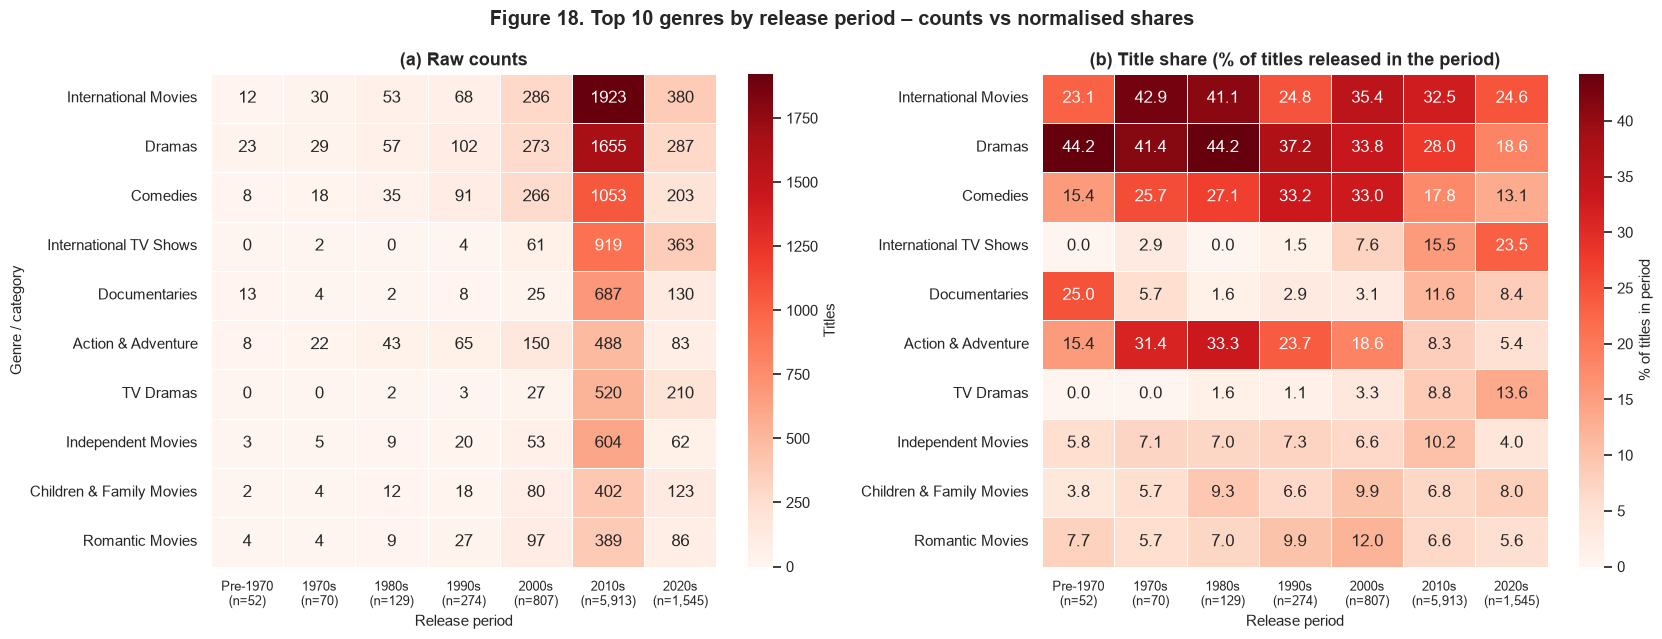

#### Interpretation
- **Observation:** In raw counts almost every top genre peaks in the 2010s period, while the shares reveal a compositional shift: 'Dramas' leads among the oldest releases and 'International Movies' leads among the newest.
- **Evidence:** Pre-1970: 'Dramas' 44.2% of titles (n = 52); 2020s: 'International Movies' 24.6% (n = 1,545). 10 of the 10 genres have their highest raw count in 2010s.
- **Interpretation:** The catalog composition shifts across release eras; count-based dominance of the 2010s is largely a volume effect that the share panel corrects.
- **Limitation:** Genre frequency is a proxy for catalog prevalence and does not represent actual viewership or audience preference; early periods have small n.

In [43]:
hm_counts = gp_counts[TOP10_GENRES].T
hm_share = gp_share[TOP10_GENRES].T
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(hm_counts, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, ax=axes[0], cbar_kws={"label": "Titles"})
axes[0].set(title="(a) Raw counts", xlabel="Release period", ylabel="Genre / category")
sns.heatmap(hm_share, annot=True, fmt=".1f", cmap="Reds", linewidths=0.5, ax=axes[1], cbar_kws={"label": "% of titles in period"})
axes[1].set(title="(b) Title share (% of titles released in the period)", xlabel="Release period", ylabel="")
for a in axes:
    a.set_xticklabels([f"{p}\n(n={int(titles_per[p]):,})" for p in PERIOD_ORDER], rotation=0, fontsize=9)
fig.suptitle("Figure 18. Top 10 genres by release period – counts vs normalised shares", fontweight="bold")
save_fig(fig, "18_genre_heatmap_by_release_period.png")

lead_early = hm_share[P_EARLY].idxmax(); lead_late = hm_share[P_LATE].idxmax()
peak_period_counts = hm_counts.idxmax(axis=1).value_counts()
interpret(
    f"In raw counts almost every top genre peaks in the {peak_period_counts.index[0]} period, while the shares reveal a compositional shift: "
    f"'{lead_early}' leads among the oldest releases and '{lead_late}' leads among the newest.",
    f"{P_EARLY}: '{lead_early}' {hm_share.loc[lead_early, P_EARLY]:.1f}% of titles (n = {int(titles_per[P_EARLY])}); "
    f"{P_LATE}: '{lead_late}' {hm_share.loc[lead_late, P_LATE]:.1f}% (n = {int(titles_per[P_LATE]):,}). "
    f"{peak_period_counts.iloc[0]} of the 10 genres have their highest raw count in {peak_period_counts.index[0]}.",
    "The catalog composition shifts across release eras; count-based dominance of the 2010s is largely a volume effect that the share panel corrects.",
    "Genre frequency is a proxy for catalog prevalence and does not represent actual viewership or audience preference; early periods have small n.")

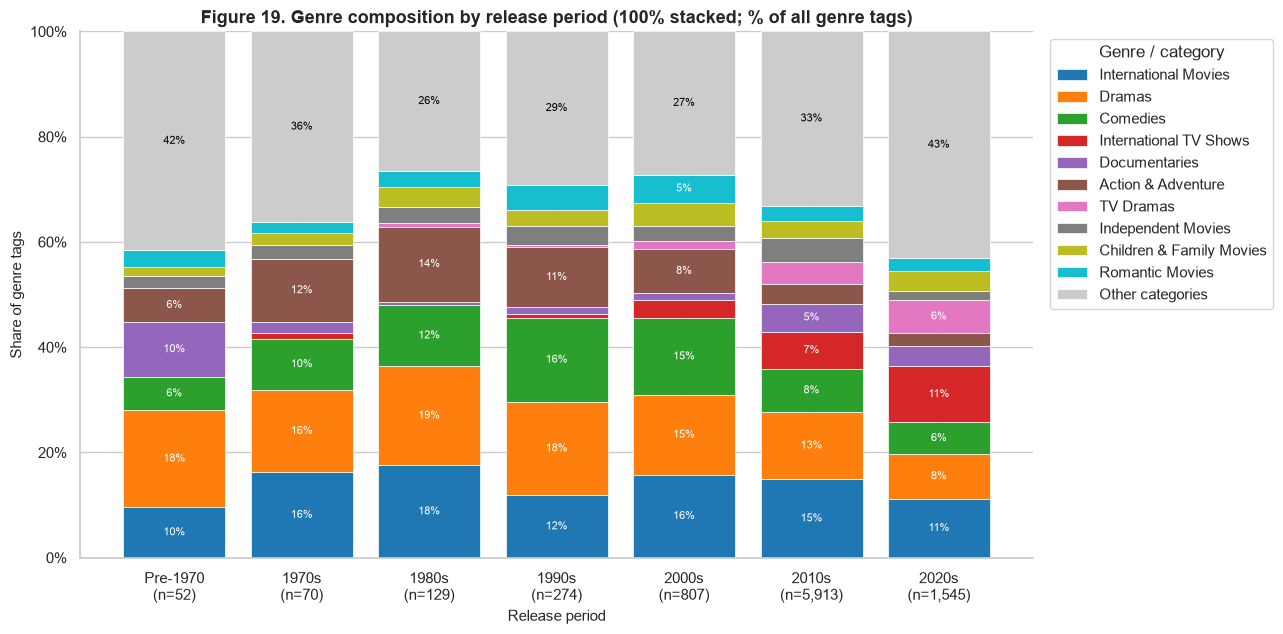

#### Interpretation
- **Observation:** The composition of genre tags changes markedly: classic-film tags dominate the earliest period and disappear in recent periods, while international and TV categories grow.
- **Evidence:** International (Movies + TV) tag share: Pre-1970 9.6% → 2020s 21.9%. 'Classic Movies' tag share: Pre-1970 31.2% → 2020s 0.0%. 'Other categories' share: Pre-1970 41.6% → 2020s 43.1%.
- **Interpretation:** Recent release periods in the catalog are more international and more TV-oriented in their category composition.
- **Limitation:** 'Classic' is partly defined by age, so its decline is partly definitional; tag shares are a proxy for prevalence, not audience popularity.

In [44]:
TOPK_STACK = 10
tag = gp_tag_share.copy()
stack = tag[TOP10_GENRES[:TOPK_STACK]].copy()
stack["Other categories"] = 100 - stack.sum(axis=1)
colors = sns.color_palette("tab10", TOPK_STACK) + [(0.8, 0.8, 0.8)]
fig, ax = plt.subplots(figsize=(13, 6.5))
bottom = np.zeros(len(stack))
xl = [f"{p}\n(n={int(titles_per[p]):,})" for p in stack.index]
for col, colr in zip(stack.columns, colors):
    ax.bar(xl, stack[col].values, bottom=bottom, color=colr, label=col, edgecolor="white", linewidth=0.5)
    for i, (v, b) in enumerate(zip(stack[col].values, bottom)):
        if v >= 5:
            ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if col != "Other categories" else "black")
    bottom += stack[col].values
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 100)
ax.set(title="Figure 19. Genre composition by release period (100% stacked; % of all genre tags)",
       xlabel="Release period", ylabel="Share of genre tags")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", title="Genre / category")
save_fig(fig, "19_genre_share_stacked_by_period.png")

intl_cols = [g for g in ["International Movies", "International TV Shows"] if g in stack.columns]
intl_early = stack.loc[P_EARLY, intl_cols].sum(); intl_late = stack.loc[P_LATE, intl_cols].sum()
classic_early = tag.loc[P_EARLY, "Classic Movies"] if "Classic Movies" in tag.columns else np.nan
classic_late = tag.loc[P_LATE, "Classic Movies"] if "Classic Movies" in tag.columns else np.nan
RESULTS.update(intl_tag_early=intl_early, intl_tag_late=intl_late, classic_tag_early=classic_early, classic_tag_late=classic_late)
interpret(
    "The composition of genre tags changes markedly: classic-film tags dominate the earliest period and disappear in recent periods, while international and TV categories grow.",
    f"International (Movies + TV) tag share: {P_EARLY} {intl_early:.1f}% → {P_LATE} {intl_late:.1f}%. "
    f"'Classic Movies' tag share: {P_EARLY} {classic_early:.1f}% → {P_LATE} {classic_late:.1f}%. "
    f"'Other categories' share: {P_EARLY} {stack.loc[P_EARLY, 'Other categories']:.1f}% → {P_LATE} {stack.loc[P_LATE, 'Other categories']:.1f}%.",
    "Recent release periods in the catalog are more international and more TV-oriented in their category composition.",
    "'Classic' is partly defined by age, so its decline is partly definitional; tag shares are a proxy for prevalence, not audience popularity.")

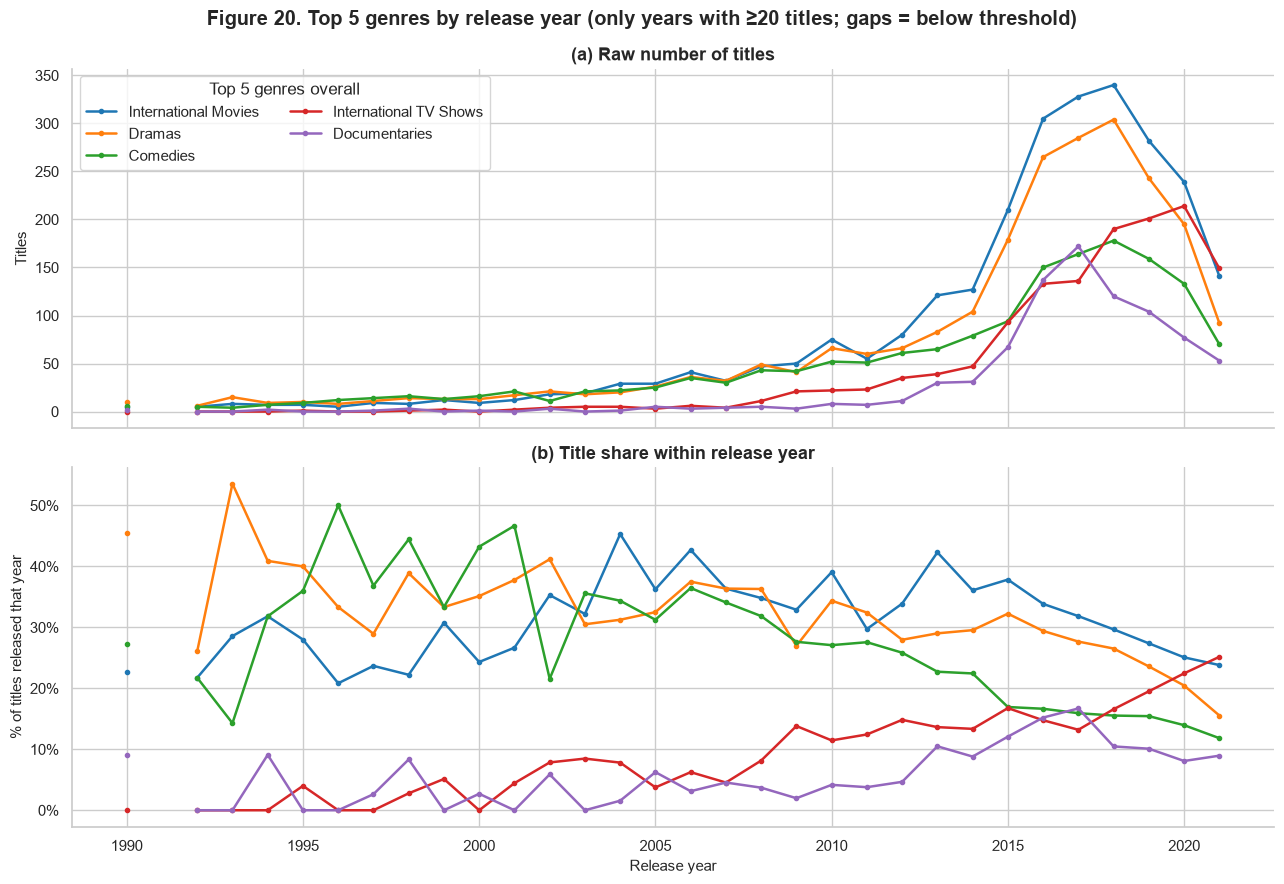

#### Interpretation
- **Observation:** Counts for all top-5 genres rise to a peak in the late 2010s and fall for the latest release years; in shares, International TV Shows increase most visibly in recent release years.
- **Evidence:** Average yearly title share, eligible years before 2000 vs 2015 onward: International Movies: 25.6% → 29.9%; Dramas: 37.8% → 25.1%; Comedies: 32.9% → 15.2%; International TV Shows: 1.3% → 18.3%; Documentaries: 3.2% → 11.7%. Years before 2000 used: 9; years 2015+ used: 7.
- **Interpretation:** Volume growth in recent years affects all genres; normalised shares indicate which genres became relatively more or less prevalent among catalog titles.
- **Limitation:** Yearly shares are noisy even above the threshold; genre frequency does not measure audience preference.

In [45]:
full_years = range(int(eligible_years.min()), int(titles_year.index.max()) + 1)
cnt5 = gy_counts.reindex(full_years)[TOP5_GENRES].copy()
shr5 = gy_share.reindex(full_years)[TOP5_GENRES].copy()
mask_small = ~cnt5.index.isin(eligible_years)
cnt5.loc[mask_small] = np.nan; shr5.loc[mask_small] = np.nan    # years below threshold leave gaps instead of noisy points
pal5 = sns.color_palette("tab10", 5)
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for g, colr in zip(TOP5_GENRES, pal5):
    axes[0].plot(cnt5.index, cnt5[g], marker="o", markersize=3, lw=1.8, color=colr, label=g)
    axes[1].plot(shr5.index, shr5[g], marker="o", markersize=3, lw=1.8, color=colr, label=g)
axes[0].set(title="(a) Raw number of titles", ylabel="Titles")
axes[1].set(title="(b) Title share within release year", ylabel="% of titles released that year", xlabel="Release year")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].legend(title="Top 5 genres overall", ncol=2)
fig.suptitle(f"Figure 20. Top 5 genres by release year (only years with ≥{MIN_TITLES_YEAR} titles; gaps = below threshold)", fontweight="bold")
save_fig(fig, "20_top5_genres_by_release_year.png")

recent = [y for y in eligible_years if y >= 2015]
early_win = [y for y in eligible_years if y < 2000]
s_recent = gy_share.loc[recent, TOP5_GENRES].mean(); s_early = gy_share.loc[early_win, TOP5_GENRES].mean()
interpret(
    "Counts for all top-5 genres rise to a peak in the late 2010s and fall for the latest release years; in shares, International TV Shows increase most visibly in recent release years.",
    "Average yearly title share, eligible years before 2000 vs 2015 onward: " +
    "; ".join(f"{g}: {s_early[g]:.1f}% → {s_recent[g]:.1f}%" for g in TOP5_GENRES) +
    f". Years before 2000 used: {len(early_win)}; years 2015+ used: {len(recent)}.",
    "Volume growth in recent years affects all genres; normalised shares indicate which genres became relatively more or less prevalent among catalog titles.",
    "Yearly shares are noisy even above the threshold; genre frequency does not measure audience preference.")

### 9.1.5 Movies vs TV Shows – leading genres
Netflix category labels are type-specific (e.g. *Dramas* vs *TV Dramas*, *International Movies* vs *International TV Shows*). To compare like with like, categories are mapped to **broad genre families** with a transparent, documented mapping; labels without a counterpart keep their own name. Differences are tested with a two-proportion z-test (normal approximation, standard library only), with a Bonferroni correction for the number of comparisons. Because titles are multi-label, tests are indicative only.

,International Movies,International TV Shows,Dramas,TV Dramas,Comedies,TV Comedies,Action & Adventure,TV Action & Adventure,Documentaries,Docuseries,Children & Family Movies,Kids' TV,Romantic Movies,Romantic TV Shows,Horror Movies,TV Horror,Thrillers,TV Thrillers,TV Mysteries,Sci-Fi & Fantasy,TV Sci-Fi & Fantasy,Anime Features,Anime Series,Stand-Up Comedy,Stand-Up Comedy & Talk Shows,Classic Movies,Classic & Cult TV,Cult Movies,Crime TV Shows
family,International,International,Drama,Drama,Comedy,Comedy,Action & Adventure,Action & Adventure,Documentary,Documentary,Kids & Family,Kids & Family,Romance,Romance,Horror,Horror,Thriller & Mystery,Thriller & Mystery,Thriller & Mystery,Sci-Fi & Fantasy,Sci-Fi & Fantasy,Anime,Anime,Stand-Up & Talk,Stand-Up & Talk,Classic & Cult,Classic & Cult,Classic & Cult,Crime


,movies,movie_share_%,tv_shows,tv_share_%,diff_pp (Movie-TV),z,p_bonferroni,type_specific_label,"significant (α=0.05, Bonferroni)"
family,,,,,,,,,
International,2752,44.90,1349,50.60,-5.70,-4.94,0.00,False,True
Drama,2426,39.60,762,28.60,11.00,9.86,0.00,False,True
Comedy,1674,27.30,573,21.50,5.80,5.75,0.00,False,True
Documentary,869,14.20,394,14.80,-0.60,-0.74,1.00,False,False
Kids & Family,641,10.50,448,16.80,-6.40,-8.31,0.00,False,True
Action & Adventure,859,14.00,167,6.30,7.80,10.40,0.00,False,True
Romance,616,10.10,370,13.90,-3.80,-5.23,0.00,False,True
Independent Movies,756,12.30,0,0.00,12.30,18.97,0.00,True,True
Thriller & Mystery,577,9.40,147,5.50,3.90,6.11,0.00,False,True


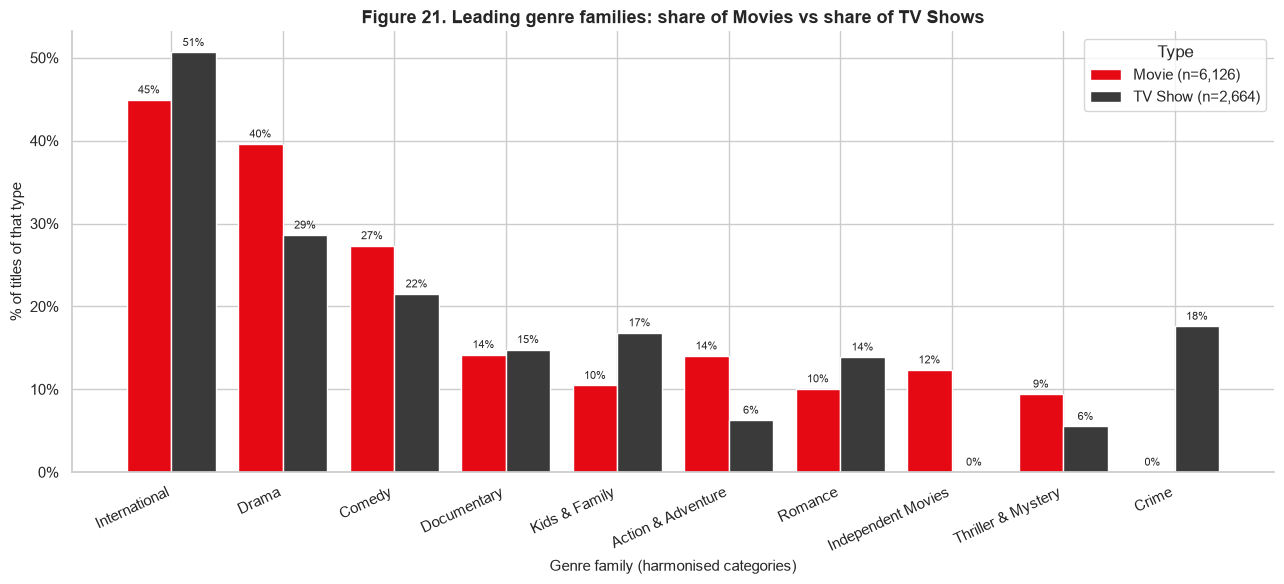

#### Interpretation
- **Observation:** 'International' is the most common family for Movies and 'International' for TV Shows, but the relative weight of several families differs by type.
- **Evidence:** Top Movie family: International (44.9% of Movies); top TV family: International (50.6% of TV Shows). Largest gap: Crime (-17.6 pp, Movie − TV). 9 of 10 differences are significant after Bonferroni correction.
- **Interpretation:** Movies and TV Shows in the catalog have different genre compositions (e.g. Drama/Comedy are more prevalent among Movies, Kids & Family/International/Crime-type labels relatively more among TV Shows, depending on the family).
- **Limitation:** The family mapping is an analyst choice; some labels exist for only one type. Multi-label titles violate the independence assumption of the z-test, so p-values are indicative. Frequency ≠ popularity.

In [46]:
FAMILY_MAP = {
    "International Movies": "International", "International TV Shows": "International",
    "Dramas": "Drama", "TV Dramas": "Drama",
    "Comedies": "Comedy", "TV Comedies": "Comedy",
    "Action & Adventure": "Action & Adventure", "TV Action & Adventure": "Action & Adventure",
    "Documentaries": "Documentary", "Docuseries": "Documentary",
    "Children & Family Movies": "Kids & Family", "Kids' TV": "Kids & Family",
    "Romantic Movies": "Romance", "Romantic TV Shows": "Romance",
    "Horror Movies": "Horror", "TV Horror": "Horror",
    "Thrillers": "Thriller & Mystery", "TV Thrillers": "Thriller & Mystery", "TV Mysteries": "Thriller & Mystery",
    "Sci-Fi & Fantasy": "Sci-Fi & Fantasy", "TV Sci-Fi & Fantasy": "Sci-Fi & Fantasy",
    "Anime Features": "Anime", "Anime Series": "Anime",
    "Stand-Up Comedy": "Stand-Up & Talk", "Stand-Up Comedy & Talk Shows": "Stand-Up & Talk",
    "Classic Movies": "Classic & Cult", "Classic & Cult TV": "Classic & Cult", "Cult Movies": "Classic & Cult",
    "Crime TV Shows": "Crime",
}
G["family"] = G["genre"].map(FAMILY_MAP).fillna(G["genre"])
display(pd.Series(FAMILY_MAP).rename("family").to_frame().T)

n_type = df["type"].value_counts()
fam = G.groupby(["family", "type"])["show_id"].nunique().unstack(fill_value=0)
fam = fam[order_types(fam.columns)]
fam_share = fam.div(n_type.reindex(fam.columns), axis=1) * 100
top_fams = fam.sum(axis=1).sort_values(ascending=False).head(10).index

tests = []
n_tests = len(top_fams)
for f_ in top_fams:
    x1, x2 = fam.loc[f_, "Movie"], fam.loc[f_, "TV Show"]
    n1, n2 = n_type["Movie"], n_type["TV Show"]
    p_pool = (x1 + x2) / (n1 + n2)
    se = math.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2)) if 0 < p_pool < 1 else np.nan
    z = (x1 / n1 - x2 / n2) / se if se and not np.isnan(se) else np.nan
    pval = math.erfc(abs(z) / math.sqrt(2)) if not np.isnan(z) else np.nan
    tests.append({"family": f_, "movies": int(x1), "movie_share_%": round(pct(x1, n1), 1), "tv_shows": int(x2),
                  "tv_share_%": round(pct(x2, n2), 1), "diff_pp (Movie-TV)": round(pct(x1, n1) - pct(x2, n2), 1),
                  "z": round(z, 2) if not np.isnan(z) else np.nan,
                  "p_bonferroni": min(1.0, pval * n_tests) if not np.isnan(pval) else np.nan,
                  "type_specific_label": (x1 == 0) or (x2 == 0)})
fam_tests = pd.DataFrame(tests).set_index("family")
fam_tests["significant (α=0.05, Bonferroni)"] = fam_tests["p_bonferroni"] < 0.05
display(fam_tests)

fig, ax = plt.subplots(figsize=(13, 6))
xx = np.arange(len(top_fams)); w = 0.4
for k, t in enumerate(["Movie", "TV Show"]):
    vals = fam_share.loc[top_fams, t].values
    ax.bar(xx + (k - 0.5) * w, vals, width=w, color=TYPE_COLORS[t], label=f"{t} (n={n_type[t]:,})")
    for xv, v in zip(xx + (k - 0.5) * w, vals):
        ax.text(xv, v + 0.5, f"{v:.0f}%", ha="center", va="bottom", fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(top_fams, rotation=25, ha="right")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title="Figure 21. Leading genre families: share of Movies vs share of TV Shows",
       xlabel="Genre family (harmonised categories)", ylabel="% of titles of that type")
ax.legend(title="Type")
save_fig(fig, "21_movie_vs_tv_genre_families.png")

top_m = fam_share["Movie"].idxmax(); top_t = fam_share["TV Show"].idxmax()
sig = fam_tests[fam_tests["significant (α=0.05, Bonferroni)"]]
largest = fam_tests["diff_pp (Movie-TV)"].abs().idxmax()
RESULTS.update(fam_top_movie=top_m, fam_top_movie_share=float(fam_share.loc[top_m, "Movie"]),
               fam_top_tv=top_t, fam_top_tv_share=float(fam_share.loc[top_t, "TV Show"]),
               fam_largest_diff=largest, fam_largest_diff_pp=float(fam_tests.loc[largest, "diff_pp (Movie-TV)"]),
               fam_n_sig=len(sig))
interpret(
    f"'{top_m}' is the most common family for Movies and '{top_t}' for TV Shows, but the relative weight of several families differs by type.",
    f"Top Movie family: {top_m} ({fam_share.loc[top_m, 'Movie']:.1f}% of Movies); top TV family: {top_t} "
    f"({fam_share.loc[top_t, 'TV Show']:.1f}% of TV Shows). Largest gap: {largest} "
    f"({fam_tests.loc[largest, 'diff_pp (Movie-TV)']:+.1f} pp, Movie − TV). {len(sig)} of {n_tests} differences are significant after Bonferroni correction.",
    "Movies and TV Shows in the catalog have different genre compositions (e.g. Drama/Comedy are more prevalent among Movies, Kids & Family/International/Crime-type labels relatively more among TV Shows, depending on the family).",
    "The family mapping is an analyst choice; some labels exist for only one type. Multi-label titles violate the independence assumption of the z-test, so p-values are indicative. Frequency ≠ popularity.")

### 9.1.6 Did the composition of Movies and TV Shows differ across release periods?

type,Movie,TV Show,Movie %,TV Show %
release_period,,,,
Pre-1970,47,5,90.40,9.60
1970s,66,4,94.30,5.70
1980s,122,7,94.60,5.40
1990s,241,33,88.00,12.00
2000s,677,130,83.90,16.10
2010s,4179,1734,70.70,29.30
2020s,794,751,51.40,48.60


,Movie: n,Movie: leading genre,TV Show: n,TV Show: leading genre
period,,,,
Pre-1970,47,Classic Movies (83%),5,"(n < 20, not reported)"
1970s,66,Classic Movies (48%),4,"(n < 20, not reported)"
1980s,122,Dramas (47%),7,"(n < 20, not reported)"
1990s,241,Dramas (42%),33,Kids' TV (42%)
2000s,677,International Movies (42%),130,International TV Shows (47%)
2010s,4179,International Movies (46%),1734,International TV Shows (53%)
2020s,794,International Movies (48%),751,International TV Shows (48%)


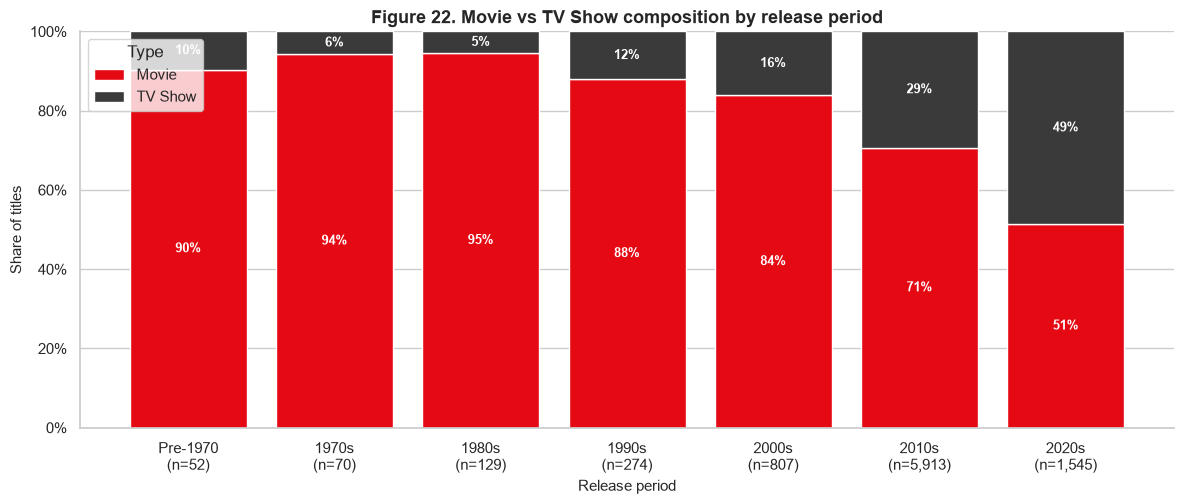

#### Interpretation
- **Observation:** Older release periods in the catalog are almost entirely Movies; the TV Show share grows steadily with release period and is highest for the newest releases.
- **Evidence:** TV Show share by release period: Pre-1970 9.6%, 1970s 5.7%, 1980s 5.4%, 1990s 12.0%, 2000s 16.1%, 2010s 29.3%, 2020s 48.6%.
- **Interpretation:** The release-era composition of the catalog shifts toward series in recent periods.
- **Limitation:** For TV Shows, release_year may refer to the latest season, which pushes series toward recent periods; older TV subgroups are too small for genre-level conclusions. Frequency is not popularity.

In [47]:
tp = pd.crosstab(df["release_period"], df["type"]).reindex(PERIOD_ORDER)
tp = tp[order_types(tp.columns)]
tp_pct = tp.div(tp.sum(axis=1), axis=0) * 100
display(pd.concat([tp, tp_pct.add_suffix(" %").round(1)], axis=1))

# Leading genre per period by type (subgroups with >= MIN_TITLES_YEAR titles)
lead_rows = []
for p in PERIOD_ORDER:
    row = {"period": p}
    for t in ["Movie", "TV Show"]:
        n_pt = int(tp.loc[p, t]) if t in tp.columns else 0
        if n_pt >= MIN_TITLES_YEAR:
            s = G[(G["release_period"] == p) & (G["type"] == t)]["genre"].value_counts()
            row[f"{t}: n"] = n_pt
            row[f"{t}: leading genre"] = f"{s.index[0]} ({pct(s.iloc[0], n_pt):.0f}%)"
        else:
            row[f"{t}: n"] = n_pt
            row[f"{t}: leading genre"] = f"(n < {MIN_TITLES_YEAR}, not reported)"
    lead_rows.append(row)
lead_by_type = pd.DataFrame(lead_rows).set_index("period")
display(lead_by_type)

fig, ax = plt.subplots(figsize=(12, 5.2))
bottom = np.zeros(len(tp_pct))
xl = [f"{p}\n(n={int(tp.loc[p].sum()):,})" for p in tp_pct.index]
for t in tp_pct.columns:
    ax.bar(xl, tp_pct[t].values, bottom=bottom, color=TYPE_COLORS.get(t, "#999"), label=t)
    for i, (v, b) in enumerate(zip(tp_pct[t].values, bottom)):
        if v >= 4:
            ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    bottom += tp_pct[t].values
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 100)
ax.set(title="Figure 22. Movie vs TV Show composition by release period", xlabel="Release period", ylabel="Share of titles")
ax.legend(title="Type", loc="upper left")
save_fig(fig, "22_type_mix_by_release_period.png")
RESULTS.update(tv_share_period_early=float(tp_pct.loc[P_EARLY, "TV Show"]), tv_share_period_late=float(tp_pct.loc[P_LATE, "TV Show"]),
               tv_share_period_prev=float(tp_pct.loc[PERIOD_ORDER[-2], "TV Show"]), lead_by_type=lead_by_type)
interpret(
    "Older release periods in the catalog are almost entirely Movies; the TV Show share grows steadily with release period and is highest for the newest releases.",
    "TV Show share by release period: " + ", ".join(f"{p} {v:.1f}%" for p, v in tp_pct["TV Show"].items()) + ".",
    "The release-era composition of the catalog shifts toward series in recent periods.",
    "For TV Shows, release_year may refer to the latest season, which pushes series toward recent periods; older TV subgroups are too small for genre-level conclusions. Frequency is not popularity.")

### Release Year and Content-Type Popularity Insights
The findings below are generated from the computed tables above (no values are typed by hand). "Popular" means **most frequent in the catalog**, not most watched.

In [48]:
pt = RESULTS["period_table"]; chg = RESULTS["chg"]; P_EARLY = RESULTS["P_EARLY"]; P_LATE = RESULTS["P_LATE"]
gain = chg[(chg[f"{P_EARLY} count"] >= 10) | (chg[f"{P_LATE} count"] >= 10)].nlargest(3, "change (pp)")
loss = chg[(chg[f"{P_EARLY} count"] >= 10) | (chg[f"{P_LATE} count"] >= 10)].nsmallest(3, "change (pp)")
top_late_count_rank = gp_counts.loc[P_LATE].sort_values(ascending=False).index[0]
top_late_share_rank = gp_share.loc[P_LATE].sort_values(ascending=False).index[0]
intl_m = "International Movies"
early_older = [p for p in PERIOD_ORDER[:3]]
lines = [
    "1. **Older releases.** "
    f"*Observation:* the oldest release periods are dominated by curated classic and drama categories. "
    f"*Evidence:* leading genre per period – " + "; ".join(f"{p}: {pt.loc[p, 'top_genre']} ({pt.loc[p, 'top_genre_share_%']:.1f}% of {int(pt.loc[p, 'titles'])} titles)" for p in early_older) + ". "
    "*Interpretation:* older titles retained in the catalog are concentrated in a few heritage categories. "
    "*Limitation:* early periods have small samples and 'Classic' is partly an age-based label.",

    "2. **Newer releases.** "
    f"*Observation:* the categories that gained most share between {P_EARLY} and {P_LATE} are " + ", ".join(f"'{g}'" for g in gain.index) + ". "
    f"*Evidence:* " + "; ".join(f"{g}: {r[f'{P_EARLY} share %']:.1f}% → {r[f'{P_LATE} share %']:.1f}% ({r['change (pp)']:+.1f} pp)" for g, r in gain.iterrows()) +
    f"; largest declines: " + "; ".join(f"{g} {r['change (pp)']:+.1f} pp" for g, r in loss.iterrows()) + ". "
    f"*Interpretation:* the catalog composition shifts toward international and TV categories among recent releases. "
    f"*Limitation:* {P_LATE} contains only the first year(s) of the decade.",

    "3. **Movies vs TV Shows.** "
    f"*Observation:* the composition differs by type and by period. "
    f"*Evidence:* TV Show share rises from {RESULTS['tv_share_period_early']:.1f}% ({P_EARLY}) to {RESULTS['tv_share_period_prev']:.1f}% ({PERIOD_ORDER[-2]}) and "
    f"{RESULTS['tv_share_period_late']:.1f}% ({P_LATE}); top Movie family = {RESULTS['fam_top_movie']} ({RESULTS['fam_top_movie_share']:.1f}% of Movies), "
    f"top TV family = {RESULTS['fam_top_tv']} ({RESULTS['fam_top_tv_share']:.1f}% of TV Shows); {RESULTS['fam_n_sig']} of 10 family differences significant (Bonferroni). "
    "*Interpretation:* recent release periods contain relatively more series, and series carry a different genre mix. "
    "*Limitation:* TV release_year may refer to the latest season; multi-label data weaken formal tests.",

    "4. **Counts vs percentages.** "
    f"*Observation:* raw counts make the 2010s dominate every genre, but shares still show the compositional shift. "
    f"*Evidence:* in {P_LATE} the leading genre by count is '{top_late_count_rank}' and by title share '{top_late_share_rank}'; "
    f"International (Movies + TV) tag share {RESULTS['intl_tag_early']:.1f}% ({P_EARLY}) → {RESULTS['intl_tag_late']:.1f}% ({P_LATE}). "
    "*Interpretation:* the shift toward international/TV categories persists after normalisation, so it is not only a volume effect. "
    "*Limitation:* shares depend on the multi-label tagging scheme.",

    "5. **What cannot be concluded.** "
    "*Observation:* the dataset has no views, watch time, user ratings, engagement or revenue. "
    "*Evidence:* the available columns are limited to show_id, type, title, director, country, date_added, release_year, rating, duration and listed_in. "
    "*Interpretation:* the analysis describes catalog prevalence only; it cannot say which genres audiences preferred or why composition changed. "
    "*Limitation:* any statement about popularity or causation would go beyond the data.",
]
display(Markdown("\n\n".join(lines)))

1. **Older releases.** *Observation:* the oldest release periods are dominated by curated classic and drama categories. *Evidence:* leading genre per period – Pre-1970: Classic Movies (75.0% of 52 titles); 1970s: Classic Movies (45.7% of 70 titles); 1980s: Dramas (44.2% of 129 titles). *Interpretation:* older titles retained in the catalog are concentrated in a few heritage categories. *Limitation:* early periods have small samples and 'Classic' is partly an age-based label.

2. **Newer releases.** *Observation:* the categories that gained most share between Pre-1970 and 2020s are 'International TV Shows', 'TV Dramas', 'TV Comedies'. *Evidence:* International TV Shows: 0.0% → 23.5% (+23.5 pp); TV Dramas: 0.0% → 13.6% (+13.6 pp); TV Comedies: 1.9% → 11.5% (+9.5 pp); largest declines: Classic Movies -75.0 pp; Dramas -25.7 pp; Documentaries -16.6 pp. *Interpretation:* the catalog composition shifts toward international and TV categories among recent releases. *Limitation:* 2020s contains only the first year(s) of the decade.

3. **Movies vs TV Shows.** *Observation:* the composition differs by type and by period. *Evidence:* TV Show share rises from 9.6% (Pre-1970) to 29.3% (2010s) and 48.6% (2020s); top Movie family = International (44.9% of Movies), top TV family = International (50.6% of TV Shows); 9 of 10 family differences significant (Bonferroni). *Interpretation:* recent release periods contain relatively more series, and series carry a different genre mix. *Limitation:* TV release_year may refer to the latest season; multi-label data weaken formal tests.

4. **Counts vs percentages.** *Observation:* raw counts make the 2010s dominate every genre, but shares still show the compositional shift. *Evidence:* in 2020s the leading genre by count is 'International Movies' and by title share 'International Movies'; International (Movies + TV) tag share 9.6% (Pre-1970) → 21.9% (2020s). *Interpretation:* the shift toward international/TV categories persists after normalisation, so it is not only a volume effect. *Limitation:* shares depend on the multi-label tagging scheme.

5. **What cannot be concluded.** *Observation:* the dataset has no views, watch time, user ratings, engagement or revenue. *Evidence:* the available columns are limited to show_id, type, title, director, country, date_added, release_year, rating, duration and listed_in. *Interpretation:* the analysis describes catalog prevalence only; it cannot say which genres audiences preferred or why composition changed. *Limitation:* any statement about popularity or causation would go beyond the data.

## 10. Key Findings
Every statement below is generated from metrics computed earlier in the notebook. Format: **Observation – Evidence – Interpretation – Limitation**.

In [49]:
R = RESULTS
def kf(i, title, obs, ev, interp, lim):
    return (f"**{i}. {title}**\n"
            f"- **Observation:** {obs}\n- **Evidence:** {ev}\n- **Interpretation:** {interp}\n- **Limitation:** {lim}\n")

add_tot_ = R["add_tot"]
findings = [
    kf(1, "Movies dominate the catalog by title count",
       "Movies are the majority of records.",
       f"{R['n_movie']:,} Movies ({pct(R['n_movie'], R['N']):.1f}%) vs {R['n_tv']:,} TV Shows ({pct(R['n_tv'], R['N']):.1f}%) out of {R['N']:,} titles.",
       "The catalog snapshot is weighted toward films in terms of number of titles.",
       "Counting titles ignores episodes and runtime."),
    kf(2, "Most titles were added in the late 2010s",
       f"Additions rose sharply from {R['first_elig_add_year']} and peaked in {R['peak_add_year']}.",
       f"Peak {R['peak_add_year']}: {R['peak_add_n']:,} titles; only {R['pre_first_add']:,} titles were added before {R['first_elig_add_year']}; "
       f"half of the dated catalog had been added by the end of {R['half_catalog_year']}. Last recorded date: {R['last_date'].date()}"
       + (" (final year incomplete)." if R['last_year_partial'] else "."),
       "Among titles currently listed, catalog entry is concentrated in a few recent years.",
       "Removed titles are not in the snapshot, so earlier years are under-represented."),
    kf(3, "The TV Show share of additions is higher in recent years",
       "Movies lead every eligible year, but the share of TV Shows among additions changes over time.",
       f"TV Show share: {R['mix_y_first']} {R['tv_share_first']:.1f}% → minimum {R['tv_share_min']:.1f}% in {R['tv_share_min_year']} → "
       f"{R['mix_y_last']} {R['tv_share_last']:.1f}% (years with ≥{MIN_N_TREND} additions).",
       "Recently added titles include proportionally more series.",
       "Descriptive only; the data do not explain why the mix changed."),
    kf(4, "The catalog consists mainly of recent releases",
       "Most titles were released in the 2010s or later and are added soon after release.",
       f"{R['share_rel_2010']:.1f}% released in 2010 or later; median release year {R['median_release']:.0f} (oldest {R['min_release']}); "
       f"median gap between release and addition {R['median_lag_overall']:.0f} year(s); share added within one year of release "
       f"{R['share_within_1yr_first']:.1f}% ({R['age_y_first']}) → {R['share_within_1yr_last']:.1f}% ({R['age_y_last']}).",
       "The catalog snapshot emphasises contemporary content.",
       f"Year-level precision only; {R['n_added_before_release']} titles have added_year < release_year."),
    kf(5, "Strong geographic concentration",
       f"{R['top_country']} and {R['second_country']} are the leading production countries.",
       f"{R['top_country']}: {R['top_country_n']:,} titles ({pct(R['top_country_n'], R['N']):.1f}%); {R['second_country']}: "
       f"{R['second_country_n']:,} ({pct(R['second_country_n'], R['N']):.1f}%); top 10 countries cover {R['top10_country_share']:.1f}% of titles; "
       f"{R['n_unknown_country']:,} titles have no country.",
       "Catalog content is concentrated in a small number of production countries.",
       "Co-productions appear reduced to a single country; regional catalogs differ."),
    kf(6, "International, drama and comedy categories are the most prevalent",
       f"'{R['top_genre']}' is the most frequent category.",
       f"{R['top_genre']}: {R['top_genre_n']:,} ({pct(R['top_genre_n'], R['N']):.1f}% of titles); {R['genre2']}: {R['genre2_n']:,} "
       f"({pct(R['genre2_n'], R['N']):.1f}%); {R['genre3']}: {R['genre3_n']:,} ({pct(R['genre3_n'], R['N']):.1f}%); "
       f"{R['tags_per_title']:.2f} categories per title on average.",
       "By title count, the catalog is rich in international and general-audience narrative genres.",
       "Prevalence is not popularity; categories overlap (multi-label)."),
    kf(7, "Mature ratings dominate",
       f"{R['top_rating']} is the most common rating.",
       f"{R['top_rating']}: {R['top_rating_n']:,} ({pct(R['top_rating_n'], R['N']):.1f}%); {R['rating2']}: {R['rating2_n']:,} "
       f"({pct(R['rating2_n'], R['N']):.1f}%); mature ratings (TV-MA/R/NC-17) {R['mature_share']:.1f}% vs children/general ratings {R['youth_share']:.1f}%.",
       "The catalog leans toward adult and teen audiences by title count.",
       "Two rating systems are mixed; ratings can vary by country."),
    kf(8, "Movie runtimes are standardised and only weakly related to release year",
       "Runtimes cluster around feature length; older release periods have somewhat longer medians.",
       f"Median {R['movie_median']:.0f} min (IQR {R['movie_q1']:.0f}–{R['movie_q3']:.0f}, n = {R['movie_n']:,}); "
       f"{R['share_80_120']:.1f}% between 80 and 120 min; median {R['dur_longest_median']:.0f} min in {R['dur_longest_period']} vs "
       f"{R['dur_shortest_median']:.0f} min in {R['dur_shortest_period']}; Pearson r(release_year, runtime) = {R['r_movie_dur_release']:.3f} "
       f"(Spearman {R['rho_movie_dur_release']:.3f}, {strength(R['r_movie_dur_release'])}).",
       "Newer catalog films are slightly shorter on average, but release year explains little of the variation.",
       "Correlation is not causation; old films in the catalog are a selected subset."),
    kf(9, "Most TV Shows have a single season",
       "The season distribution is strongly right-skewed.",
       f"{R['tv_one_share']:.1f}% of TV Shows have 1 season and {R['tv_le2_share']:.1f}% have at most 2 (n = {R['tv_n']:,}; "
       f"mean {R['tv_mean']:.2f}, max {R['tv_max']}); r(release_year, seasons) = {R['r_tv_seasons_release']:.3f} ({strength(R['r_tv_seasons_release'])}).",
       "The TV catalog is dominated by short or new series.",
       "Season counts are right-censored at snapshot time."),
    kf(10, "Genre composition shifts with release era",
       f"Among the oldest releases ({R['P_EARLY']}) '{R['period_table'].loc[R['P_EARLY'], 'top_genre']}' leads; among the newest ({R['P_LATE']}) "
       f"'{R['period_table'].loc[R['P_LATE'], 'top_genre']}' leads.",
       f"{R['P_EARLY']}: {R['period_table'].loc[R['P_EARLY'], 'top_genre_share_%']:.1f}% of {int(R['titles_per'][R['P_EARLY']])} titles; "
       f"{R['P_LATE']}: {R['period_table'].loc[R['P_LATE'], 'top_genre_share_%']:.1f}% of {int(R['titles_per'][R['P_LATE']]):,} titles; "
       f"International tag share {R['intl_tag_early']:.1f}% → {R['intl_tag_late']:.1f}%; TV Show share by release period "
       f"{R['tv_share_period_early']:.1f}% → {R['tv_share_period_late']:.1f}%.",
       "The catalog composition moves from classic films toward international and TV content across release eras.",
       "Catalog prevalence is a proxy; it does not measure audience preference, and the early period is small."),
]
display(Markdown("\n".join(findings)))
display(Markdown("*Hypothesis (not a recommendation):* the descriptive evidence is consistent with a catalog that emphasises recent, "
                 "international and series content; testing any business explanation would require viewing and licensing data that this dataset does not contain."))

**1. Movies dominate the catalog by title count**
- **Observation:** Movies are the majority of records.
- **Evidence:** 6,126 Movies (69.7%) vs 2,664 TV Shows (30.3%) out of 8,790 titles.
- **Interpretation:** The catalog snapshot is weighted toward films in terms of number of titles.
- **Limitation:** Counting titles ignores episodes and runtime.

**2. Most titles were added in the late 2010s**
- **Observation:** Additions rose sharply from 2015 and peaked in 2019.
- **Evidence:** Peak 2019: 2,016 titles; only 56 titles were added before 2015; half of the dated catalog had been added by the end of 2019. Last recorded date: 2021-09-25 (final year incomplete).
- **Interpretation:** Among titles currently listed, catalog entry is concentrated in a few recent years.
- **Limitation:** Removed titles are not in the snapshot, so earlier years are under-represented.

**3. The TV Show share of additions is higher in recent years**
- **Observation:** Movies lead every eligible year, but the share of TV Shows among additions changes over time.
- **Evidence:** TV Show share: 2015 31.7% → minimum 24.9% in 2018 → 2021 33.7% (years with ≥30 additions).
- **Interpretation:** Recently added titles include proportionally more series.
- **Limitation:** Descriptive only; the data do not explain why the mix changed.

**4. The catalog consists mainly of recent releases**
- **Observation:** Most titles were released in the 2010s or later and are added soon after release.
- **Evidence:** 84.8% released in 2010 or later; median release year 2017 (oldest 1925); median gap between release and addition 1 year(s); share added within one year of release 81.7% (2015) → 50.8% (2021).
- **Interpretation:** The catalog snapshot emphasises contemporary content.
- **Limitation:** Year-level precision only; 14 titles have added_year < release_year.

**5. Strong geographic concentration**
- **Observation:** United States and India are the leading production countries.
- **Evidence:** United States: 3,240 titles (36.9%); India: 1,057 (12.0%); top 10 countries cover 75.5% of titles; 287 titles have no country.
- **Interpretation:** Catalog content is concentrated in a small number of production countries.
- **Limitation:** Co-productions appear reduced to a single country; regional catalogs differ.

**6. International, drama and comedy categories are the most prevalent**
- **Observation:** 'International Movies' is the most frequent category.
- **Evidence:** International Movies: 2,752 (31.3% of titles); Dramas: 2,426 (27.6%); Comedies: 1,674 (19.0%); 2.19 categories per title on average.
- **Interpretation:** By title count, the catalog is rich in international and general-audience narrative genres.
- **Limitation:** Prevalence is not popularity; categories overlap (multi-label).

**7. Mature ratings dominate**
- **Observation:** TV-MA is the most common rating.
- **Evidence:** TV-MA: 3,205 (36.5%); TV-14: 2,157 (24.5%); mature ratings (TV-MA/R/NC-17) 45.6% vs children/general ratings 10.3%.
- **Interpretation:** The catalog leans toward adult and teen audiences by title count.
- **Limitation:** Two rating systems are mixed; ratings can vary by country.

**8. Movie runtimes are standardised and only weakly related to release year**
- **Observation:** Runtimes cluster around feature length; older release periods have somewhat longer medians.
- **Evidence:** Median 98 min (IQR 87–114, n = 6,126); 64.2% between 80 and 120 min; median 114 min in 1970s vs 97 min in 2010s; Pearson r(release_year, runtime) = -0.206 (Spearman -0.191, weak).
- **Interpretation:** Newer catalog films are slightly shorter on average, but release year explains little of the variation.
- **Limitation:** Correlation is not causation; old films in the catalog are a selected subset.

**9. Most TV Shows have a single season**
- **Observation:** The season distribution is strongly right-skewed.
- **Evidence:** 67.2% of TV Shows have 1 season and 83.0% have at most 2 (n = 2,664; mean 1.75, max 17); r(release_year, seasons) = -0.082 (negligible).
- **Interpretation:** The TV catalog is dominated by short or new series.
- **Limitation:** Season counts are right-censored at snapshot time.

**10. Genre composition shifts with release era**
- **Observation:** Among the oldest releases (Pre-1970) 'Classic Movies' leads; among the newest (2020s) 'International Movies' leads.
- **Evidence:** Pre-1970: 75.0% of 52 titles; 2020s: 24.6% of 1,545 titles; International tag share 9.6% → 21.9%; TV Show share by release period 9.6% → 48.6%.
- **Interpretation:** The catalog composition moves from classic films toward international and TV content across release eras.
- **Limitation:** Catalog prevalence is a proxy; it does not measure audience preference, and the early period is small.


*Hypothesis (not a recommendation):* the descriptive evidence is consistent with a catalog that emphasises recent, international and series content; testing any business explanation would require viewing and licensing data that this dataset does not contain.

## 11. Limitations and Conclusion

**Limitations**

1. **Catalog snapshot, not a full history.** The file lists titles available at one point in time. Titles that were added and later removed are absent, so earlier addition years are under-represented and growth may be overstated.
2. **Coverage.** The dataset may not represent all regions or all content; Netflix catalogs differ by country.
3. **Missing and placeholder values.** `director` and `country` contain placeholders (`Not Given`), which were treated as unknown and excluded from rankings; this can bias top-k lists.
4. **Multi-value fields.** `listed_in` (and potentially `country`, `director`) are multi-valued. Exploding them means genre shares overlap and do not sum to 100%. Co-productions appear to be represented by a single country in this file.
5. **Two time variables.** `date_added` / `added_year` answers *when content entered the catalog*; `release_year` answers *when content was made*. They are not interchangeable. For TV Shows, `release_year` may correspond to a recent season.
6. **Different duration units.** Movie minutes and TV seasons are different measurements on different populations and were never combined. Season counts are right-censored.
7. **Correlation ≠ causation.** All correlations are descriptive, mostly weak, and partly structural (e.g. a title cannot usually be added before release).
8. **Genre frequency ≠ popularity.** Genre frequency is used only as a proxy for catalog prevalence. The dataset does **not** include views, watch time, user ratings, audience engagement or revenue, so audience popularity cannot be measured directly.
9. **Small samples.** Early years/decades contain few titles; sample-size rules (`MIN_N_TREND` = 30, `MIN_TITLES_YEAR` = 20, `MIN_TITLES_PERIOD` = 50) were applied and sparse decades pooled.
10. **Possible re-listings.** A few rows are identical except for `show_id`; they were kept because they cannot be proven erroneous.

**Conclusion.** The Netflix catalog snapshot is film-heavy, dominated by recent releases, mature ratings, and a small set of production countries led by the United States and India. Most titles entered the catalog in the second half of the 2010s, with recently added titles including relatively more TV Shows. Across release eras, the catalog composition moves from classic and drama films toward international and TV categories, and this shift survives normalisation by period size. Numeric relationships are weak: newer films are only slightly shorter, and season counts are essentially unrelated to release year. All findings describe patterns in the catalog; they do not identify causes or audience preferences.

## 12. Final Reproducibility Check
The cell below verifies programmatically that the analysis completed as intended. If any check fails, an `AssertionError` is raised so that the failure is visible.

In [50]:
REQUIRED_FIGURES = [
    "01_type_distribution.png", "02_titles_added_by_year_type.png", "03_titles_released_by_year_type.png",
    "04_top10_countries.png", "05_top10_genres.png", "06_rating_distribution.png",
    "07_movie_duration_distribution.png", "08_tv_seasons_distribution.png", "09_monthly_seasonality.png",
    "10_correlation_heatmaps.png", "18_genre_heatmap_by_release_period.png", "19_genre_share_stacked_by_period.png",
    "20_top5_genres_by_release_year.png", "21_movie_vs_tv_genre_families.png",
]
REQUIRED_COLUMNS = ["date_added", "added_year", "added_month", "added_month_name", "duration_value",
                    "movie_duration_minutes", "tv_seasons", "release_decade", "release_period", "years_to_add"]

checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "passed": bool(ok), "detail": detail})

check("Analysis dataframe `df` exists", isinstance(globals().get("df"), pd.DataFrame), f"shape={df.shape}")
check("No rows dropped from analysis copy", len(df) == len(df_raw), f"{len(df):,} vs {len(df_raw):,}")
missing_cols = [c for c in REQUIRED_COLUMNS if c not in df.columns]
check("Required derived columns exist", not missing_cols, f"missing={missing_cols}")
check("date_added converted to datetime", pd.api.types.is_datetime64_any_dtype(df["date_added"]), str(df["date_added"].dtype))
check("Movie minutes only on Movies", df.loc[~is_movie, "movie_duration_minutes"].isna().all(), "")
check("TV seasons only on TV Shows", df.loc[~is_tv, "tv_seasons"].isna().all(), "")
now_fp = int(pd.util.hash_pandas_object(df_raw, index=True).sum())
check("df_raw unchanged (hash)", now_fp == RAW_FINGERPRINT, f"{now_fp} == {RAW_FINGERPRINT}")
check("df_raw shape and dtypes unchanged", df_raw.shape == RAW_SHAPE and df_raw.dtypes.astype(str).to_dict() == RAW_DTYPES, str(df_raw.shape))
fig_status = {f: (FIG_DIR / f).is_file() and (FIG_DIR / f).stat().st_size > 0 and (FIG_DIR / f).stat().st_mtime >= RUN_START - 1
              for f in REQUIRED_FIGURES}
check("All required figures created in this run", all(fig_status.values()), f"missing={[f for f, ok in fig_status.items() if not ok]}")
all_created_ok = all(Path(p).is_file() and Path(p).stat().st_mtime >= RUN_START - 1 for p in FIGURES_CREATED)
check("All registered figures saved in this run", all_created_ok, f"{len(FIGURES_CREATED)} figures")
check("Figure folder is a relative path", not FIG_DIR.is_absolute(), FIG_DIR.as_posix())
check("Dataset located via portable search", DATA_PATH in SEARCHED_PATHS,
      f"{DATA_PATH.as_posix()} ({'relative' if not DATA_PATH.is_absolute() else 'absolute fallback'})")
check("Exploded tables cover every title", all(t["show_id"].nunique() == len(df) for t in [country_long, genre_long, director_long]), "")

check_df = pd.DataFrame(checks)
display(check_df)
print(f"Figures created ({len(FIGURES_CREATED)}):")
for p in FIGURES_CREATED:
    print("  -", p)
assert check_df["passed"].all(), "One or more reproducibility checks failed."
print(f"\nAll {len(check_df)} checks passed. Reaching this cell means every preceding cell executed without errors.")

,check,passed,detail
0,Analysis dataframe `df` exists,True,"shape=(8790, 23)"
1,No rows dropped from analysis copy,True,"8,790 vs 8,790"
2,Required derived columns exist,True,missing=[]
3,date_added converted to datetime,True,datetime64[us]
4,Movie minutes only on Movies,True,
5,TV seasons only on TV Shows,True,
6,df_raw unchanged (hash),True,13371421083196330586 == 13371421083196330586
7,df_raw shape and dtypes unchanged,True,"(8790, 10)"
8,All required figures created in this run,True,missing=[]
9,All registered figures saved in this run,True,22 figures


Figures created (22):
  - figures/01_type_distribution.png
  - figures/02_titles_added_by_year_type.png
  - figures/03_titles_released_by_year_type.png
  - figures/04_top10_countries.png
  - figures/05_top10_genres.png
  - figures/06_rating_distribution.png
  - figures/07_movie_duration_distribution.png
  - figures/08_tv_seasons_distribution.png
  - figures/09_monthly_seasonality.png
  - figures/10_correlation_heatmaps.png
  - figures/11_movie_runtime_vs_release_year.png
  - figures/12_cumulative_titles_added.png
  - figures/13_type_mix_by_added_year.png
  - figures/14_release_year_by_added_year.png
  - figures/15_rating_share_by_type.png
  - figures/16_movie_runtime_by_period.png
  - figures/17_tv_seasons_by_added_year.png
  - figures/18_genre_heatmap_by_release_period.png
  - figures/19_genre_share_stacked_by_period.png
  - figures/20_top5_genres_by_release_year.png
  - figures/21_movie_vs_tv_genre_families.png
  - figures/22_type_mix_by_release_period.png

All 13 checks passed. Reac